# <span style="color:#9947dc">HI-Small — Data Build and Exploratory Data Analysis (v2)</span>

**What this notebook is.** One place that walks through our data from start to finish:

| Part | What happens | Main file |
|---|---|---|
| **A** | How the joined file was built, and the checks that prove it is right | `01_join_sql.py`, `01b_verify_join.py` |
| **B** | EDA on the **full** joined file — every transaction, no sampling | `hi_small_joined.parquet` |
| **C** | How the smaller sample was built, and the checks that prove it is right | `02_subsample_split.py`, `02b_verify_sample.py` |
| **D** | EDA on the **sample** — what you must know before using it for preprocessing, modelling and the agent | `sample.parquet` / `sample.csv`, `accounts.parquet` |

**The one rule to remember.** Part B is where we *discover* what separates laundering from normal
transfers, because it uses all 5 million rows. Part D does **not** repeat that. The sample was
built on purpose to contain far more laundering than reality, so its raw numbers are misleading.
Part D answers a different question: *is the sample safe to use, and what are the traps?*

**How to read each section.** Every section has the same four parts:
- **Why** — the question we are asking, in plain words.
- **How** — what the code does.
- **What the output shows** — the numbers, copied from the output directly above. If a number in
  the text does not appear in the output above it, that is a mistake — tell the team.
- **What it means for us** — the decision it leads to.

**How to run it — one file does everything.** Put the three raw csv files in `data/raw/`, open this
notebook from inside the project folder, and **Run All**. Step 0 (just below the setup cell) runs
the four pipeline scripts for you — join, verify, sample, verify, plus the train / val / test split —
but only the steps whose files are missing, so the second time it goes straight to the EDA.
If you already have the parquet files and no raw files, it simply reads them.

**Needs:** `pip install duckdb pyarrow pandas matplotlib scikit-learn`. Heavy counting is done in
**DuckDB** (SQL over the parquet file), so the 5-million-row file never has to be loaded fully into
memory.

## Contents

**Step 0 — Build the data** (runs the pipeline scripts if their files are missing)

**Part A — Building the joined file**
- [A1. The three raw files and why we join them](#a1) · [A2. Checking the join](#a2)

**Part B — EDA on the full joined file**
0. [Data quality and column profile](#b0) · 1. [Time window and the leftover tail](#b1) · 2. [How rare laundering is](#b2)
3. [Checking the labels against the patterns file](#b3) · 3b. [Where the unexplained laundering sits](#b3b)
4. [What a laundering scheme looks like](#b4) · 4b. [Schemes in more detail](#b4b) · 5. [Payment format](#b5)
6. [Amounts and currencies](#b6) · 6b. [Amounts in one currency, risk by amount size](#b6b) · 7. [Self-transfers](#b7)
8. [Same bank vs different bank](#b8) · 9. [Countries and cross-border](#b9) · 10. [Entities](#b10)
11. [Account network and hub accounts](#b11) · 11b. [Account shape](#b11b) · 11c. [New vs repeat counterparties](#b11c)
12. [Speed (time between transfers)](#b12) · 12b. [Point-in-time behaviour: account view vs transfer view](#b12b)
13. [Pass-through — corrected](#b13) · 14. [Structuring (round and repeated amounts)](#b14) · 15. [How long accounts stay active](#b15)
16. [Pictures of real schemes](#b16) · 16b. [Can we split by time?](#b16b) · 16c. [Which single features separate best?](#b16c)
17. [Summary of signals](#b17)

**Part C — Building the sample**
- [C1. Why and how we sample](#c1) · [C2. Checking the sample](#c2)

**Part D — EDA on the sample**
0. [First look at the sample files](#d0) · 1. [What the extra columns mean](#d1) · 2. [Raw numbers lie, weighted numbers don't](#d2) · 3. [The weights](#d3)
4. [Full history vs partial history](#d4) · 4b. [Features from the sample vs the full file](#d4b) · 5. [Leakage audit](#d5) · 6. [Time split preview](#d6)
7. [Schemes available for the agent](#d7) · 8. [Do the signals hold every day?](#d8) · 9. [What the agent can and cannot see](#d9) · 9b. [A sample case](#d9b)
10. [Handoff: rules for preprocessing, modelling and the agent](#d10)

In [1]:
import sys
import subprocess
import warnings
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)


def find_root():
    """Project root = the folder that has src/eda_utils.py and notebook/ in it.
    Works whether Jupyter starts in notebook/ or at the project root."""
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "src" / "eda_utils.py").exists() and (p / "notebook").is_dir():
            return p
    raise FileNotFoundError("Open this notebook from inside the project folder "
                            "(the one with src/eda_utils.py and notebook/ in it).")


ROOT = find_root()
sys.path.insert(0, str(ROOT / "src"))
import eda_utils as eu  # only used for the scheme drawings

con = duckdb.connect()
con.execute("SET memory_limit = '4GB'")
con.execute("SET threads = 4")


def sql(query):
    """Run SQL, get a pandas DataFrame back."""
    return con.execute(query).df()


def one(query):
    """Run SQL that returns a single number."""
    return con.execute(query).fetchone()[0]


def risk_by(col, where="TRUE", min_rows=0):
    """Rows, laundering, rate and shares per value of `col` in the full file."""
    df = sql(f"""
        SELECT {col} AS value, COUNT(*) AS rows, SUM("Is Laundering") AS laundering
        FROM j WHERE {where} GROUP BY 1 HAVING COUNT(*) >= {min_rows}
    """)
    df["rate_pct"] = 100 * df["laundering"] / df["rows"]
    df["share_of_laundering_pct"] = 100 * df["laundering"] / df["laundering"].sum()
    df["share_of_rows_pct"] = 100 * df["rows"] / df["rows"].sum()
    return df.sort_values(["rate_pct", "value"], ascending=[False, True]).reset_index(drop=True)


PURPLE, LILAC, DARK, GREY = "#9947dc", "#c9a7f0", "#6b21a8", "#9ca3af"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11})


def fmt_int(df, cols):
    """Thousands separators for display only."""
    out = df.copy()
    for c in cols:
        out[c] = out[c].map(lambda v: f"{v:,.0f}" if pd.notna(v) else "")
    return out


print("project root:", ROOT)
print("duckdb", duckdb.__version__, "| pandas", pd.__version__)

project root: /home/claude/fresh
duckdb 2.0.0 | pandas 3.0.5


## <span style="color:#9947dc">Step 0 — Build the data (runs the pipeline scripts)</span>

**What this does.** Everything in this notebook reads files made by four scripts in `notebook/`.
The next cell runs them for you, in the right order, and **stops with an error if any check fails**:

| Order | Script | Makes | Its check must say |
|---|---|---|---|
| 1 | `01_join_sql.py` | `data/processed/hi_small_joined.parquet` (+ .csv) | rows 5,078,336 · positives 5,177 · 3,209 scheme rows |
| 2 | `01b_verify_join.py` | — (checks only) | all checks passed |
| 3 | `02_subsample_split.py` | `data/processed/sample/sample/` (one-file sample) | fingerprint `4fb17c9f351dbaea0bf766c55f055f60` |
| 4 | `02b_verify_sample.py` | — | all checks passed |
| 5 | `02_subsample_split.py time` | `data/processed/sample/time/` (train / val / test for modelling) | same fingerprint |
| 6 | `02b_verify_sample.py time` | — | all checks passed |

**The settings at the top of the next cell:**
- `BUILD = "auto"` (default) — run only the steps whose output file is missing. On a fresh machine
  that means everything (several minutes); after that, the cell skips straight to the EDA.
- `BUILD = "all"` — rebuild everything from the raw files.
- `BUILD = "none"` — never run the scripts, only read the files.
- `RUN_CHECKS = True` — also run the two verify scripts after building. `01b_verify_join.py` loads the
  1.3 GB CSV into pandas and needs a fair amount of memory; set `False` to skip it on a small laptop.
- `MAKE_TIME_SPLIT = True` — also build the train / val / test split that modelling uses.

**Needs:** the three raw files in `data/raw/` (`HI-Small_Trans.csv`, `HI-Small_accounts.csv`,
`HI-Small_Patterns.txt`, from Kaggle `ealtman2019/ibm-transactions-for-anti-money-laundering-aml`)
and `pip install duckdb pyarrow pandas matplotlib scikit-learn`.

In [2]:
import re
import time

BUILD = "auto"          # "auto" | "all" | "none"
RUN_CHECKS = True       # run the 01b / 02b verify scripts after building
MAKE_TIME_SPLIT = True  # also build data/processed/sample/time/ (train / val / test)

EXPECTED_FINGERPRINT = "4fb17c9f351dbaea0bf766c55f055f60"
RAW_DIR = ROOT / "data" / "raw"
PROC = ROOT / "data" / "processed"
LOGS = {}   # each script's output, shown again in Parts A and C


def run_script(name, *args):
    # Run one pipeline script, print its output live, stop the notebook if it fails.
    label = " ".join([name, *args])
    print(f"\n{'=' * 70}\n>>> python notebook/{label}\n{'=' * 70}", flush=True)
    t0 = time.time()
    proc = subprocess.Popen([sys.executable, "-u", str(ROOT / "notebook" / name), *args], cwd=ROOT,
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            text=True, encoding="utf-8", errors="replace")
    lines = []
    for line in proc.stdout:
        if "\r" in line or "▏" in line:   # skip DuckDB progress bars
            continue
        lines.append(line)
        print(line, end="", flush=True)
    proc.wait()
    out = "".join(lines)
    LOGS[label] = out
    if proc.returncode != 0:
        raise RuntimeError(f"{label} FAILED (exit code {proc.returncode}) - read the error above.")
    passed = re.findall(r"(\d+)\s*/\s*(\d+) checks passed", out)
    if passed and passed[-1][0] != passed[-1][1]:
        raise RuntimeError(f"{label}: only {passed[-1][0]} / {passed[-1][1]} checks passed - stop and investigate.")
    fp = re.findall(r"SAMPLE FINGERPRINT: ([0-9a-f]{32})", out)
    if fp:
        same = fp[-1] == EXPECTED_FINGERPRINT
        print(f"\nfingerprint {'MATCHES' if same else 'DIFFERS from'} the team's ({EXPECTED_FINGERPRINT})"
              + ("" if same else " - your joined file or raw data is not the same as ours"))
    print(f"[{label}: done in {time.time() - t0:.0f} s]")


plan = [  # (script, args, file that proves it ran, is_check)
    ("01_join_sql.py", [], PROC / "hi_small_joined.parquet", False),
    ("01b_verify_join.py", [], None, True),
    ("02_subsample_split.py", [], PROC / "sample" / "sample" / "sample.parquet", False),
    ("02b_verify_sample.py", [], None, True),
]
if MAKE_TIME_SPLIT:
    plan += [("02_subsample_split.py", ["time"], PROC / "sample" / "time" / "test.parquet", False),
             ("02b_verify_sample.py", ["time"], None, True)]

if BUILD not in ("auto", "all", "none"):
    raise ValueError("BUILD must be 'auto', 'all' or 'none'")

last_build_ran = False
upstream_rebuilt = False   # if the joined file is rebuilt, everything after it is rebuilt too
for script, args, output, is_check in plan:
    if is_check:
        if last_build_ran and RUN_CHECKS:
            run_script(script, *args)
        continue
    needed = BUILD == "all" or (BUILD == "auto" and (not output.exists() or upstream_rebuilt))
    if needed and script == "01_join_sql.py":
        missing = [f for f in ["HI-Small_Trans.csv", "HI-Small_accounts.csv", "HI-Small_Patterns.txt"]
                   if not (RAW_DIR / f).exists()]
        if missing:
            raise FileNotFoundError(f"Missing raw files in {RAW_DIR}: {missing}. Download them from Kaggle "
                                    "(ealtman2019/ibm-transactions-for-anti-money-laundering-aml).")
    if needed:
        run_script(script, *args)
        upstream_rebuilt = True
    else:
        print(f"skip {' '.join([script, *args])}: {output.relative_to(ROOT)} already exists")
    last_build_ran = needed

for f in [PROC / "hi_small_joined.parquet", PROC / "sample" / "sample" / "sample.parquet",
          PROC / "sample" / "sample" / "accounts.parquet"]:
    if not f.exists():
        raise FileNotFoundError(f"{f} is missing - set BUILD = 'auto' and run this cell again.")
print("\nAll data files present. The EDA below reads them.")


>>> python notebook/01_join_sql.py


[   0.0s] reading transactions...


[   2.7s] transactions: 5,078,345 rows


[   4.5s] after removing duplicates: 5,078,336 (9 dropped)


[   4.5s] reading accounts...


...

train 465933 1995.0     0.428  0.0616      124          0


  val  74996  323.0     0.431  0.0669       31          1


 test 209116 2204.0     1.054  0.1643      208        101


36 / 36 checks passed


[02b_verify_sample.py time: done in 12 s]

All data files present. The EDA below reads them.


In [3]:
JOINED = (PROC / "hi_small_joined.parquet").as_posix()
SAMPLE_DIR = PROC / "sample" / "sample"
SAMPLE = (SAMPLE_DIR / "sample.parquet").as_posix()
ACCOUNTS = (SAMPLE_DIR / "accounts.parquet").as_posix()

# Views: SQL names for the files. Nothing is loaded into memory yet.
#   j    = full joined file (5M rows) + account keys "bank:account"
#   s    = the sample (750k rows)
#   sacc = one row per account in the sample
con.execute(f'''
    CREATE OR REPLACE VIEW j AS
    SELECT *,
           CAST("From Bank" AS VARCHAR) || ':' || "Account"   AS acct_from,
           CAST("To Bank"   AS VARCHAR) || ':' || "Account.1" AS acct_to
    FROM '{JOINED}'
''')
con.execute(f"CREATE OR REPLACE VIEW s AS SELECT * FROM '{SAMPLE}'")
con.execute(f"CREATE OR REPLACE VIEW sacc AS SELECT * FROM '{ACCOUNTS}'")


def show_log(label, start=None):
    # Print a script's report from the build cell (from the line `start` onwards), if it ran this session.
    if label not in LOGS:
        print(f"({label} did not run in this session - its output file already existed. "
              "Set BUILD = 'all' in the build cell to see its full report here.)\n")
        return
    out = LOGS[label]
    if start and start in out:
        out = out[out.index(start):]
    print(out)


print("views ready: j (full file), s (sample), sacc (sample accounts)")

views ready: j (full file), s (sample), sacc (sample accounts)


---
# <span style="color:#9947dc">Part A — Building the joined file</span>

<a id="a1"></a>
## <span style="color:#9947dc">A1. The three raw files and why we join them</span>

**Why.** The IBM dataset gives us three separate files. None of them is enough on its own:

| Raw file | What one row is | What it is missing |
|---|---|---|
| `HI-Small_Trans.csv` | one money transfer: when, from which account, to which account, how much, which currency, which payment method, and the label `Is Laundering` | **who** owns the accounts, which bank by name, which country |
| `HI-Small_accounts.csv` | one bank account: bank name, bank ID, account number, owner (entity) ID and name | anything about money |
| `HI-Small_Patterns.txt` | the "answer key": the transfers that belong to each laundering **scheme**, grouped into blocks with the scheme type (FAN-OUT, CYCLE, ...) | it is text blocks, not a table |

To ask questions like *"is laundering more common across borders?"* or *"which transfers belong to
the same scheme?"* we need all three glued together into one table. That is what the join does.

**How — what `01_join_sql.py` does, step by step.**
1. **Reads the transfers.** The CSV has two columns both called `Account` (sender and receiver). The
   script names the receiver one `Account.1`, and forces every ID to stay **text**. If an ID like
   `100428660` is read as a number, leading zeros and letters get lost and joins silently fail.
2. **Removes 9 exact duplicate rows.** They are tiny Bitcoin transfers written twice in the same
   minute, none of them laundering — a glitch of the data generator. 5,078,345 → 5,078,336 rows.
3. **Attaches the account details twice** — once for the sender, once for the receiver. The key is
   **(bank ID, account number) together**, because 8 account numbers exist at two different banks.
   Using the account number alone would attach the wrong owner to some rows.
4. **Adds country and entity type.** Foreign banks are named like `"Japan Bank #123"`, so the
   country is read from the name. Banks without a country in the name are labelled `Domestic/Other`.
   Entity names look like `"Corporation #34854"`, so the type is the part before `#`.
5. **Attaches the scheme answer key** (`Attempt ID`, `Pattern Type`) by matching on time, both
   banks, both accounts and amount. Bank codes in the text file have leading zeros (`021174`) and
   in the CSV they don't (`21174`), so both are converted to numbers first.
6. **Adds four yes/no flags**: `self_transfer` (an account paying itself), `same_entity` (same owner
   on both sides), `cross_bank` (different bank **name**), `cross_border` (different country).
7. **Sorts by time and saves** `hi_small_joined.parquet` (+ a CSV copy).

All joins are **LEFT joins**: no transfer can be dropped, and if a lookup fails it shows up as an
empty value that we can count — which is exactly what the next cell checks.

In [4]:
print("Report printed by 01_join_sql.py in the build cell:")
show_log("01_join_sql.py", start="================ CHECKS")
print("Re-checked from the parquet file:")

checks = [
    ("Rows", one("SELECT COUNT(*) FROM j"), 5_078_336),
    ("Laundering rows (positives)", one('SELECT SUM("Is Laundering") FROM j'), 5_177),
    ("Rows that belong to a scheme (have an Attempt ID)", one('SELECT COUNT("Attempt ID") FROM j'), 3_209),
    ("Distinct schemes", one('SELECT COUNT(DISTINCT "Attempt ID") FROM j'), 370),
    ("Sender not found in accounts file", one('SELECT COUNT(*) FROM j WHERE "Bank Name_from" IS NULL'), 0),
    ("Receiver not found in accounts file", one('SELECT COUNT(*) FROM j WHERE "Bank Name_to" IS NULL'), 0),
    ("Rows with a missing country", one('SELECT COUNT(*) FROM j WHERE "Country_from" IS NULL OR "Country_to" IS NULL'), 0),
    ("Scheme rows NOT labelled laundering", one('SELECT COUNT(*) FROM j WHERE "Attempt ID" IS NOT NULL AND "Is Laundering" = 0'), 0),
]
tab = pd.DataFrame(checks, columns=["Check", "Got", "Expected"])
tab["OK"] = np.where(tab["Got"] == tab["Expected"], "PASS", "FAIL")
display(fmt_int(tab, ["Got", "Expected"]))

print("\nColumns and types:")
display(sql(f"DESCRIBE SELECT * FROM '{JOINED}'")[["column_name", "column_type"]].T)

Report printed by 01_join_sql.py in the build cell:
================ CHECKS ================
source rows:           5,078,345   expected 5,078,345
duplicates dropped:            9   expected 9
rows after join:       5,078,336   expected 5,078,336 (must be unchanged)
positives:                 5,177   expected 5,177
pattern rows matched:      3,209   expected 3,209
attempts:                    370   expected 370
unmatched senders:             0   expected 0
unmatched receivers:           0   expected 0
missing country:               0   expected 0
pattern row not laundering:    0   expected 0
self-transfers:          591,212   (EDA: 591,212 before dedup)

columns:
['Timestamp', 'From Bank', 'Account', 'To Bank', 'Account.1', 'Amount Received', 'Receiving Currency', 'Amount Paid', 'Payment Currency', 'Payment Format', 'Is Laundering', 'Bank Name_from', 'Entity ID_from', 'Entity Name_from', 'Country_from', 'Entity Type_from', 'Bank Name_to', 'Entity ID_to', 'Entity Name_to', 'Country_to',

,Check,Got,Expected,OK
0,Rows,"5,078,336","5,078,336",PASS
1,Laundering rows (positives),"5,177","5,177",PASS
2,Rows that belong to a scheme (have an Attempt ID),"3,209","3,209",PASS
3,Distinct schemes,370,370,PASS
4,Sender not found in accounts file,0,0,PASS
5,Receiver not found in accounts file,0,0,PASS
6,Rows with a missing country,0,0,PASS
7,Scheme rows NOT labelled laundering,0,0,PASS



Columns and types:


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26
column_name,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering,Bank Name_from,Entity ID_from,Entity Name_from,Country_from,Entity Type_from,Bank Name_to,Entity ID_to,Entity Name_to,Country_to,Entity Type_to,Attempt ID,Pattern Type,self_transfer,same_entity,cross_bank,cross_border
column_type,TIMESTAMP,BIGINT,VARCHAR,BIGINT,VARCHAR,DOUBLE,VARCHAR,DOUBLE,VARCHAR,VARCHAR,TINYINT,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,BIGINT,VARCHAR,TINYINT,TINYINT,TINYINT,TINYINT


**What the output shows.** All 8 checks pass. The file has **5,078,336** rows (the raw 5,078,345
minus the 9 duplicates), **5,177** laundering rows, **3,209** rows that belong to one of **370**
schemes, and **0** senders, receivers or countries that failed to match. No scheme row is labelled
normal. The ID columns (`Account`, `Account.1`, `Entity ID_*`) are `VARCHAR` — text — as they
must be.

**What it means for us.** Nothing was lost or duplicated by the join, and every transfer now
carries its owner, bank name, country and (if laundering) its scheme.

**The 27 columns in plain words.**

| Column(s) | Meaning |
|---|---|
| `Timestamp` | when the transfer happened (to the minute) |
| `From Bank`, `Account` | sender's bank ID and account number |
| `To Bank`, `Account.1` | receiver's bank ID and account number |
| `Amount Paid`, `Payment Currency` | what left the sender, in the sender's currency |
| `Amount Received`, `Receiving Currency` | what arrived, in the receiver's currency (differs only when currencies differ) |
| `Payment Format` | ACH, Cheque, Credit Card, Cash, Wire, Bitcoin, Reinvestment |
| `Is Laundering` | **the label**: 1 = laundering, 0 = normal |
| `Bank Name_from/_to`, `Entity ID_from/_to`, `Entity Name_from/_to` | sender / receiver bank name and owner, from the accounts file |
| `Country_from/_to`, `Entity Type_from/_to` | read from the bank name and owner name |
| `Attempt ID`, `Pattern Type` | which scheme the transfer belongs to. **Only filled on laundering rows → never a model input.** |
| `self_transfer`, `same_entity`, `cross_bank`, `cross_border` | the four yes/no flags (1 = yes) |

<a id="a2"></a>
## <span style="color:#9947dc">A2. Checking the join</span>

**Why.** A join can go wrong silently: a wrong key can multiply rows, attach the wrong owner, or drop
schemes. We do not trust the script's own report — we check the result separately.

**How.** `01b_verify_join.py` re-checks everything with **pandas**, starting again from the **raw
files**, so it does not share any code with the DuckDB join. It runs seven groups of checks:
1. structure (rows, columns, label count); 2. the CSV copy equals the parquet (IDs not turned into
numbers); 3. 20,000 random rows plus every laundering row exist unchanged in the raw file;
4. those rows re-joined with pandas get identical bank and owner; 5. every scheme has exactly as
many rows as in the patterns file; 6. the four flags recompute; 7. known EDA numbers reproduce.
Its last run passed all its checks (recorded in `PROJECT_STATE.md`, 2026-10-22).

Checks 3–5 need the raw files. The cell below repeats every check that can be done from the
parquet alone, so anyone can confirm the file they have is the right one.

In [5]:
print("End of the report printed by 01b_verify_join.py in the build cell:")
show_log("01b_verify_join.py", start="7. EDA NUMBERS")
print("Re-checked from the parquet file:")

raw_cols = ", ".join(f'"{c}"' for c in sql(f"DESCRIBE SELECT * FROM '{JOINED}'")["column_name"])
null_cols = sql(f"SUMMARIZE SELECT * FROM '{JOINED}'")[["column_name", "null_percentage"]]
null_cols = null_cols[null_cols["null_percentage"].astype(float) > 0]["column_name"].tolist()

verify = [
    ("Exact duplicate rows", one(f"SELECT COUNT(*) - (SELECT COUNT(*) FROM (SELECT DISTINCT {raw_cols} FROM '{JOINED}')) FROM '{JOINED}'"), 0),
    ("Rows out of time order", one(f"""SELECT COUNT(*) FROM (
        SELECT Timestamp, LAG(Timestamp) OVER (ORDER BY file_row_number) AS prev
        FROM read_parquet('{JOINED}', file_row_number = true)) WHERE Timestamp < prev"""), 0),
    ("Columns with empty values other than Attempt ID / Pattern Type",
        len(set(null_cols) - {"Attempt ID", "Pattern Type"}), 0),
    ("self_transfer flag wrong", one('SELECT COUNT(*) FROM j WHERE self_transfer <> CAST("Account" = "Account.1" AS INT)'), 0),
    ("same_entity flag wrong", one('SELECT COUNT(*) FROM j WHERE same_entity <> CAST("Entity ID_from" = "Entity ID_to" AS INT)'), 0),
    ("cross_bank flag wrong (by bank NAME)", one('SELECT COUNT(*) FROM j WHERE cross_bank <> CAST("Bank Name_from" <> "Bank Name_to" AS INT)'), 0),
    ("cross_border flag wrong", one('SELECT COUNT(*) FROM j WHERE cross_border <> CAST("Country_from" <> "Country_to" AS INT)'), 0),
    ("Schemes with more than one Pattern Type",
        one('SELECT COUNT(*) FROM (SELECT "Attempt ID" FROM j WHERE "Attempt ID" IS NOT NULL GROUP BY 1 HAVING COUNT(DISTINCT "Pattern Type") > 1)'), 0),
]
tab = pd.DataFrame(verify, columns=["Check", "Got", "Expected"])
tab["OK"] = np.where(tab["Got"] == tab["Expected"], "PASS", "FAIL")
display(tab)
print(f"{(tab['OK'] == 'PASS').sum()} / {len(tab)} checks passed")

End of the report printed by 01b_verify_join.py in the build cell:
7. EDA NUMBERS REPRODUCE
   (EDA ran before 9 non-laundering duplicates were removed, so tiny drift is expected)
  PASS  same-entity laundering rate %: 0.0053 vs EDA 0.0053
  PASS  cross-entity laundering rate %: 0.1164 vs EDA 0.1164
  PASS  cross-bank laundering rate %: 0.1157 vs EDA 0.1157
  PASS  same-bank laundering rate %: 0.0154 vs EDA 0.0149
   cross-border rate: 0.2192%  same-country: 0.0562%  (EDA: 0.2192 vs 0.0562 - compare by eye; EDA's jurisdiction grouping may differ)

33 / 33 checks passed
The joined CSV is correct.
[  73.2s] done

Re-checked from the parquet file:


,Check,Got,Expected,OK
0,Exact duplicate rows,0,0,PASS
1,Rows out of time order,0,0,PASS
2,Columns with empty values other than Attempt I...,0,0,PASS
3,self_transfer flag wrong,0,0,PASS
4,same_entity flag wrong,0,0,PASS
5,cross_bank flag wrong (by bank NAME),0,0,PASS
6,cross_border flag wrong,0,0,PASS
7,Schemes with more than one Pattern Type,0,0,PASS


8 / 8 checks passed


**What the output shows.** 8 / 8 checks pass: no duplicate rows, the file is stored in time order,
the only empty values are `Attempt ID` / `Pattern Type` on non-scheme rows (expected — normal
transfers have no scheme), the four flags recompute exactly, and each scheme has a single pattern
type.

**What it means for us.** The joined file can be trusted. Everyone should load **this** file (or
the sample built from it) and never rebuild the join in their own way.

---
# <span style="color:#9947dc">Part B — EDA on the full joined file</span>

Everything in Part B uses **all 5,078,336 transfers**. No sampling.

A word we will use a lot: the **laundering rate** of a group = laundering rows in the group ÷ all
rows in the group. The whole file's rate is about 0.1%, so a group with 0.4% is "4x riskier than
average". When we compare a group to the rest, we say how many times higher or lower it is.

Another word: an **account** is always written as `bank:account number` (for example
`70:100428660`), because the account number alone is not unique.

<a id="b0"></a>
## <span style="color:#9947dc">0. Data quality and column profile</span>

**Why.** Before asking any question of the data we look at every column: its type, its smallest and
largest value, how many different values it has, and whether anything is missing. This catches
problems such as IDs stored as numbers, impossible amounts (zero or negative), or a category with a
typo, before they quietly spoil the analysis.

**How.** DuckDB's `SUMMARIZE` gives one line per column. Then we look closer at amounts (zeros,
tiny values, the biggest transfer), the categories (formats, currencies, entity types), and we
repeat the table that justified choosing HI-Small over the other three IBM files.

In [6]:
profile = sql(f"SUMMARIZE SELECT * FROM '{JOINED}'")
profile = profile[["column_name", "column_type", "min", "max", "approx_unique", "null_percentage"]]
with pd.option_context("display.max_colwidth", 40, "display.max_rows", 40):
    display(profile)

amount_checks = sql('''
    SELECT
      SUM(CASE WHEN "Amount Paid" = 0 THEN 1 ELSE 0 END)          AS paid_zero,
      SUM(CASE WHEN "Amount Paid" < 0 THEN 1 ELSE 0 END)          AS paid_negative,
      SUM(CASE WHEN "Amount Paid" < 0.01 THEN 1 ELSE 0 END)       AS paid_below_1_cent,
      SUM(CASE WHEN "Amount Paid" < 0.01 AND "Is Laundering" = 1 THEN 1 ELSE 0 END) AS below_1_cent_laundering,
      MIN("Amount Paid")                                          AS smallest_amount,
      MAX("Amount Paid")                                          AS largest_amount
    FROM j
''')
print("Amount sanity checks:")
display(amount_checks)
tiny = sql('''SELECT "Payment Currency", COUNT(*) AS rows_below_1_cent FROM j WHERE "Amount Paid" < 0.01
              GROUP BY 1 ORDER BY 2 DESC LIMIT 5''')
print("Which currencies the sub-cent amounts are in:")
display(tiny)

,column_name,column_type,min,max,approx_unique,null_percentage
0,Timestamp,TIMESTAMP,2022-09-01 00:00:00,2022-09-18 16:18:00,15057,0.00
1,From Bank,BIGINT,1,356303,30123,0.00
2,Account,VARCHAR,100428660,814965B51,521674,0.00
3,To Bank,BIGINT,1,356294,15694,0.00
4,Account.1,VARCHAR,100428660,814965B51,451520,0.00
5,Amount Received,DOUBLE,1e-06,1046302363293.48,892252,0.00
6,Receiving Currency,VARCHAR,Australian Dollar,Yuan,15,0.00
7,Amount Paid,DOUBLE,1e-06,1046302363293.48,899359,0.00
8,Payment Currency,VARCHAR,Australian Dollar,Yuan,15,0.00
9,Payment Format,VARCHAR,ACH,Wire,6,0.00


Amount sanity checks:


,paid_zero,paid_negative,paid_below_1_cent,below_1_cent_laundering,smallest_amount,largest_amount
0,0.0,0.0,34018.0,4.0,0.000001,1.046302e+12


Which currencies the sub-cent amounts are in:


,Payment Currency,rows_below_1_cent
0,Bitcoin,34018


In [7]:
print("Categories and how often they appear:")
for col in ['"Payment Format"', '"Payment Currency"', '"Entity Type_from"']:
    vc = sql(f"SELECT {col} AS value, COUNT(*) AS rows FROM j GROUP BY 1 ORDER BY 2 DESC")
    print(f"\n{col}: {len(vc)} different values")
    display(fmt_int(vc, ["rows"]).T)

# Choice of source file. Needs the four raw IBM files; if they are not in data/raw,
# the table from the earlier run (PROJECT_STATE.md) is shown and labelled as such.
raw_dir = ROOT / "data" / "raw"
names = ["HI-Small_Trans.csv", "HI-Medium_Trans.csv", "LI-Small_Trans.csv", "LI-Medium_Trans.csv"]
if all((raw_dir / n).exists() for n in names):
    src = eu.compare_sources(raw_dir)
    print("\nLaundering rate in the four IBM source files (computed now):")
else:
    src = pd.DataFrame({"Source": ["HI-Small", "HI-Medium", "LI-Small", "LI-Medium"],
                        "Rate %": [0.1019, 0.0548, 0.0515, 0.0242]})
    print("\nLaundering rate in the four IBM source files (recorded from the earlier run on the raw files):")
display(src)

Categories and how often they appear:

"Payment Format": 7 different values


,0,1,2,3,4,5,6
value,Cheque,Credit Card,ACH,Cash,Reinvestment,Wire,Bitcoin
rows,"1,864,331","1,323,324","600,793","490,891","481,056","171,855","146,086"



"Payment Currency": 15 different values


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
value,US Dollar,Euro,Swiss Franc,Yuan,Shekel,Rupee,UK Pound,Yen,Ruble,Bitcoin,Canadian Dollar,Australian Dollar,Mexican Peso,Saudi Riyal,Brazil Real
rows,"1,895,169","1,168,296","234,860","213,752","192,184","190,202","180,738","155,209","155,178","146,061","140,042","136,769","110,159","89,014","70,703"



"Entity Type_from": 6 different values


,0,1,2,3,4,5
value,Sole Proprietorship,Partnership,Corporation,Country,Individual,Direct
rows,"1,790,826","1,781,365","1,409,467","91,852","4,323",503



Laundering rate in the four IBM source files (recorded from the earlier run on the raw files):


,Source,Rate %
0,HI-Small,0.1019
1,HI-Medium,0.0548
2,LI-Small,0.0515
3,LI-Medium,0.0242


**What the output shows.**
- **No missing values** anywhere except `Attempt ID` / `Pattern Type`, which are empty on **99.94%**
  of rows — normal transfers have no scheme. (`approx_unique` is an estimate, so it can be slightly
  off — e.g. it shows 367 for `Attempt ID`, the exact count is 370.)
- IDs (`Account`, `Entity ID_*`) are text, the time is a real timestamp, the flags are 0/1.
- **Amounts:** no zero or negative amounts. **34,018** rows are below one cent, and **all** of them
  are in **Bitcoin** (a small fraction of a coin is a normal amount); **4** of them are laundering.
  The largest amount is about **1.05 trillion** in its own currency — a reminder that amounts must be
  converted and log-scaled before use (section 6b).
- **Categories:** 7 payment formats (Cheque and Credit Card are the most common), **15 currencies**
  (US Dollar and Euro dominate), 6 owner types (almost no `Individual` or `Direct` rows).
- **Source file choice:** HI-Small has the highest laundering rate of the four IBM files
  (**0.1019%** vs 0.0548%, 0.0515% and 0.0242%). This table needs the four raw files, so here it
  is the recorded result from the earlier run; with the raw files present it recomputes.

**What it means for us.** The data is clean in the technical sense: no gaps, no impossible values,
correct types. The work is in understanding it, not repairing it. Two things to carry forward:
Bitcoin's tiny amounts and the trillion-sized maximum both show amounts need converting to one
currency and log-scaling.

<a id="b1"></a>
## <span style="color:#9947dc">1. Time window and the leftover tail</span>

**Why.** Before anything else we need to know which dates the data covers and whether every day is
"normal". If some days are strange, every rate we compute will be pulled by them, and so will any
train/test split by date.

**How.** Count transfers and laundering per day. Then look at the hour of day and the day of week.

,day,rows,laundering,rate_pct
0,2022-09-01,"1,114,919",322,0.029
1,2022-09-02,"754,449",408,0.054
2,2022-09-03,"207,382",391,0.189
3,2022-09-04,"207,430",407,0.196
4,2022-09-05,"482,650",471,0.098
5,2022-09-06,"482,089",531,0.110
6,2022-09-07,"482,750",497,0.103
7,2022-09-08,"482,771",539,0.112
8,2022-09-09,"654,463",514,0.079
9,2022-09-10,"208,325",442,0.212


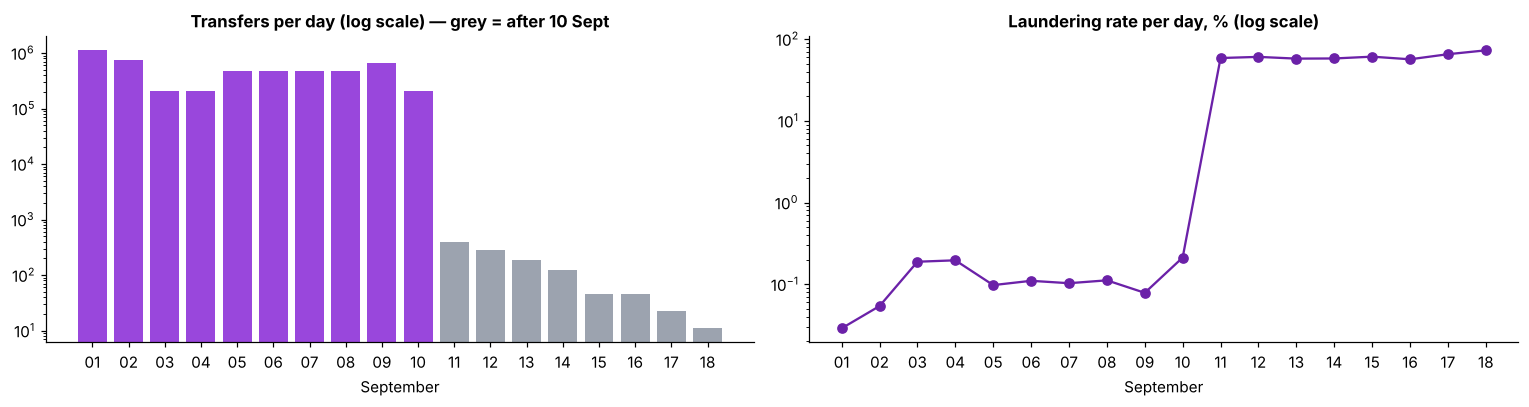

From 11 September onward:


,rows,laundering,rate_pct,laundering_without_scheme,schemes_crossing_11_sept,schemes_entirely_after
0,1108,655.0,59.12,0.0,102.0,7.0


In [8]:
daily = sql("""
    SELECT CAST(date_trunc('day', Timestamp) AS DATE) AS day,
           COUNT(*) AS rows, SUM("Is Laundering") AS laundering,
           100 * AVG("Is Laundering") AS rate_pct
    FROM j GROUP BY 1 ORDER BY 1
""")
display(fmt_int(daily, ["rows", "laundering"]).round({"rate_pct": 3}))

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
lab = pd.to_datetime(daily["day"]).dt.strftime("%d")
ax[0].bar(lab, daily["rows"], color=np.where(pd.to_datetime(daily["day"]) >= "2022-09-11", GREY, PURPLE))
ax[0].set_yscale("log"); ax[0].set_title("Transfers per day (log scale) — grey = after 10 Sept"); ax[0].set_xlabel("September")
ax[1].plot(lab, daily["rate_pct"], marker="o", color=DARK)
ax[1].set_yscale("log"); ax[1].set_title("Laundering rate per day, % (log scale)"); ax[1].set_xlabel("September")
plt.tight_layout(); plt.show()

tail = sql("""
    SELECT COUNT(*) AS rows, SUM("Is Laundering") AS laundering, 100 * AVG("Is Laundering") AS rate_pct,
           SUM(CASE WHEN "Is Laundering" = 1 AND "Attempt ID" IS NULL THEN 1 ELSE 0 END) AS laundering_without_scheme
    FROM j WHERE Timestamp >= TIMESTAMP '2022-09-11'
""")
sch_tail = sql("""
    SELECT SUM(CASE WHEN first_ts <  TIMESTAMP '2022-09-11' AND last_ts >= TIMESTAMP '2022-09-11' THEN 1 ELSE 0 END) AS schemes_crossing_11_sept,
           SUM(CASE WHEN first_ts >= TIMESTAMP '2022-09-11' THEN 1 ELSE 0 END) AS schemes_entirely_after
    FROM (SELECT "Attempt ID", MIN(Timestamp) AS first_ts, MAX(Timestamp) AS last_ts
          FROM j WHERE "Attempt ID" IS NOT NULL GROUP BY 1)
""")
print("From 11 September onward:")
display(pd.concat([tail, sch_tail], axis=1).round(2))

**What the output shows.**
- **1–10 September looks like normal data**: between 207,382 and 1,114,919 transfers a day, with
  a laundering rate between 0.029% and 0.212%.
- The number of laundering rows per day is fairly steady (322 to 539), but normal traffic swings a
  lot: weekends (3–4 Sept and Saturday 10 Sept) have only about 207,000–208,000 rows. That is why
  the **daily rate jumps on low-volume days** (0.189%, 0.196%, 0.212%) — there is not more
  laundering, there is less normal traffic.
- **From 11 September the data is broken**: only **1,108** rows in eight days, of which **655**
  are laundering — a rate of **59.12%**. Every one of those 655 belongs to a scheme
  (`laundering_without_scheme` = 0). **102** schemes started before 11 Sept and continue after it;
  **7** schemes are entirely after it.

**What it means for us.** The generator stopped producing normal traffic on 10 September but kept
writing out the schemes that were still running. 11–18 September is **leftover output, not a time
period**. We drop it before sampling and modelling (Part C). The cost: 655 laundering rows and 7
whole schemes, and 102 schemes lose their later transfers ("truncated").

*Correction to the previous EDA:* its text said "1,575 rows from 11 September". That number was
typed by hand and never printed by any code; the real count is **1,108**. The 655 was right.

Rows in hour 0: 634,726   median rows in hours 1-23: 193,166
Rows stamped exactly 00:00: 18,034
Where the hour-0 rows come from:


,hour0_rows_on_1_sept,hour0_reinvestment_rows,all_reinvestment_rows
0,"344,208","235,962","481,056"



How many times each weekday appears in the window:


,0,1,2,3,4,5,6
weekday,Friday,Saturday,Sunday,Thursday,Monday,Tuesday,Wednesday
times_in_window,3,3,3,3,2,2,2


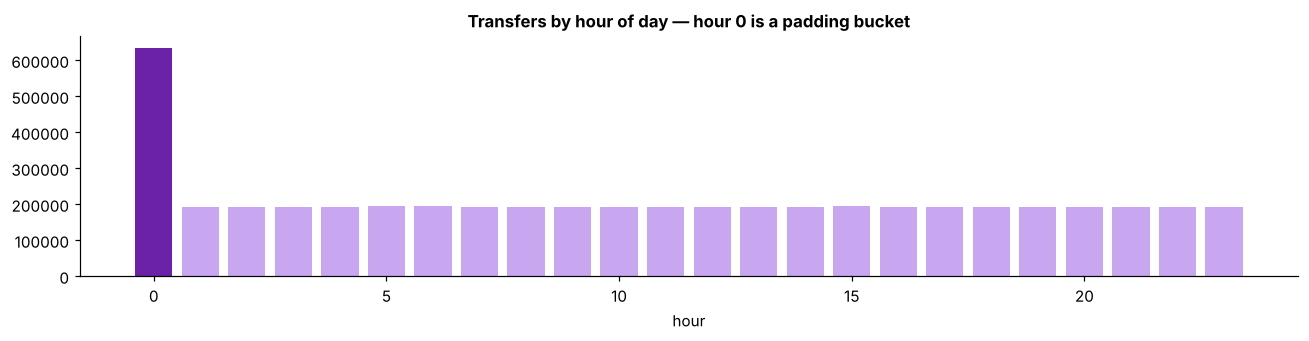

In [9]:
hourly = sql("SELECT hour(Timestamp) AS hour, COUNT(*) AS rows, 100*AVG(\"Is Laundering\") AS rate_pct FROM j GROUP BY 1 ORDER BY 1")
midnight = one("SELECT COUNT(*) FROM j WHERE hour(Timestamp) = 0 AND minute(Timestamp) = 0")
print(f"Rows in hour 0: {hourly.loc[0, 'rows']:,}   median rows in hours 1-23: {hourly.loc[1:, 'rows'].median():,.0f}")
print(f"Rows stamped exactly 00:00: {midnight:,}")
h0 = sql("""
    SELECT SUM(CASE WHEN CAST(Timestamp AS DATE) = DATE '2022-09-01' THEN 1 ELSE 0 END) AS hour0_rows_on_1_sept,
           SUM(CASE WHEN "Payment Format" = 'Reinvestment' THEN 1 ELSE 0 END) AS hour0_reinvestment_rows,
           (SELECT COUNT(*) FROM j WHERE "Payment Format" = 'Reinvestment') AS all_reinvestment_rows
    FROM j WHERE hour(Timestamp) = 0
""")
print("Where the hour-0 rows come from:")
display(fmt_int(h0, h0.columns))

weekday = sql("""
    SELECT dayname(d) AS weekday, COUNT(*) AS times_in_window FROM
    (SELECT DISTINCT CAST(Timestamp AS DATE) AS d FROM j) GROUP BY 1 ORDER BY 2 DESC, 1
""")
print("\nHow many times each weekday appears in the window:")
display(weekday.T)

fig, ax = plt.subplots(figsize=(12, 3.2))
ax.bar(hourly["hour"], hourly["rows"], color=[DARK] + [LILAC] * 23)
ax.set_title("Transfers by hour of day — hour 0 is a padding bucket"); ax.set_xlabel("hour")
plt.tight_layout(); plt.show()

**What the output shows.**
- Hour 0 (midnight to 1 am) has **634,726** rows, more than three times the median of the other
  hours (**193,166**).
- It is **not** missing times written as 00:00: only **18,034** rows are stamped exactly 00:00,
  and the rest are spread over the hour. Instead, **344,208** hour-0 rows are on 1 September (the
  generator starting up) and **235,962** of the **481,056** Reinvestment rows are posted in hour 0.
- The window runs Thursday 1 Sept → Sunday 18 Sept, so Thursday, Friday, Saturday and Sunday occur
  **3** times and Monday, Tuesday, Wednesday only **2** times.

**What it means for us.** Hour of day and day of week describe how the generator schedules
transfers, not how launderers behave. Any weekday difference is partly calendar arithmetic (some
days simply appear more often). **Do not use hour or weekday as features.**

<a id="b2"></a>
## <span style="color:#9947dc">2. How rare laundering is</span>

**Why.** How rare the target is decides almost every modelling choice: which scores mean anything,
and whether we need to give laundering rows extra weight.

**How.** Count laundering rows in the whole file, and again in 1–10 September only (the part we
actually keep, see section 1).

In [10]:
rare = sql("""
    SELECT 'Whole file (1-18 Sept)' AS period, COUNT(*) AS rows, SUM("Is Laundering") AS laundering FROM j
    UNION ALL
    SELECT '1-10 Sept only', COUNT(*), SUM("Is Laundering") FROM j WHERE Timestamp < TIMESTAMP '2022-09-11'
""")
rare["rate_pct"] = 100 * rare["laundering"] / rare["rows"]
rare["one_in"] = rare["rows"] / rare["laundering"]
display(fmt_int(rare, ["rows", "laundering", "one_in"]).round({"rate_pct": 4}))

always_no = 100 * (1 - rare.loc[0, "laundering"] / rare.loc[0, "rows"])
print(f"A 'model' that always says 'not laundering' would be {always_no:.2f}% accurate — and catch nothing.")

,period,rows,laundering,rate_pct,one_in
0,Whole file (1-18 Sept),"5,078,336","5,177",0.1019,981
1,1-10 Sept only,"5,077,228","4,522",0.0891,"1,123"


A 'model' that always says 'not laundering' would be 99.90% accurate — and catch nothing.


**What the output shows.** Over the whole file **5,177** of **5,078,336** rows are laundering:
**0.1019%**, about **1 in 981**. In 1–10 September only (what we actually use) it is **4,522** of
**5,077,228**: **0.0891%**, about **1 in 1,123**. A "model" that always answers "normal" is
**99.90%** accurate and catches nothing.

**What it means for us.**
- **Accuracy is useless here.** We report precision (of the alerts we raise, how many are really
  laundering), recall (of all laundering, how much we catch) and **PR-AUC** (one number summarising
  precision vs recall over all thresholds).
- The "true" rate to quote from now on is the **1–10 Sept rate, 0.0891%**, because that is the
  data we model on.

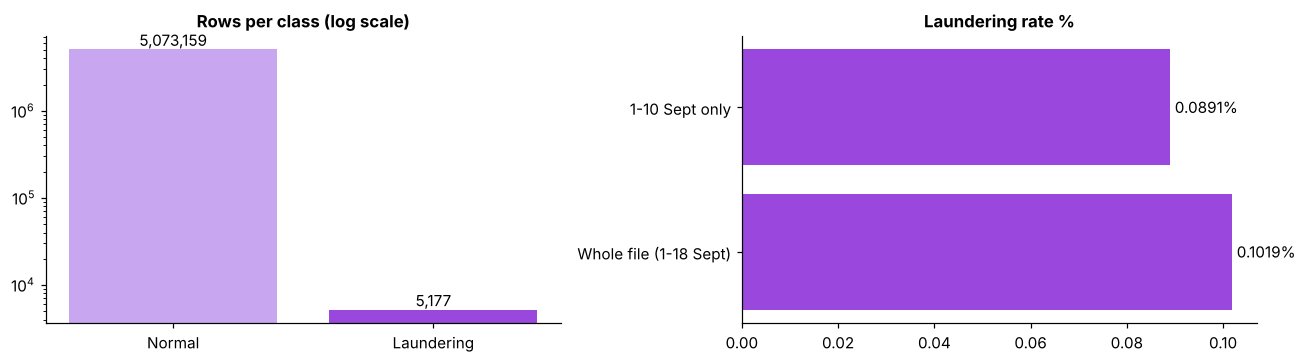

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].bar(["Normal", "Laundering"], [rare.loc[0, "rows"] - rare.loc[0, "laundering"], rare.loc[0, "laundering"]],
          color=[LILAC, PURPLE])
ax[0].set_yscale("log"); ax[0].set_title("Rows per class (log scale)")
for i, v in enumerate([rare.loc[0, "rows"] - rare.loc[0, "laundering"], rare.loc[0, "laundering"]]):
    ax[0].text(i, v, f"{v:,.0f}", ha="center", va="bottom")
ax[1].barh(rare["period"], rare["rate_pct"], color=PURPLE)
ax[1].set_title("Laundering rate %");
for i, v in enumerate(rare["rate_pct"]):
    ax[1].text(v, i, f" {v:.4f}%", va="center")
plt.tight_layout(); plt.show()

<a id="b3"></a>
## <span style="color:#9947dc">3. Checking the labels against the patterns file</span>

**Why.** The transfer file marks rows as laundering. The patterns file tells us *which scheme* each
laundering transfer belongs to. If the two agree, our labels are trustworthy. If some laundering
rows have no scheme, we need to know who they are, because our agent investigates **schemes**.

**How.** Put every row in one of four boxes: laundering with a scheme, laundering without a scheme,
scheme but not labelled laundering (must be zero), and normal. Then compare the two kinds of
laundering rows: "explained" (has a scheme) and "unexplained" (no scheme).

In [12]:
recon = sql("""
    SELECT CASE WHEN "Is Laundering" = 1 AND "Attempt ID" IS NOT NULL THEN '1. Laundering, has a scheme (explained)'
                WHEN "Is Laundering" = 1 THEN '2. Laundering, no scheme (unexplained)'
                WHEN "Attempt ID" IS NOT NULL THEN '3. Scheme but not laundering (must be 0)'
                ELSE '4. Normal' END AS box,
           COUNT(*) AS rows
    FROM j GROUP BY 1 ORDER BY 1
""")
recon["share_of_laundering_pct"] = np.where(recon["box"].str[:1].isin(["1", "2"]),
                                            100 * recon["rows"] / one('SELECT SUM("Is Laundering") FROM j'), np.nan)
display(fmt_int(recon, ["rows"]).round(1))

cmp = sql("""
    SELECT CASE WHEN "Attempt ID" IS NOT NULL THEN 'Explained' ELSE 'Unexplained' END AS kind,
           COUNT(*) AS rows,
           100 * AVG(CASE WHEN "Payment Format" = 'ACH' THEN 1 ELSE 0 END) AS ach_pct,
           MEDIAN("Amount Paid") AS median_amount,
           100 * AVG(cross_border) AS cross_border_pct,
           100 * AVG(cross_bank) AS cross_bank_pct,
           100 * AVG(CASE WHEN Timestamp >= TIMESTAMP '2022-09-11' THEN 1 ELSE 0 END) AS after_10_sept_pct
    FROM j WHERE "Is Laundering" = 1 GROUP BY 1 ORDER BY 1
""")
display(cmp.round(2))

fmt_split = sql("""
    SELECT "Payment Format",
           SUM(CASE WHEN "Attempt ID" IS NOT NULL THEN 1 ELSE 0 END) AS explained,
           SUM(CASE WHEN "Attempt ID" IS NULL THEN 1 ELSE 0 END) AS unexplained
    FROM j WHERE "Is Laundering" = 1 GROUP BY 1 ORDER BY 2 DESC, 3 DESC
""")
print("Laundering rows by payment format:")
display(fmt_split)

,box,rows,share_of_laundering_pct
0,"1. Laundering, has a scheme (explained)","3,209",62.0
1,"2. Laundering, no scheme (unexplained)","1,968",38.0
2,4. Normal,"5,073,159",NaN


,kind,rows,ach_pct,median_amount,cross_border_pct,cross_bank_pct,after_10_sept_pct
0,Explained,3209,99.97,12576.93,74.29,97.51,20.41
1,Unexplained,1968,64.79,2955.04,37.60,98.63,0.00


Laundering rows by payment format:


,Payment Format,explained,unexplained
0,ACH,3208.0,1275.0
1,Bitcoin,1.0,55.0
2,Cheque,0.0,324.0
3,Credit Card,0.0,206.0
4,Cash,0.0,108.0


**What the output shows.**
- **3,209** laundering rows (**62.0%**) belong to a scheme in the patterns file ("explained").
  **1,968** (**38.0%**) have no scheme ("unexplained"). There is no row with a scheme that is
  labelled normal (box 3 does not even appear — its count is 0). So the labels and the answer key
  agree perfectly where they overlap.
- The two kinds of laundering look **different**:
  - payment format: explained rows are **99.97%** ACH; unexplained only **64.79%**;
  - median amount: **12,576.93** vs **2,955.04**;
  - cross-border: **74.29%** vs **37.60%**;
  - after 10 Sept: **20.41%** of explained rows vs **0%** of unexplained.
- Apart from **1** Bitcoin row, **every non-ACH laundering row is unexplained**: all 324 Cheque,
  206 Credit Card, 108 Cash, and 55 of the 56 Bitcoin rows.

**What it means for us.** The unexplained rows are not "missing scheme labels" of the same kind —
they behave like a different, simpler type of laundering (smaller, more domestic, more varied
payment methods). The agent can only be scored on the explained schemes. The team must decide
(open decision 2): keep the 1,968 as classifier-only positives, or exclude them — and say which
in the report.

<a id="b3b"></a>
## <span style="color:#9947dc">3b. Where do the unexplained laundering rows sit?</span>

**Why.** 1,968 laundering rows have no scheme. Before deciding what to do with them we want to know:
do they touch the same accounts as the documented schemes (so they could be "missing pieces"), or
are they somewhere else entirely? Do they form chains of their own (A → B, then B → C), which would
mean undocumented schemes? And when do they happen?

**How.** For each kind of laundering row: how often it touches an account that is in a documented
scheme; how many different senders and receivers; how often the receiver of an unexplained transfer
later **sends** another unexplained transfer (a chain step). Then their timing per day and their
amounts, in charts.

In [13]:
uxa = sql('''
    WITH sch_acc AS (SELECT acct_from AS a FROM j WHERE "Attempt ID" IS NOT NULL
                     UNION SELECT acct_to FROM j WHERE "Attempt ID" IS NOT NULL)
    SELECT CASE WHEN "Attempt ID" IS NOT NULL THEN 'Explained' ELSE 'Unexplained' END AS kind,
           COUNT(*) AS rows,
           100 * AVG(CASE WHEN acct_from IN (SELECT a FROM sch_acc) OR acct_to IN (SELECT a FROM sch_acc) THEN 1.0 ELSE 0 END)
               AS touches_a_scheme_account_pct,
           COUNT(DISTINCT acct_from) AS distinct_senders,
           COUNT(DISTINCT acct_to) AS distinct_receivers,
           100 * AVG(self_transfer) AS self_transfer_pct
    FROM j WHERE "Is Laundering" = 1 GROUP BY 1 ORDER BY 1
''')
display(uxa.round(2))

chain = sql('''
    WITH u AS (SELECT acct_from, acct_to, Timestamp FROM j WHERE "Is Laundering" = 1 AND "Attempt ID" IS NULL)
    SELECT COUNT(*) AS unexplained_rows,
           SUM(CASE WHEN EXISTS (SELECT 1 FROM u b WHERE b.acct_from = a.acct_to AND b.Timestamp >= a.Timestamp)
                    THEN 1 ELSE 0 END) AS receiver_later_sends_unexplained,
           SUM(CASE WHEN EXISTS (SELECT 1 FROM u b WHERE b.acct_to = a.acct_from AND b.Timestamp <= a.Timestamp)
                    THEN 1 ELSE 0 END) AS sender_earlier_received_unexplained
    FROM u a
''')
display(chain)

per_sender = sql('''SELECT n, COUNT(*) AS senders FROM
                    (SELECT acct_from, COUNT(*) AS n FROM j WHERE "Is Laundering" = 1 AND "Attempt ID" IS NULL GROUP BY 1)
                    GROUP BY 1 ORDER BY 1''')
print("How many unexplained laundering rows each sender has:")
display(per_sender.T)
con.execute('''
    CREATE OR REPLACE TABLE hub_list AS
    SELECT a AS acct FROM (SELECT acct_from AS a, acct_to AS b FROM j UNION ALL SELECT acct_to, acct_from FROM j)
    GROUP BY a HAVING COUNT(DISTINCT b) >= 500
''')
top_ux = sql('''
    SELECT acct_from AS sender, COUNT(*) AS unexplained_rows,
           acct_from IN (SELECT acct FROM hub_list) AS is_hub, ANY_VALUE("Bank Name_from") AS bank
    FROM j WHERE "Is Laundering" = 1 AND "Attempt ID" IS NULL GROUP BY 1 ORDER BY 2 DESC LIMIT 5
''')
print("Top 5 senders of unexplained laundering (hub = 500+ counterparties, as in section 11):")
display(top_ux)
hub_ux = one('''SELECT 100 * AVG(CASE WHEN acct_from IN (SELECT acct FROM hub_list) THEN 1.0 ELSE 0 END)
                 FROM j WHERE "Is Laundering" = 1 AND "Attempt ID" IS NULL''')
print(f"Share of unexplained laundering rows sent by a hub account: {hub_ux:.1f}%")

,kind,rows,touches_a_scheme_account_pct,distinct_senders,distinct_receivers,self_transfer_pct
0,Explained,3209,100.00,2071,2064,0.34
1,Unexplained,1968,2.13,1315,1932,0.00


,unexplained_rows,receiver_later_sends_unexplained,sender_earlier_received_unexplained
0,1968,14.0,14.0


How many unexplained laundering rows each sender has:


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
n,1,2,3,9,13,14,16,18,21,23,26,29,158,243
senders,1268,29,3,1,3,1,2,1,2,1,1,1,1,1


Top 5 senders of unexplained laundering (hub = 500+ counterparties, as in section 11):


,sender,unexplained_rows,is_hub,bank
0,70:100428660,243,True,Oasis Thrift
1,70:1004286A8,158,True,Oasis Thrift
2,70:100428978,29,True,Oasis Thrift
3,70:100428810,26,True,Oasis Thrift
4,70:100428738,23,True,Oasis Thrift


Share of unexplained laundering rows sent by a hub account: 32.2%


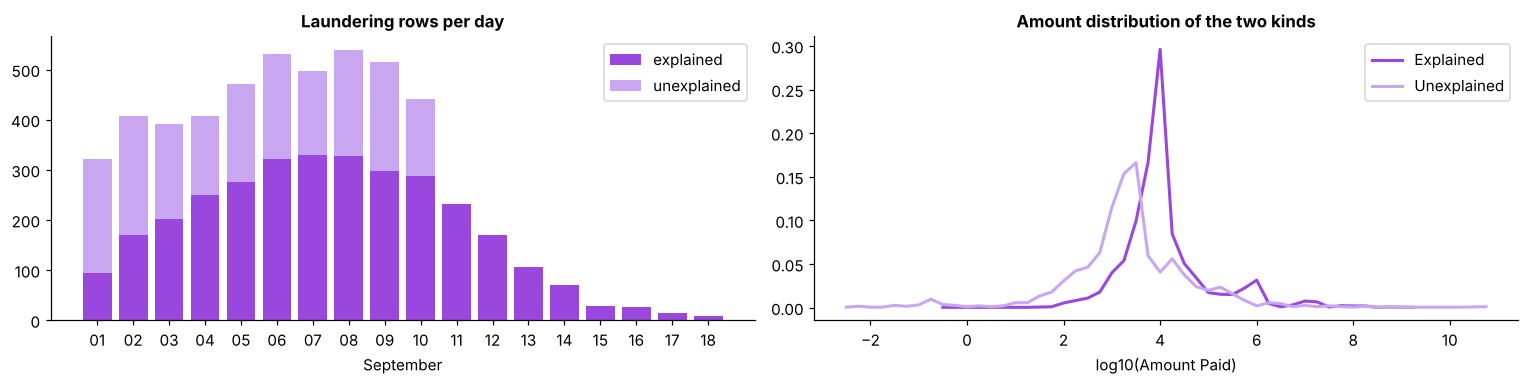

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
day,2022-09-01 00:00:00,2022-09-02 00:00:00,2022-09-03 00:00:00,2022-09-04 00:00:00,2022-09-05 00:00:00,2022-09-06 00:00:00,2022-09-07 00:00:00,2022-09-08 00:00:00,2022-09-09 00:00:00,2022-09-10 00:00:00,2022-09-11 00:00:00,2022-09-12 00:00:00,2022-09-13 00:00:00,2022-09-14 00:00:00,2022-09-15 00:00:00,2022-09-16 00:00:00,2022-09-17 00:00:00,2022-09-18 00:00:00
explained,94.0,170.0,201.0,250.0,276.0,321.0,329.0,328.0,298.0,287.0,232.0,170.0,106.0,70.0,28.0,26.0,15.0,8.0
unexplained,228.0,238.0,190.0,157.0,195.0,210.0,168.0,211.0,216.0,155.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [14]:
kind_day = sql('''
    SELECT CAST(date_trunc('day', Timestamp) AS DATE) AS day,
           SUM(CASE WHEN "Attempt ID" IS NOT NULL THEN 1 ELSE 0 END) AS explained,
           SUM(CASE WHEN "Attempt ID" IS NULL THEN 1 ELSE 0 END) AS unexplained
    FROM j WHERE "Is Laundering" = 1 GROUP BY 1 ORDER BY 1
''')
kind_amt = sql('''
    SELECT CASE WHEN "Attempt ID" IS NOT NULL THEN 'Explained' ELSE 'Unexplained' END AS kind,
           floor(log10(GREATEST("Amount Paid", 1e-6)) * 4) / 4 AS bin, COUNT(*) AS n
    FROM j WHERE "Is Laundering" = 1 GROUP BY 1, 2 ORDER BY 2
''')
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
lab = pd.to_datetime(kind_day["day"]).dt.strftime("%d")
ax[0].bar(lab, kind_day["explained"], color=PURPLE, label="explained")
ax[0].bar(lab, kind_day["unexplained"], bottom=kind_day["explained"], color=LILAC, label="unexplained")
ax[0].set_title("Laundering rows per day"); ax[0].set_xlabel("September"); ax[0].legend()
for k, colour in [("Explained", PURPLE), ("Unexplained", LILAC)]:
    d = kind_amt[kind_amt["kind"] == k]
    ax[1].plot(d["bin"], d["n"] / d["n"].sum(), color=colour, lw=2, label=k)
ax[1].set_title("Amount distribution of the two kinds"); ax[1].set_xlabel("log10(Amount Paid)"); ax[1].legend()
plt.tight_layout(); plt.show()
display(kind_day.T)

**What the output shows.**
- Explained laundering rows **all** (100%) touch a scheme account, by definition. Unexplained rows
  touch a scheme account in only **2.13%** of cases — they live almost entirely **outside** the
  documented schemes.
- They hardly form chains: only **14** of the **1,968** unexplained rows have a receiver that later
  sends another unexplained transfer. So they are mostly **isolated single transfers**, not
  undocumented multi-step schemes.
- Most senders have just one: **1,268** senders have exactly 1 unexplained row. But a few have a lot,
  and the top five are all **hub accounts at Oasis Thrift** (`70:100428660` alone has **243**).
  Hubs send **32.2%** of all unexplained laundering rows.
- Over time, unexplained rows arrive at a steady 155–238 per day from 1 to 10 Sept and **stop
  completely** after 10 Sept, while explained rows continue (the leftover schemes of section 1).
- Their amounts are clearly smaller than explained rows (chart on the right).

**What it means for us.** The 1,968 unexplained rows are a **separate, simpler kind of laundering**:
single, mostly unconnected transfers, a third of them from the hub accounts, behaving like normal
background traffic that happens to be labelled. They cannot be investigated as schemes. Our
suggestion for open decision 2: keep them as **classifier-only** positives (the model should still
catch them), exclude them from agent case scoring, and report the classifier's recall on the two
kinds separately.

<a id="b4"></a>
## <span style="color:#9947dc">4. What a laundering scheme looks like</span>

**Why.** A scheme is a group of transfers that move dirty money together — for example one account
spraying money to many (FAN-OUT) or money going round in a circle (CYCLE). Our agent's job is to
rebuild these from an alert. So we need to know how big they are, how long they last, and whether
they share accounts with each other.

**How.** For each `Attempt ID`: count transfers, measure first-to-last time, count distinct
accounts. Then summarise by pattern type. Finally count accounts that are in more than one scheme.

In [15]:
prof = sql("""
    SELECT "Attempt ID", ANY_VALUE("Pattern Type") AS pattern, COUNT(*) AS transfers,
           (epoch(MAX(Timestamp)) - epoch(MIN(Timestamp))) / 86400 AS span_days,
           COUNT(DISTINCT acct) AS accounts
    FROM (SELECT "Attempt ID", "Pattern Type", Timestamp, acct_from AS acct FROM j WHERE "Attempt ID" IS NOT NULL
          UNION ALL
          SELECT "Attempt ID", "Pattern Type", Timestamp, acct_to FROM j WHERE "Attempt ID" IS NOT NULL)
    GROUP BY 1
""")
# transfers were counted twice above (once per side) -> halve
prof["transfers"] = prof["transfers"] // 2

by_type = prof.groupby("pattern").agg(
    schemes=("transfers", "size"), transfers=("transfers", "sum"),
    median_transfers=("transfers", "median"), max_transfers=("transfers", "max"),
    median_span_days=("span_days", "median"), median_accounts=("accounts", "median"),
).sort_values("schemes", ascending=False)
display(by_type.round(2))
print(f"All schemes: {len(prof)} | median transfers {prof['transfers'].median()} | max {prof['transfers'].max()} | "
      f"single-transfer schemes {(prof['transfers'] == 1).sum()} | median span {prof['span_days'].median():.2f} days | "
      f"max span {prof['span_days'].max():.2f} days")

shared = sql("""
    SELECT acct, COUNT(DISTINCT "Attempt ID") AS schemes FROM
      (SELECT acct_from AS acct, "Attempt ID" FROM j WHERE "Attempt ID" IS NOT NULL
       UNION SELECT acct_to, "Attempt ID" FROM j WHERE "Attempt ID" IS NOT NULL)
    GROUP BY 1
""")
print(f"\nAccounts in any scheme: {len(shared):,} | in more than one scheme: {(shared['schemes'] > 1).sum():,} "
      f"| most schemes for one account: {shared['schemes'].max()}")

,schemes,transfers,median_transfers,max_transfers,median_span_days,median_accounts
pattern,,,,,,
CYCLE,54,287,4.0,12,3.00,4.0
GATHER-SCATTER,51,716,14.0,28,6.28,15.0
BIPARTITE,49,263,4.0,15,1.01,8.0
FAN-OUT,48,342,7.0,16,3.19,8.0
SCATTER-GATHER,44,626,14.0,32,3.70,9.0
STACK,43,466,10.0,30,3.05,15.0
RANDOM,41,191,3.0,11,1.92,4.0
FAN-IN,40,318,8.0,16,3.54,9.0


All schemes: 370 | median transfers 6.5 | max 32 | single-transfer schemes 43 | median span 3.11 days | max span 8.43 days

Accounts in any scheme: 3,170 | in more than one scheme: 100 | most schemes for one account: 32


**What the output shows.**
- **370** schemes of **8** types. The most common are CYCLE (54), GATHER-SCATTER (51), BIPARTITE
  (49) and FAN-OUT (48).
- They are small: median **6.5** transfers, the largest **32**, and **43** schemes are a single
  transfer. GATHER-SCATTER and SCATTER-GATHER are the biggest (median **14** transfers).
- They last days, not minutes: median **3.11** days from first to last transfer, longest **8.43**
  days. GATHER-SCATTER runs longest (median **6.28** days).
- **3,170** accounts take part in a scheme; **100** of them are in more than one scheme, and one
  account is in **32** different schemes.

**What it means for us.**
- A scheme that lasts several days will often cross any date we cut at — that is why the time split
  moves a crossing scheme **whole** into the later split.
- Schemes are **not independent**: 100 accounts link them. A random row split would put half of a
  ring in train and half in test, and the model would "recognise" accounts instead of learning
  behaviour. Never split randomly by row.

<a id="b4b"></a>
## <span style="color:#9947dc">4b. Schemes in more detail: money, banks, borders and timing</span>

**Why.** The agent will be judged on rebuilding schemes, so it helps to know each type's
"personality": how much money it moves, how many banks and countries it crosses, how fast it
moves, and when schemes start. The previous EDA also showed which accounts are shared between
schemes — we look at how that sharing is spread.

**How.** Per pattern type: median transfer amount, median total amount per scheme, median number of
banks per scheme, share of cross-border transfers, and median hours between one transfer and the
next inside the same scheme. Then charts of scheme size, scheme duration and start day.

,pattern,median_transfer_amount,median_scheme_total,median_banks_per_scheme,cross_border_pct,cross_bank_pct,median_hours_between_steps
0,SCATTER-GATHER,13836.74,454734.69,8.5,73.96,98.88,2.78
1,RANDOM,13044.81,53718.33,4.0,75.39,97.91,8.07
2,BIPARTITE,12601.65,108659.69,8.0,74.90,96.58,3.00
3,FAN-OUT,12587.31,232340.52,6.0,79.24,97.08,5.33
4,GATHER-SCATTER,12454.60,738786.24,13.0,73.18,97.35,5.52
5,CYCLE,12020.12,59592.24,4.0,72.13,97.21,8.50
6,STACK,11897.23,239026.28,10.0,74.89,97.21,3.07
7,FAN-IN,11379.33,101357.24,7.0,72.01,96.86,5.55


How many schemes each scheme account is in:


schemes,1,2,3,4,5,6,8,9,10,16,17,19,20,21,22,32
accounts,3070,50,15,5,8,7,1,1,2,1,1,2,1,1,3,2


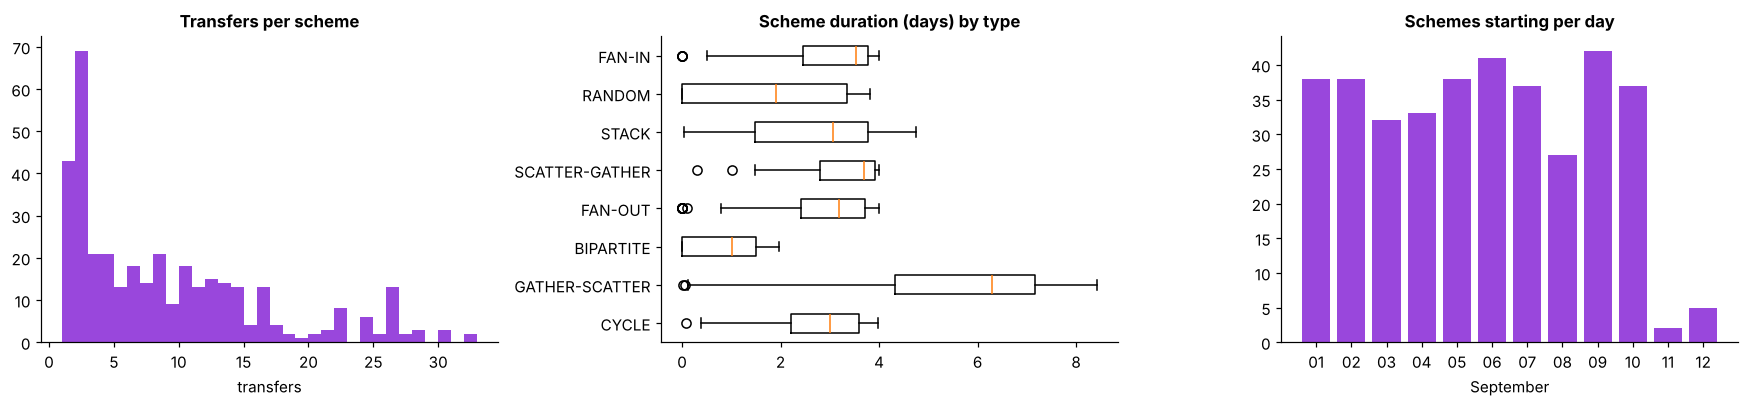

Schemes starting per day:


day,2022-09-01,2022-09-02,2022-09-03,2022-09-04,2022-09-05,2022-09-06,2022-09-07,2022-09-08,2022-09-09,2022-09-10,2022-09-11,2022-09-12
schemes,38,38,32,33,38,41,37,27,42,37,2,5


In [16]:
sch_detail = sql('''
    WITH per AS (
        SELECT "Attempt ID", ANY_VALUE("Pattern Type") AS pattern,
               SUM("Amount Paid") AS total_amount,
               COUNT(DISTINCT bank) AS banks
        FROM (SELECT "Attempt ID", "Pattern Type", "Amount Paid", "Bank Name_from" AS bank FROM j WHERE "Attempt ID" IS NOT NULL
              UNION ALL
              SELECT "Attempt ID", "Pattern Type", 0, "Bank Name_to" FROM j WHERE "Attempt ID" IS NOT NULL)
        GROUP BY 1
    ), gaps AS (
        SELECT "Pattern Type" AS pattern,
               (epoch(Timestamp) - epoch(LAG(Timestamp) OVER (PARTITION BY "Attempt ID" ORDER BY Timestamp, acct_from, acct_to))) / 3600 AS gap_h
        FROM j WHERE "Attempt ID" IS NOT NULL
    ), rows_ AS (
        SELECT "Pattern Type" AS pattern, MEDIAN("Amount Paid") AS median_transfer_amount,
               100 * AVG(cross_border) AS cross_border_pct, 100 * AVG(cross_bank) AS cross_bank_pct
        FROM j WHERE "Attempt ID" IS NOT NULL GROUP BY 1
    )
    SELECT r.pattern, r.median_transfer_amount,
           (SELECT MEDIAN(total_amount) FROM per p WHERE p.pattern = r.pattern) AS median_scheme_total,
           (SELECT MEDIAN(banks) FROM per p WHERE p.pattern = r.pattern) AS median_banks_per_scheme,
           r.cross_border_pct, r.cross_bank_pct,
           (SELECT MEDIAN(gap_h) FROM gaps g WHERE g.pattern = r.pattern AND gap_h IS NOT NULL) AS median_hours_between_steps
    FROM rows_ r ORDER BY r.median_transfer_amount DESC
''')
display(sch_detail.round(2))

shared_dist = shared["schemes"].value_counts().sort_index()
print("How many schemes each scheme account is in:")
display(shared_dist.rename("accounts").to_frame().T)

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].hist(prof["transfers"], bins=range(1, 34), color=PURPLE)
ax[0].set_title("Transfers per scheme"); ax[0].set_xlabel("transfers")
order = by_type.index.tolist()
ax[1].boxplot([prof.loc[prof["pattern"] == t, "span_days"] for t in order], vert=False, tick_labels=order)
ax[1].set_title("Scheme duration (days) by type")
starts = sql('''SELECT CAST(date_trunc('day', MIN(Timestamp)) AS DATE) AS day, COUNT(*) AS n
                FROM j WHERE "Attempt ID" IS NOT NULL GROUP BY "Attempt ID"''').groupby("day")["n"].size()
ax[2].bar(pd.to_datetime(starts.index).strftime("%d"), starts.values, color=PURPLE)
ax[2].set_title("Schemes starting per day"); ax[2].set_xlabel("September")
plt.tight_layout(); plt.show()
print("Schemes starting per day:"); display(starts.rename("schemes").to_frame().T)

**What the output shows.**
- Individual scheme transfers are similar in size across types (median **11,379** to **13,837**),
  but the **total** moved per scheme differs a lot: GATHER-SCATTER **738,786**, SCATTER-GATHER
  **454,735**, versus about **54,000–60,000** for RANDOM and CYCLE. The big types move more money
  because they have more steps.
- Schemes cross many banks: median **4** (CYCLE, RANDOM) up to **13** (GATHER-SCATTER) different
  bank names per scheme. **72–79%** of scheme transfers are cross-border and **96.6–98.9%** cross-bank,
  for every type.
- Steps inside a scheme are hours apart, not minutes: median **2.78** hours (SCATTER-GATHER) to
  **8.50** hours (CYCLE) between one step and the next.
- **3,070** scheme accounts are in a single scheme; the rest are in 2 or more, and **2** accounts
  are each in **32** schemes.
- Schemes start at a steady pace — **27 to 42** new schemes every day from 1 to 10 Sept — then only
  2 and 5 on 11–12 Sept (the 7 schemes that lie entirely in the leftover tail).

**What it means for us.**
- A scheme is spread over **days and many banks**, with hours between steps. The agent must search
  across banks and over a time window of days, not minutes.
- No type is "domestic": cross-border and cross-bank are near-universal inside schemes, so they
  help find scheme transfers but do not tell the types apart. Topology (who pays whom) does.
- The few accounts that sit in 10–32 schemes are worth flagging in the agent as "repeat
  participants".

<a id="b5"></a>
## <span style="color:#9947dc">5. Payment format</span>

**Why.** Payment method is the most obvious thing to look at. We also want to know whether a big
difference here is about *laundering* or just about *how the fake data was generated*.

**How.** For each format: number of transfers, laundering rows, laundering rate, and what share of
all laundering it carries.

,value,rows,laundering,rate_pct,share_of_laundering_pct,share_of_rows_pct
0,ACH,"600,793","4,483",0.7462,86.5946,11.8305
1,Bitcoin,"146,086",56,0.0383,1.0817,2.8767
2,Cash,"490,891",108,0.0220,2.0862,9.6664
3,Cheque,"1,864,331",324,0.0174,6.2585,36.7115
4,Credit Card,"1,323,324",206,0.0156,3.9791,26.0582
5,Reinvestment,"481,056",0,0.0000,0.0000,9.4727
6,Wire,"171,855",0,0.0000,0.0000,3.3841


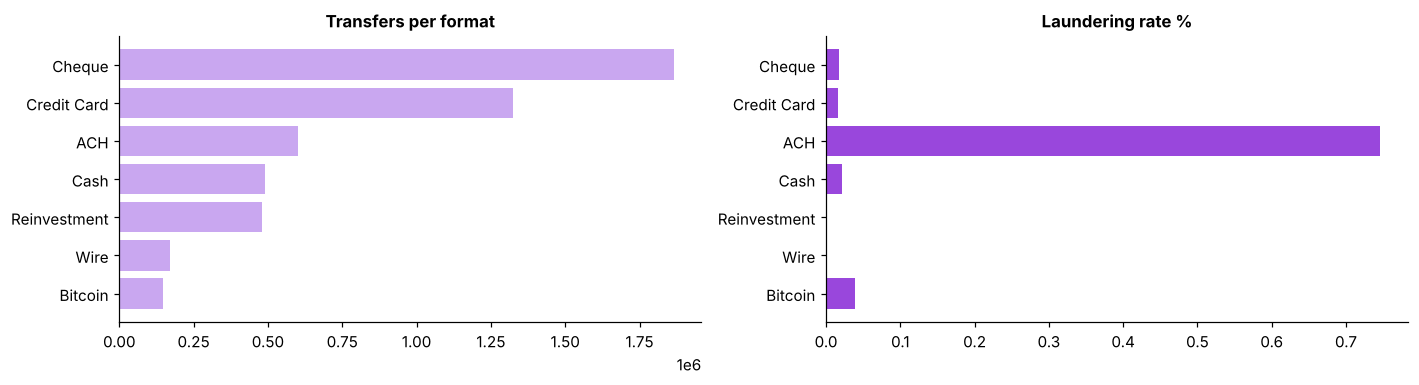

In [17]:
fmt = risk_by('"Payment Format"')
display(fmt_int(fmt, ["rows", "laundering"]).round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
f2 = fmt.sort_values("rows")
ax[0].barh(f2["value"], f2["rows"], color=LILAC); ax[0].set_title("Transfers per format")
ax[1].barh(f2["value"], f2["rate_pct"], color=PURPLE); ax[1].set_title("Laundering rate %")
plt.tight_layout(); plt.show()

**What the output shows.**
- **ACH** is the clear outlier: **600,793** transfers, **4,483** laundering, rate **0.7462%**. ACH
  is **11.83%** of all rows but carries **86.59%** of all laundering.
- Bitcoin, Cash, Cheque and Credit Card are all between **0.0156%** and **0.0383%**.
- **Reinvestment (481,056 rows) and Wire (171,855 rows) have exactly zero laundering.**

**What it means for us.** This is the strongest single number in the dataset and the one we trust
least. Exactly zero laundering in 652,911 Wire + Reinvestment transfers is not how real crime works
(wire transfers are a classic laundering channel); it is how this generator writes its schemes.
Reinvestment also turns out to be 100% self-transfers (section 7). Report payment format as **a
property of the dataset**, never as a finding about laundering. Modelling should train with and
without it and report both — a model that only learned "ACH = suspicious" is not useful.

,format,share_of_normal_pct,share_of_laundering_pct,rate_cross_border_pct,rate_same_country_pct
0,ACH,11.7542,86.5946,1.8306,0.3885
1,Cheque,36.7425,6.2585,0.0321,0.0104
2,Credit Card,26.0808,3.9791,0.0270,0.0103
3,Cash,9.6741,2.0862,0.0394,0.0130
4,Bitcoin,2.8785,1.0817,0.0582,0.0301
5,Reinvestment,9.4824,0.0000,NaN,0.0000
6,Wire,3.3875,0.0000,0.0000,0.0000


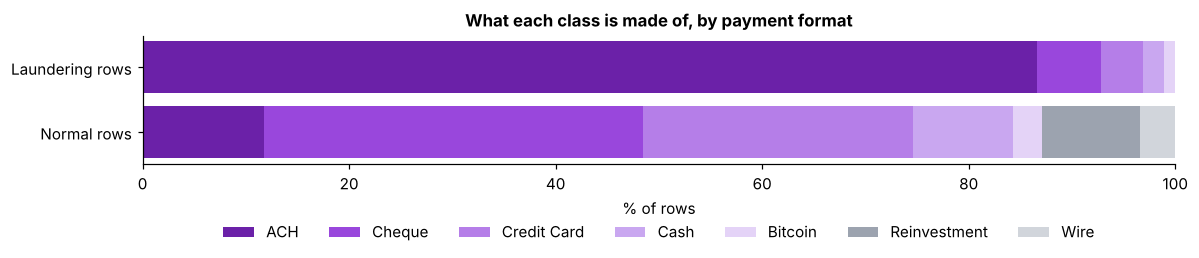

In [18]:
comp = sql('''
    SELECT "Payment Format" AS format,
           100.0 * SUM(CASE WHEN "Is Laundering" = 0 THEN 1 ELSE 0 END) / (SELECT SUM(1 - "Is Laundering") FROM j) AS share_of_normal_pct,
           100.0 * SUM("Is Laundering") / (SELECT SUM("Is Laundering") FROM j) AS share_of_laundering_pct,
           100 * AVG(CASE WHEN cross_border = 1 THEN "Is Laundering" END) AS rate_cross_border_pct,
           100 * AVG(CASE WHEN cross_border = 0 THEN "Is Laundering" END) AS rate_same_country_pct
    FROM j GROUP BY 1 ORDER BY 3 DESC
''')
display(comp.round(4))

fig, ax = plt.subplots(figsize=(11, 2.8))
left = np.zeros(2)
palette = [DARK, PURPLE, "#b57ee8", LILAC, "#e4d3f7", GREY, "#d1d5db"]
for (_, r), colour in zip(comp.iterrows(), palette):
    vals = np.array([r["share_of_normal_pct"], r["share_of_laundering_pct"]])
    ax.barh(["Normal rows", "Laundering rows"], vals, left=left, color=colour, label=r["format"])
    left += vals
ax.set_xlabel("% of rows"); ax.legend(ncol=7, bbox_to_anchor=(0.5, -0.35), loc="upper center", frameon=False)
ax.set_title("What each class is made of, by payment format")
plt.tight_layout(); plt.show()

**What the output shows.**
- The class make-up chart says it plainly: **ACH is 11.75% of normal rows but 86.59% of laundering
  rows**. Cheque is the reverse (36.74% of normal, 6.26% of laundering).
- Inside **every** format, cross-border is riskier than same-country: ACH **1.8306%** vs
  **0.3885%**, Cheque **0.0321%** vs **0.0104%**, Cash **0.0394%** vs **0.0130%**. Wire and
  Reinvestment stay at zero either way.

**What it means for us.** Cross-border is not just "ACH in disguise": it raises the risk within
each payment format. That makes it a more trustworthy signal than format itself.

<a id="b6"></a>
## <span style="color:#9947dc">6. Amounts and currencies</span>

**Why.** Two questions. Do laundering transfers move different amounts? And do we need both
`Amount Paid` and `Amount Received`, or is one a copy of the other?

**How.** Compare amount percentiles for the two classes. Then check when the two amount columns
differ — we expect only when the two currencies differ.

,laundering,p25,median,p75,p99
0,0,184.16,1410.99,12279.36,13515165.78
1,1,2634.97,8667.21,18832.27,23420046.84


,currencies,rows,amounts_identical,laundering,self_transfers
0,Same currency,"5,006,170","5,006,170","5,177","521,233"
1,Different currency,"72,166",12,0,"69,979"


Correlation Amount Paid vs Amount Received: 0.8431


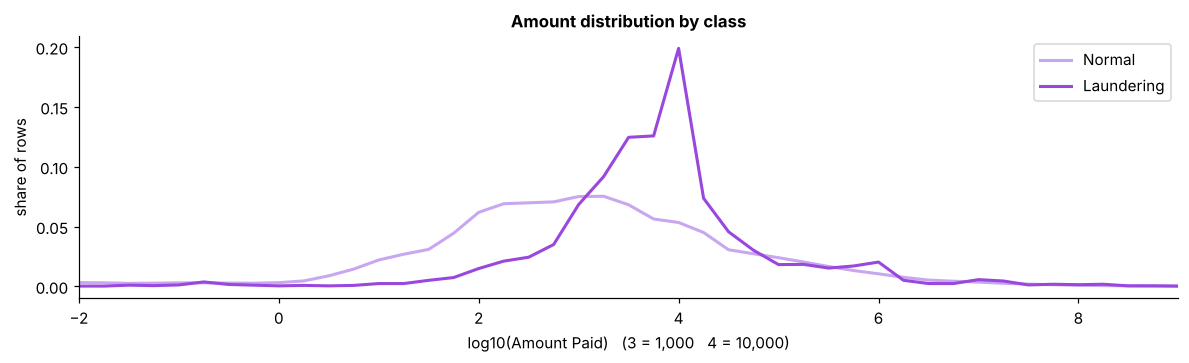

In [19]:
amt = sql("""
    SELECT "Is Laundering" AS laundering,
           quantile_cont("Amount Paid", 0.25) AS p25, MEDIAN("Amount Paid") AS median,
           quantile_cont("Amount Paid", 0.75) AS p75, quantile_cont("Amount Paid", 0.99) AS p99
    FROM j GROUP BY 1 ORDER BY 1
""")
display(amt.round(2))

cur = sql("""
    SELECT CASE WHEN "Payment Currency" = "Receiving Currency" THEN 'Same currency' ELSE 'Different currency' END AS currencies,
           COUNT(*) AS rows,
           SUM(CASE WHEN "Amount Paid" = "Amount Received" THEN 1 ELSE 0 END) AS amounts_identical,
           SUM("Is Laundering") AS laundering,
           SUM(self_transfer) AS self_transfers
    FROM j GROUP BY 1 ORDER BY 1 DESC
""")
display(fmt_int(cur, ["rows", "amounts_identical", "laundering", "self_transfers"]))
print("Correlation Amount Paid vs Amount Received:",
      round(one('SELECT corr("Amount Paid", "Amount Received") FROM j'), 4))

h = sql("""
    SELECT "Is Laundering" AS y, floor(log10(GREATEST("Amount Paid", 1e-6)) * 4) / 4 AS bin, COUNT(*) AS n
    FROM j GROUP BY 1, 2 ORDER BY 2
""")
fig, ax = plt.subplots(figsize=(11, 3.4))
for y, colour, name in [(0, LILAC, "Normal"), (1, PURPLE, "Laundering")]:
    d = h[h["y"] == y]
    ax.plot(d["bin"], d["n"] / d["n"].sum(), color=colour, lw=2, label=name)
ax.set_xlabel("log10(Amount Paid)   (3 = 1,000   4 = 10,000)"); ax.set_ylabel("share of rows")
ax.set_xlim(-2, 9); ax.legend(); ax.set_title("Amount distribution by class")
plt.tight_layout(); plt.show()

**What the output shows.**
- Laundering moves bigger amounts: median **8,667.21** vs **1,410.99** (about 6x). At the bottom
  end the gap is wider (25th percentile **2,634.97** vs **184.16**); at the very top (99th
  percentile) both reach millions.
- When the two currencies are the same (**5,006,170** rows), `Amount Paid` and `Amount Received`
  are **identical in every row**. They differ only when the currency changes (**72,166** rows, of
  which just 12 have equal numbers by chance).
- **All 5,177** laundering rows are same-currency.
- **69,979** of the 72,166 currency-changing rows are self-transfers (more in section 7).
- The correlation between the two amount columns is **0.8431** — not 1, because cross-currency rows
  put the two numbers in different units.

**What it means for us.**
- Keep **one** amount column plus a "currency changes" flag. Two copies of the same number add
  nothing.
- **Amounts are written in each transfer's own currency.** A median that mixes currencies mixes
  units. In preprocessing, convert amounts to one currency (the exchange rate can be read from the
  cross-currency rows: `Amount Paid / Amount Received`) before using amount as a feature.

<a id="b6b"></a>
## <span style="color:#9947dc">6b. Amounts in one currency, and risk by amount size</span>

**Why.** Section 6 compared amounts that are written in 15 different currencies — a "1,000" in Yen
and a "1,000" in US Dollars are very different sums. To compare fairly we need one currency. The
cross-currency rows tell us the exchange rates the generator used, so we can convert everything to
US Dollars. Then we ask: does the laundering rate rise with the size of the transfer?

**How.**
1. For every currency, take the rows that pay in that currency and receive in US Dollars. The ratio
   `Amount Paid / Amount Received` is the exchange rate. We check it is **stable** (one fixed rate)
   — if it is, converting is safe.
2. Convert every amount to USD and compare medians again.
3. Cut all transfers into 10 equal-sized groups by USD amount (deciles) and compute the laundering
   rate in each.
4. Laundering rate per payment currency.

In [20]:
con.execute('''
    CREATE OR REPLACE TABLE fx AS
    SELECT "Payment Currency" AS currency, MEDIAN("Amount Paid" / "Amount Received") AS units_per_usd,
           COUNT(*) AS rows_used,
           STDDEV("Amount Paid" / "Amount Received") / AVG("Amount Paid" / "Amount Received") AS relative_spread
    FROM j
    WHERE "Receiving Currency" = 'US Dollar' AND "Payment Currency" <> 'US Dollar' AND "Amount Received" > 0.01
    GROUP BY 1
    UNION ALL SELECT 'US Dollar', 1.0, NULL, 0.0
''')
fxt = sql("SELECT * FROM fx ORDER BY currency")
display(fxt.round(6))
print(f"Largest relative spread of a rate: {fxt['relative_spread'].max() * 100:.2f}%  -> one fixed rate per currency")
missing_fx = one('SELECT COUNT(DISTINCT "Payment Currency") FROM j WHERE "Payment Currency" NOT IN (SELECT currency FROM fx)')
print(f"Currencies without a rate: {missing_fx}")

con.execute('''
    CREATE OR REPLACE VIEW jusd AS
    SELECT j.*, j."Amount Paid" / fx.units_per_usd AS usd
    FROM j JOIN fx ON j."Payment Currency" = fx.currency
''')
usd = sql('''
    SELECT "Is Laundering" AS laundering, quantile_cont(usd, 0.25) AS p25_usd, MEDIAN(usd) AS median_usd,
           quantile_cont(usd, 0.75) AS p75_usd, quantile_cont(usd, 0.99) AS p99_usd
    FROM jusd GROUP BY 1 ORDER BY 1
''')
print("\nAmounts converted to US Dollars:")
display(usd.round(2))

,currency,units_per_usd,rows_used,relative_spread
0,Australian Dollar,1.412800,146,0.000235
1,Bitcoin,0.000084,13,0.000624
2,Brazil Real,5.646500,80,0.000061
3,Canadian Dollar,1.319300,559,0.010567
4,Euro,0.853400,11060,0.000930
5,Mexican Peso,21.143100,291,0.001826
6,Ruble,77.804353,169,0.000640
7,Rupee,73.443994,803,0.002997
8,Saudi Riyal,3.751100,64,0.000082
9,Shekel,3.377002,45,0.005615


Largest relative spread of a rate: 1.06%  -> one fixed rate per currency
Currencies without a rate: 0



Amounts converted to US Dollars:


,laundering,p25_usd,median_usd,p75_usd,p99_usd
0,0,158.00,891.06,5273.87,3099715.32
1,1,2160.56,5878.81,13758.50,15793198.13


,decile,from_usd,to_usd,rows,laundering,rate_pct
0,1,0.00,3.007000e+01,"507,834",38,0.0075
1,2,30.07,1.076200e+02,"507,834",81,0.0160
2,3,107.62,2.208500e+02,"507,834",145,0.0286
3,4,220.85,4.374500e+02,"507,834",172,0.0339
4,5,437.45,8.935700e+02,"507,834",259,0.0510
5,6,893.57,1.790920e+03,"507,834",439,0.0864
6,7,1790.93,3.585420e+03,"507,833",767,0.1510
7,8,3585.42,8.953590e+03,"507,833","1,240",0.2442
8,9,8953.62,3.539787e+04,"507,833","1,821",0.3586
9,10,35397.87,2.655861e+10,"507,833",215,0.0423


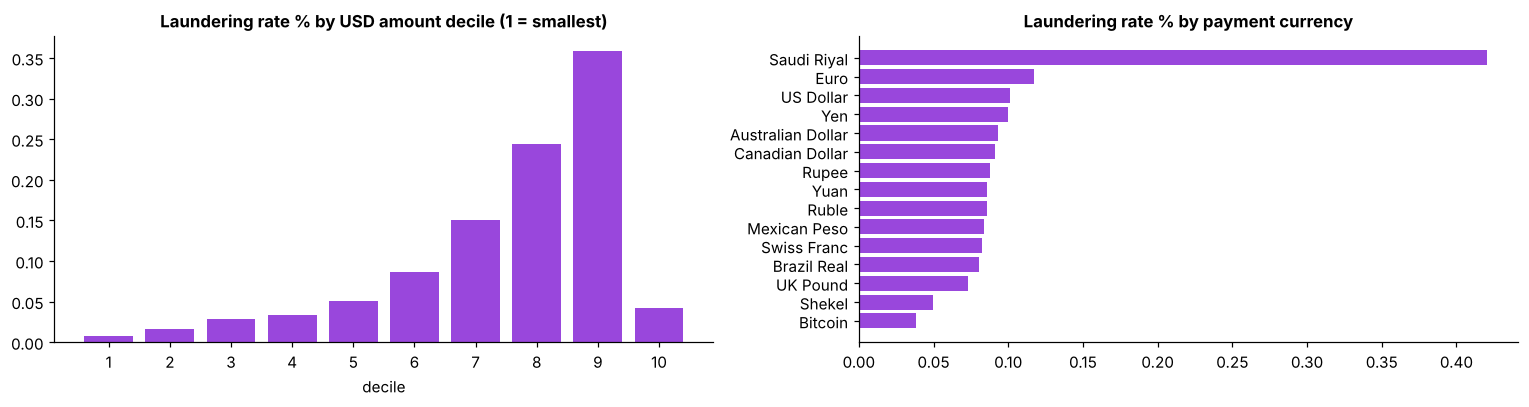

,value,rows,laundering,rate_pct,share_of_laundering_pct,share_of_rows_pct
0,Saudi Riyal,"89,014",374,0.4202,7.2243,1.7528
1,Euro,"1,168,296","1,372",0.1174,26.5018,23.0055
2,US Dollar,"1,895,169","1,912",0.1009,36.9326,37.3187
3,Yen,"155,209",155,0.0999,2.9940,3.0563
4,Australian Dollar,"136,769",127,0.0929,2.4532,2.6932
5,Canadian Dollar,"140,042",128,0.0914,2.4725,2.7576
6,Rupee,"190,202",167,0.0878,3.2258,3.7454
7,Yuan,"213,752",184,0.0861,3.5542,4.2091
8,Ruble,"155,178",133,0.0857,2.5691,3.0557
9,Mexican Peso,"110,159",92,0.0835,1.7771,2.1692


In [21]:
dec = sql('''
    SELECT decile, MIN(usd) AS from_usd, MAX(usd) AS to_usd, COUNT(*) AS rows, SUM(y) AS laundering, 100 * AVG(y) AS rate_pct
    FROM (SELECT usd, "Is Laundering" AS y, NTILE(10) OVER (ORDER BY usd, Timestamp, acct_from, acct_to) AS decile FROM jusd)
    GROUP BY 1 ORDER BY 1
''')
display(fmt_int(dec, ["rows", "laundering"]).round({"from_usd": 2, "to_usd": 2, "rate_pct": 4}))

cur_risk = risk_by('"Payment Currency"')
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].bar(dec["decile"].astype(str), dec["rate_pct"], color=PURPLE)
ax[0].set_title("Laundering rate % by USD amount decile (1 = smallest)"); ax[0].set_xlabel("decile")
c2 = cur_risk.sort_values("rate_pct")
ax[1].barh(c2["value"], c2["rate_pct"], color=PURPLE); ax[1].set_title("Laundering rate % by payment currency")
plt.tight_layout(); plt.show()
display(fmt_int(cur_risk, ["rows", "laundering"]).round(4))

**What the output shows.**
- **Exchange rates are fixed.** Each currency has one rate against the US Dollar (e.g. Euro
  **0.8534**, Yen **105.40**, Yuan **6.6976**), and the largest relative spread of any rate is
  **1.06%** (tiny differences come from rounding small amounts). Every currency gets a rate (0
  missing). So converting to USD is safe and simple: a 15-row lookup table.
- **In USD**, laundering is still bigger: median **5,878.81** vs **891.06** USD (6.6x). The gap
  at the bottom is wide (25th percentile **2,160.56** vs **158.00**).
- **Risk by amount size is not a straight line.** The laundering rate climbs from **0.0075%** in the
  smallest tenth of transfers (under ~30 USD) to **0.3586%** in the 9th tenth (about 8,954–35,398
  USD) — then **drops to 0.0423%** in the largest tenth. Very large transfers are mostly normal.
- **By currency**, Saudi Riyal stands out (**0.4202%**, 4x the average); Bitcoin (**0.0383%**) and
  Shekel (**0.0494%**) are lowest.

**What it means for us.**
- Preprocessing: add `amount_usd = Amount Paid / units_per_usd` using this table, then log-scale it.
- Because risk rises and then falls, a model that can bend (trees, gradient boosting) will use
  amount much better than a straight-line model. If logistic regression is used, give it amount
  buckets, not the raw number.
- The Saudi Riyal effect matches Saudi Arabia being the riskiest sender country (section 9) — the
  same signal seen twice, so do not count it as independent evidence.

<a id="b7"></a>
## <span style="color:#9947dc">7. Self-transfers</span>

**Why.** A self-transfer is an account paying **itself** (`Account` = `Account.1`). In real life that
is not really a transfer — no money changes hands. If there are many, they can distort every
account-level count and every "money in, money out" measure.

**How.** Count them, split by payment format, and see how many are laundering and how many change
currency.

In [22]:
st = sql("""
    SELECT "Payment Format", COUNT(*) AS self_transfers, SUM("Is Laundering") AS laundering,
           SUM(CASE WHEN "Payment Currency" <> "Receiving Currency" THEN 1 ELSE 0 END) AS change_currency
    FROM j WHERE self_transfer = 1 GROUP BY 1 ORDER BY 2 DESC
""")
tot_fmt = sql('SELECT "Payment Format", COUNT(*) AS all_rows FROM j GROUP BY 1')
st = st.merge(tot_fmt, on="Payment Format")
st["self_share_of_format_pct"] = 100 * st["self_transfers"] / st["all_rows"]
display(fmt_int(st, ["self_transfers", "all_rows", "change_currency"]).round(2))

n_self = int(st["self_transfers"].sum())
print(f"Self-transfers: {n_self:,} = {100 * n_self / one('SELECT COUNT(*) FROM j'):.2f}% of all rows; "
      f"laundering among them: {int(st['laundering'].sum())}")
print(f"Different-currency rows that are self-transfers: "
      f"{one('SELECT 100*AVG(self_transfer) FROM j WHERE \"Payment Currency\" <> \"Receiving Currency\"'):.2f}%")

,Payment Format,self_transfers,laundering,change_currency,all_rows,self_share_of_format_pct
0,Reinvestment,"481,056",0.0,0,"481,056",100.00
1,ACH,"71,347",11.0,"69,979","600,793",11.88
2,Bitcoin,"26,317",0.0,0,"146,086",18.01
3,Cheque,"6,066",0.0,0,"1,864,331",0.33
4,Credit Card,"4,176",0.0,0,"1,323,324",0.32
5,Cash,"1,455",0.0,0,"490,891",0.30
6,Wire,795,0.0,0,"171,855",0.46


Self-transfers: 591,212 = 11.64% of all rows; laundering among them: 11
Different-currency rows that are self-transfers: 96.97%


**What the output shows.**
- **591,212** self-transfers = **11.64%** of all rows. Only **11** are laundering.
- **All 481,056 Reinvestment rows are self-transfers** (100%). That explains why Reinvestment has
  zero laundering in section 5: it is not really a payment method, it is an account booking money
  to itself.
- **71,347** ACH rows are self-transfers, and **69,979** of those change currency. In fact
  **96.97%** of all currency-changing rows are self-transfers: this is how the dataset records a
  **currency conversion** — the account "pays itself" from one currency into another.

**What it means for us.** Self-transfers are two things: Reinvestment bookings and currency
conversions. They are not money moving between people. They must be **handled explicitly** in
every account feature (section 13 shows what happens if they are not), and the team has to decide
(open decision 3) whether to keep them as rows the model scores. Our suggestion: keep them in the
data (the conversion step is part of some schemes, section 13), but exclude them when counting an
account's counterparties and money flows.

<a id="b8"></a>
## <span style="color:#9947dc">8. Same bank vs different bank</span>

**Why.** Moving money between banks breaks the paper trail — no single bank sees the whole chain.
If the data reflects that, transfers between banks should be riskier.

**How.** Use the `cross_bank` flag. It compares bank **names**, not bank IDs, because one bank
name can have many IDs in this data (see the note in the output).

In [23]:
cb = risk_by("CASE WHEN cross_bank = 1 THEN 'Different bank' ELSE 'Same bank' END")
display(fmt_int(cb, ["rows", "laundering"]).round(4))
print(f"Different bank is {cb.loc[0, 'rate_pct'] / cb.loc[1, 'rate_pct']:.1f}x riskier")

ids = sql("""
    SELECT name, COUNT(DISTINCT id) AS ids FROM
      (SELECT "Bank Name_from" AS name, "From Bank" AS id FROM j UNION SELECT "Bank Name_to", "To Bank" FROM j)
    GROUP BY 1
""")
print(f"Bank names: {len(ids):,} | names with more than one bank ID: {(ids['ids'] > 1).sum():,} | "
      f"most IDs for one name: {ids['ids'].max()}  -> never group by bank ID, group by bank name")

,value,rows,laundering,rate_pct,share_of_laundering_pct,share_of_rows_pct
0,Different bank,"4,383,014","5,070",0.1157,97.9332,86.3081
1,Same bank,"695,322",107,0.0154,2.0668,13.6919


Different bank is 7.5x riskier


Bank names: 20,053 | names with more than one bank ID: 468 | most IDs for one name: 48  -> never group by bank ID, group by bank name


**What the output shows.** **4,383,014** transfers go between different banks, with **5,070**
laundering rows (**0.1157%**); **695,322** stay inside one bank, with **107** (**0.0154%**).
Different-bank transfers are **7.5x** riskier and carry **97.93%** of all laundering.
**468** of the **20,053** bank names have more than one bank ID (one name has **48**).

**What it means for us.** Keep the `cross_bank` flag. And never group or compare by raw bank ID —
the same bank would be counted as up to 48 different banks. Use the bank **name**.

In [24]:
banks = sql('''
    SELECT "Bank Name_from" AS sender_bank, COUNT(*) AS rows, SUM("Is Laundering") AS laundering,
           100 * AVG("Is Laundering") AS rate_pct
    FROM j GROUP BY 1
''')
banks = banks.sort_values(["laundering", "sender_bank"], ascending=[False, True]).reset_index(drop=True)
banks["cum_share_of_laundering_pct"] = 100 * banks["laundering"].cumsum() / banks["laundering"].sum()
n_with = (banks["laundering"] > 0).sum()
half = (banks["cum_share_of_laundering_pct"] < 50).sum() + 1
print(f"Sender banks (by name): {len(banks):,} | with at least one laundering row: {n_with:,} | "
      f"banks needed to cover 50% of laundering: {half}")
print("\nTop 12 sender banks by number of laundering rows:")
display(fmt_int(banks.head(12), ["rows", "laundering"]).round(4))

Sender banks (by name): 20,053 | with at least one laundering row: 892 | banks needed to cover 50% of laundering: 78

Top 12 sender banks by number of laundering rows:


,sender_bank,rows,laundering,rate_pct,cum_share_of_laundering_pct
0,Oasis Thrift,"450,036",633,0.1407,12.2272
1,National Bank of the East,"82,249",78,0.0948,13.7338
2,China Bank #6,"41,008",67,0.1634,15.0280
3,Israel Bank #6,"19,175",59,0.3077,16.1677
4,Arbor Savings Bank,"70,063",55,0.0785,17.2301
5,National Bank of Laramie,"85,455",55,0.0644,18.2924
6,Finland Bank #0,"29,676",47,0.1584,19.2003
7,Japan Bank #0,"52,511",46,0.0876,20.0889
8,Germany Bank #65,"28,652",40,0.1396,20.8615
9,Savings Bank of Huron,"25,185",36,0.1429,21.5569


**What the output shows.** Of **20,053** sender bank names, only **892** sent any laundering, and
just **78** banks account for half of it. The top bank by laundering count is **Oasis Thrift** (633
laundering rows, **12.23%** of all laundering) — that is the hub accounts again. After it, no single
bank holds more than about 1.5% of laundering. Some smaller banks have high rates (National Bank of
Harrisburg **0.4475%** on 7,822 rows; Israel Bank #6 **0.3077%**).

**What it means for us.** Laundering is spread over many banks; there is no single "bad bank" except
the hub bank. Bank name as a feature would mostly let the model memorise banks — risky with ~20,000
of them. Prefer country and the cross-bank flag, and if a bank-level feature is wanted, use a
point-in-time "laundering seen at this bank before" rate computed on training data only.

<a id="b9"></a>
## <span style="color:#9947dc">9. Countries and cross-border</span>

**Why.** Money crossing borders is the classic risk sign that real banks screen for. We check
whether it holds here, and which routes (sender country → receiver country) are riskiest.

**How.** Rate for cross-border vs same country; rate by sender country; and the riskiest country
pairs with at least 1,000 transfers (smaller pairs give unreliable rates). Remember: "country" is
read from the bank name, and `Domestic/Other` means the bank name had no country in it.

In [25]:
cbd = risk_by("CASE WHEN cross_border = 1 THEN 'Cross-border' ELSE 'Same country' END")
display(fmt_int(cbd, ["rows", "laundering"]).round(4))
print(f"Cross-border is {cbd.loc[0, 'rate_pct'] / cbd.loc[1, 'rate_pct']:.1f}x riskier")

print("\nBy sender country (at least 10,000 transfers):")
sc = risk_by('"Country_from"', min_rows=10_000)
display(fmt_int(sc.head(12), ["rows", "laundering"]).round(4))

pairs = risk_by("\"Country_from\" || ' -> ' || \"Country_to\"", min_rows=1_000)
print("\nRiskiest routes (at least 1,000 transfers):")
display(fmt_int(pairs.head(15), ["rows", "laundering"]).round(4))
print(f"Of the top 15 routes, {pairs.head(15)['value'].str.endswith('-> Domestic/Other').sum()} end at a domestic bank.")

,value,rows,laundering,rate_pct,share_of_laundering_pct,share_of_rows_pct
0,Cross-border,"1,424,959","3,124",0.2192,60.3438,28.0596
1,Same country,"3,653,377","2,053",0.0562,39.6562,71.9404


Cross-border is 3.9x riskier

By sender country (at least 10,000 transfers):


,value,rows,laundering,rate_pct,share_of_laundering_pct,share_of_rows_pct
0,Saudi Arabia,"62,265",281,0.4513,5.4457,1.2300
1,Finland,"35,463",85,0.2397,1.6473,0.7006
2,Spain,"111,538",151,0.1354,2.9264,2.2034
3,Belgium,"41,134",51,0.1240,0.9884,0.8126
4,Portugal,"31,084",35,0.1126,0.6783,0.6141
5,China,"261,708",285,0.1089,5.5233,5.1699
6,Slovakia,"13,079",14,0.1070,0.2713,0.2584
7,Austria,"38,534",41,0.1064,0.7946,0.7612
8,Domestic/Other,"2,299,509","2,369",0.1030,45.9109,45.4260
9,Japan,"162,993",163,0.1000,3.1589,3.2199



Riskiest routes (at least 1,000 transfers):


,value,rows,laundering,rate_pct,share_of_laundering_pct,share_of_rows_pct
0,Japan -> Domestic/Other,"1,896",49,2.5844,1.0838,0.0379
1,UK -> Domestic/Other,"2,357",49,2.0789,1.0838,0.0471
2,Saudi Arabia -> Israel,"3,503",62,1.7699,1.3714,0.0699
3,Canada -> Domestic/Other,"1,990",33,1.6583,0.7299,0.0397
4,Netherlands -> Domestic/Other,"1,017",16,1.5733,0.3539,0.0203
5,Spain -> Domestic/Other,"3,125",43,1.3760,0.9511,0.0624
6,Spain -> Finland,"1,533",21,1.3699,0.4645,0.0306
7,France -> Domestic/Other,"3,930",49,1.2468,1.0838,0.0785
8,Australia -> Domestic/Other,"2,398",28,1.1676,0.6193,0.0479
9,Germany -> Domestic/Other,"8,912",94,1.0548,2.0792,0.1779


Of the top 15 routes, 11 end at a domestic bank.


**What the output shows.**
- Cross-border transfers are **28.06%** of rows but carry **60.34%** of laundering: rate
  **0.2192%** vs **0.0562%** for same-country, so **3.9x** riskier.
- By sender country, Saudi Arabia is highest (**0.4513%**, on 62,265 transfers), then Finland
  (**0.2397%**) and Spain (**0.1354%**). `Domestic/Other` holds **45.43%** of all rows at
  **0.1030%**.
- The riskiest routes are 10–25x the average: Japan → Domestic **2.5844%**, UK → Domestic
  **2.0789%**, Saudi Arabia → Israel **1.7699%**. Some go both ways: Spain → Finland **1.3699%** and
  Finland → Spain **0.9434%**.
- **11** of the top 15 routes end at a domestic bank.

**What it means for us.** Cross-border is a solid, realistic signal — keep `cross_border`, and the
sender and receiver country. Be careful with individual routes: each one has only 16–94 laundering
rows, so their exact rates are noisy and partly reflect how the generator placed its schemes.
Country is read from the bank name, so say in the report that `Domestic/Other` means "no country in
the bank name".

By receiver country (at least 10,000 transfers):


,value,rows,laundering,rate_pct,share_of_laundering_pct,share_of_rows_pct
0,Finland,"22,135",96,0.4337,1.8576,0.4374
1,Saudi Arabia,"76,829",280,0.3644,5.4180,1.5182
2,Spain,"131,689",191,0.1450,3.6958,2.6023
3,Belgium,"51,257",64,0.1249,1.2384,1.0129
4,Germany,"329,456",357,0.1084,6.9079,6.5103
5,France,"198,770",215,0.1082,4.1602,3.9278
6,Italy,"159,781",172,0.1076,3.3282,3.1574
7,Greece,"35,041",36,0.1027,0.6966,0.6924
8,Domestic/Other,"1,978,320","2,002",0.1012,38.7384,39.0931
9,Japan,"171,206",170,0.0993,3.2895,3.3832



How the 20,053 bank names were mapped to a country (34 labels; top 12 shown):


,0,1,2,3,4,5,6,7,8,9,10,11
country,Germany,Switzerland,Israel,France,India,China,UK,Russia,Italy,Japan,Australia,Crypto exchange
bank_names,1571,1514,1320,1278,1270,1177,1161,1073,1045,1023,963,943


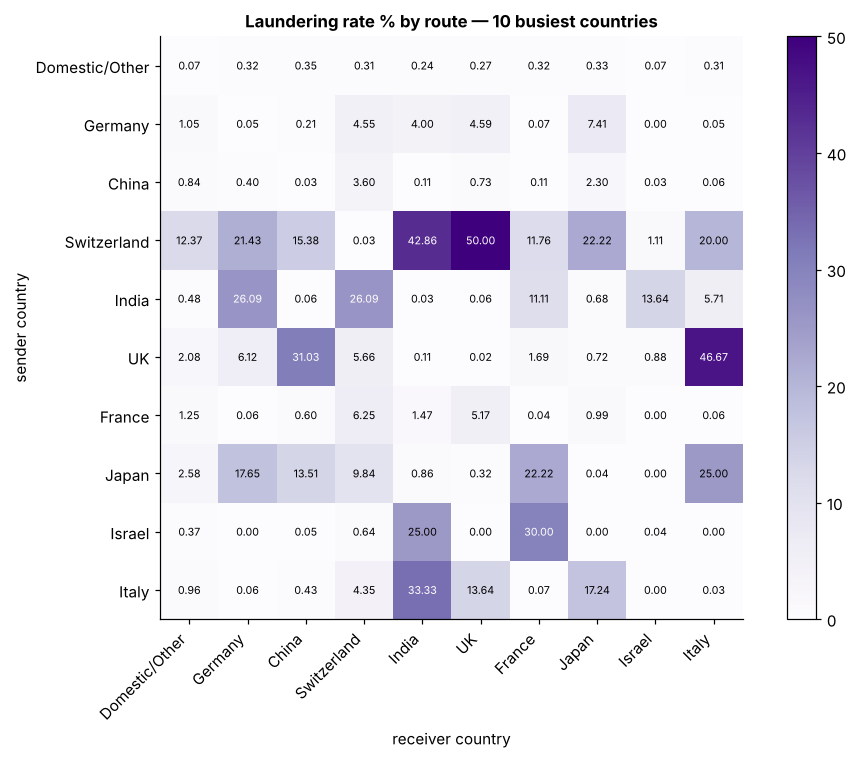

The five hottest cells, with how many transfers are behind them:


,sender,receiver,rate_pct,rows,same_country
0,Switzerland,UK,50.00,14,False
1,UK,Italy,46.67,15,False
2,Switzerland,India,42.86,7,False
3,Italy,India,33.33,6,False
4,UK,China,31.03,29,False


Same-country cells (the diagonal):


,sender,receiver,rate_pct,rows,same_country
0,Domestic/Other,Domestic/Other,0.068,1898873,True
1,Switzerland,Switzerland,0.028,212593,True
2,China,China,0.034,196321,True
3,UK,UK,0.023,147763,True
4,Israel,Israel,0.040,144140,True
5,Japan,Japan,0.036,143173,True
6,India,India,0.026,138812,True
7,Germany,Germany,0.046,116365,True
8,France,France,0.043,46308,True
9,Italy,Italy,0.030,33516,True


In [26]:
print("By receiver country (at least 10,000 transfers):")
rc = risk_by('"Country_to"', min_rows=10_000)
display(fmt_int(rc.head(12), ["rows", "laundering"]).round(4))

census = sql('''
    SELECT country, COUNT(*) AS bank_names FROM
      (SELECT DISTINCT "Bank Name_from" AS bank, "Country_from" AS country FROM j
       UNION SELECT DISTINCT "Bank Name_to", "Country_to" FROM j)
    GROUP BY 1 ORDER BY 2 DESC
''')
print(f"\nHow the {census['bank_names'].sum():,} bank names were mapped to a country "
      f"({len(census)} labels; top 12 shown):")
display(census.head(12).T)

top = sql('''SELECT "Country_from" AS c FROM j GROUP BY 1 ORDER BY COUNT(*) DESC LIMIT 10''')["c"].tolist()
in_list = ", ".join("'" + c + "'" for c in top)
hm = sql(f'''
    SELECT "Country_from" AS sender, "Country_to" AS receiver, 100 * AVG("Is Laundering") AS rate_pct, COUNT(*) AS rows
    FROM j WHERE "Country_from" IN ({in_list}) AND "Country_to" IN ({in_list}) GROUP BY 1, 2
''')
piv = hm.pivot(index="sender", columns="receiver", values="rate_pct").reindex(index=top, columns=top)
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(piv.values, cmap="Purples")
ax.set_xticks(range(len(top)), top, rotation=45, ha="right"); ax.set_yticks(range(len(top)), top)
for i in range(len(top)):
    for k in range(len(top)):
        v = piv.values[i, k]
        if pd.notna(v):
            ax.text(k, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if v > np.nanmax(piv.values) / 2 else "black")
ax.set_xlabel("receiver country"); ax.set_ylabel("sender country")
ax.set_title("Laundering rate % by route — 10 busiest countries")
plt.colorbar(im, fraction=0.04); plt.tight_layout(); plt.show()
hm["same_country"] = hm["sender"] == hm["receiver"]
print("The five hottest cells, with how many transfers are behind them:")
display(hm.sort_values(["rate_pct", "sender", "receiver"], ascending=[False, True, True]).head(5).round(2).reset_index(drop=True))
print("Same-country cells (the diagonal):")
display(hm[hm["same_country"]].sort_values("rows", ascending=False).round(3).reset_index(drop=True))

**What the output shows.**
- By **receiver** country, Finland (**0.4337%**) and Saudi Arabia (**0.3644%**) are highest — the same
  two countries that top the sender list. Spain is third on both lists.
- **Country mapping:** 20,053 bank names became **34** labels. The biggest groups are Germany
  (**1,571** bank names), Switzerland (1,514) and Israel (1,320). **943** names are crypto exchanges
  (`Crytpo Bank #n`, misspelled in the source).
- The route heatmap (10 busiest countries) has three clear zones:
  - **the diagonal (same country) is near zero** everywhere — between **0.023%** (UK → UK) and
    **0.068%** (Domestic → Domestic), on 33,516 to 1,898,873 transfers per cell;
  - **foreign → Domestic/Other** routes are well above average (mostly 0.4%–2.6%), while
    Domestic/Other → foreign sits around 0.24%–0.35%;
  - **the Switzerland row stands out**: every Swiss route abroad is above 1% (Switzerland →
    Domestic **12.37%**), while Switzerland → Switzerland is **0.028%**;
  - **the most extreme cells are tiny**: Switzerland → UK **50.00%** is **14** transfers, UK → Italy
    **46.67%** is **15**, and the top five hot cells have only **6 to 29** transfers each.

**What it means for us.** Sender country and receiver country both carry signal, and the same
countries are risky in both directions — consistent with schemes that move money back and forth.
The heatmap is the cross-border finding drawn as a picture: same-country is safe, crossing is not.
Use sender country, receiver country and the cross-border flag; do **not** use the route itself as a
feature — the most extreme routes rest on a handful of transfers and a model would memorise them.

<a id="b10"></a>
## <span style="color:#9947dc">10. Entities</span>

**Why.** An entity is the owner behind an account (a person or a company), and one owner can have
several accounts. Moving money between your own accounts is a known layering step, so we expected
**same-owner** transfers to be riskier.

**How.** Rate for same owner vs different owner; rate by owner type (Corporation, Sole
Proprietorship, ...); how many accounts each owner has.

In [27]:
se = risk_by("CASE WHEN same_entity = 1 THEN 'Same owner' ELSE 'Different owner' END")
display(fmt_int(se, ["rows", "laundering"]).round(4))
print(f"Same owner is {se.loc[0, 'rate_pct'] / se.loc[1, 'rate_pct']:.0f}x SAFER than different owner")

print("\nSame owner, excluding self-transfers (an account paying itself is trivially 'same owner'):")
se2 = risk_by("CASE WHEN same_entity = 1 THEN 'Same owner' ELSE 'Different owner' END", where="self_transfer = 0")
display(fmt_int(se2, ["rows", "laundering"]).round(4))
print(f"Without self-transfers, same owner is {se2.loc[0, 'rate_pct'] / se2.loc[1, 'rate_pct']:.1f}x safer")

print("\nBy sender owner type:")
display(fmt_int(risk_by('"Entity Type_from"'), ["rows", "laundering"]).round(4))

ape = sql("""
    SELECT accounts, COUNT(*) AS owners FROM (
      SELECT ent, COUNT(DISTINCT acct) AS accounts FROM
        (SELECT "Entity ID_from" AS ent, acct_from AS acct FROM j UNION SELECT "Entity ID_to", acct_to FROM j)
      GROUP BY 1) GROUP BY 1 ORDER BY 1
""")
print("\nAccounts per owner (owners that appear in transfers):")
display(ape.head(8).T)

,value,rows,laundering,rate_pct,share_of_laundering_pct,share_of_rows_pct
0,Different owner,"4,417,002","5,142",0.1164,99.3239,86.9773
1,Same owner,"661,334",35,0.0053,0.6761,13.0227


Same owner is 22x SAFER than different owner

Same owner, excluding self-transfers (an account paying itself is trivially 'same owner'):


,value,rows,laundering,rate_pct,share_of_laundering_pct,share_of_rows_pct
0,Different owner,"4,417,002","5,142",0.1164,99.5354,98.4373
1,Same owner,"70,122",24,0.0342,0.4646,1.5627


Without self-transfers, same owner is 3.4x safer

By sender owner type:


,value,rows,laundering,rate_pct,share_of_laundering_pct,share_of_rows_pct
0,Individual,"4,323",6,0.1388,0.1159,0.0851
1,Corporation,"1,409,467","1,783",0.1265,34.4408,27.7545
2,Partnership,"1,781,365","1,805",0.1013,34.8658,35.0777
3,Sole Proprietorship,"1,790,826","1,552",0.0867,29.9788,35.2640
4,Country,"91,852",31,0.0337,0.5988,1.8087
5,Direct,503,0,0.0000,0.0000,0.0099



Accounts per owner (owners that appear in transfers):


,0,1,2,3,4,5,6,7
accounts,1,2,3,4,5,6,7,8
owners,102971,15979,11610,9827,8370,6059,4134,2412


**What the output shows.**
- At first sight, transfers between accounts of the **same owner** look very safe: **0.0053%** vs
  **0.1164%**, **22x** safer.
- But most "same owner" rows are self-transfers (an account paying itself is trivially the same
  owner). **Without self-transfers**, same-owner transfers are **70,122** rows with **24**
  laundering: **0.0342%**, so only about **3.4x** safer.
- By owner type, rates range from **0.1388%** (Individual, but only 4,323 rows) and **0.1265%**
  (Corporation) down to **0.0867%** (Sole Proprietorship) and **0.0337%** ("Country").
- Most owners have one account (**102,971**); many have several (15,979 with two, 11,610 with
  three, and so on).

**What it means for us.** Our hypothesis (moving money between your own accounts = layering) is
**not** supported — same-owner transfers are safer, not riskier. But the "22x safer" in the previous
EDA was mostly the self-transfer effect. The honest number is **3.4x safer**. Keep `same_entity` as
mild evidence of legitimacy. Owner type differences are small; it can be a feature but will not
carry much.

In [28]:
tp = sql('''
    SELECT "Entity Type_from" AS sender_type, "Entity Type_to" AS receiver_type,
           COUNT(*) AS rows, 100 * AVG("Is Laundering") AS rate_pct
    FROM j WHERE self_transfer = 0 GROUP BY 1, 2
''')
types_ = ["Corporation", "Partnership", "Sole Proprietorship", "Individual", "Country", "Direct"]
piv = tp.pivot(index="sender_type", columns="receiver_type", values="rate_pct").reindex(index=types_, columns=types_)
pivn = tp.pivot(index="sender_type", columns="receiver_type", values="rows").reindex(index=types_, columns=types_)
print("Laundering rate % by owner type pair (self-transfers removed):")
display(piv.round(4))
print("Rows behind each cell:")
display(pivn.fillna(0).astype(int))

own = sql('''
    WITH n_acc AS (
        SELECT ent, COUNT(DISTINCT acct) AS accounts FROM
          (SELECT "Entity ID_from" AS ent, acct_from AS acct FROM j UNION SELECT "Entity ID_to", acct_to FROM j)
        GROUP BY 1)
    SELECT CASE WHEN accounts >= 5 THEN '5+' ELSE CAST(accounts AS VARCHAR) END AS sender_owner_accounts,
           COUNT(*) AS rows, SUM("Is Laundering") AS laundering, 100 * AVG("Is Laundering") AS rate_pct
    FROM j JOIN n_acc ON j."Entity ID_from" = n_acc.ent
    WHERE self_transfer = 0 GROUP BY 1 ORDER BY 1
''')
print("Laundering rate by how many accounts the sender's owner has (self-transfers removed):")
display(fmt_int(own, ["rows", "laundering"]).round(4))

Laundering rate % by owner type pair (self-transfers removed):


receiver_type,Corporation,Partnership,Sole Proprietorship,Individual,Country,Direct
sender_type,,,,,,
Corporation,0.1502,0.1515,0.1366,0.0,0.1880,0.0
Partnership,0.1246,0.1157,0.1069,0.0,0.0549,0.0
Sole Proprietorship,0.1061,0.0970,0.0861,0.0,0.0000,0.0
Individual,0.0776,0.2588,0.1842,0.0,NaN,0.0
Country,0.0000,0.0483,0.0594,NaN,0.0317,NaN
Direct,0.0000,0.0000,0.0000,0.0,NaN,0.0


Rows behind each cell:


receiver_type,Corporation,Partnership,Sole Proprietorship,Individual,Country,Direct
sender_type,,,,,,
Corporation,374880,424975,420195,746,532,26
Partnership,467748,558468,529281,808,14565,49
Sole Proprietorship,478948,565193,566564,694,3042,36
Individual,1289,1159,1086,95,0,6
Country,215,33147,5054,0,37873,0
Direct,154,122,145,1,0,28


Laundering rate by how many accounts the sender's owner has (self-transfers removed):


,sender_owner_accounts,rows,laundering,rate_pct
0,1,"1,710,383","1,732",0.1013
1,2,"302,784",403,0.1331
2,3,"252,103",300,0.1190
3,4,"244,070",312,0.1278
4,5+,"1,977,784","2,419",0.1223


**What the output shows.**
- By owner-type pair (self-transfers removed), Corporation → Corporation / Partnership are the
  highest of the busy pairs (**0.1502%** / **0.1515%**); Sole Proprietorship → Sole Proprietorship is
  lower (**0.0861%**). Cells with Individual or Direct have at most about 1,300 rows, so
  their rates (0% or 0.26%) are noise.
- Owners with more accounts are not clearly riskier: **0.1013%** for one-account owners vs
  **0.1190%–0.1331%** for owners with 2, 3, 4 or 5+ accounts.

**What it means for us.** Owner type adds a small, real difference (companies slightly riskier than
sole proprietors). Number of accounts per owner barely matters. Low priority features.

<a id="b11"></a>
## <span style="color:#9947dc">11. Account network and hub accounts</span>

**Why.** Our system investigates **accounts and their connections**, not single rows. So we need
account-level behaviour: how many transfers an account makes (its **degree**), how many different
accounts it deals with (its **counterparties**), and how many transfers it **receives**.

We also have to deal with **hub accounts**: a few accounts that deal with thousands of others. They
look like clearing accounts, not customers. If they touch laundering, they can make "busy accounts
are suspicious" look true when it is really just a handful of accounts.

**How.** Build one row per account over the whole file. Call an account "laundering-involved" if
it is on either side of at least one laundering transfer. Compare medians, with and without hubs
(hub = 500 or more different counterparties).

In [29]:
con.execute("""
    CREATE OR REPLACE TABLE acc AS
    SELECT acct,
           COUNT(*) AS degree,
           COUNT(DISTINCT cpty) AS counterparties,
           SUM(CASE WHEN side = 'out' THEN 1 ELSE 0 END) AS sent,
           SUM(CASE WHEN side = 'in' THEN 1 ELSE 0 END) AS received,
           SUM(y) AS laundering_rows,
           MIN(t) AS first_seen, MAX(t) AS last_seen
    FROM (SELECT acct_from AS acct, acct_to AS cpty, 'out' AS side, "Is Laundering" AS y, Timestamp AS t FROM j
          UNION ALL
          SELECT acct_to, acct_from, 'in', "Is Laundering", Timestamp FROM j)
    GROUP BY 1
""")
con.execute("ALTER TABLE acc ADD COLUMN involved BOOLEAN; UPDATE acc SET involved = laundering_rows > 0")
con.execute("ALTER TABLE acc ADD COLUMN hub BOOLEAN; UPDATE acc SET hub = counterparties >= 500")

print(f"Accounts: {one('SELECT COUNT(*) FROM acc'):,} | laundering-involved: {one('SELECT SUM(CAST(involved AS INT)) FROM acc'):,} "
      f"({one('SELECT 100*AVG(CAST(involved AS INT)) FROM acc'):.3f}%) | hubs: {one('SELECT SUM(CAST(hub AS INT)) FROM acc')}")

net = sql("""
    SELECT 'All accounts' AS accounts, involved,
           MEDIAN(degree) AS degree, MEDIAN(counterparties) AS counterparties, MEDIAN(sent) AS sent,
           MEDIAN(received) AS received, AVG(degree) AS mean_degree
    FROM acc GROUP BY 1, 2
    UNION ALL
    SELECT 'Hubs removed', involved, MEDIAN(degree), MEDIAN(counterparties), MEDIAN(sent), MEDIAN(received), AVG(degree)
    FROM acc WHERE NOT hub GROUP BY 1, 2
    ORDER BY 1, 2
""")
display(net.round(1))

Accounts: 515,088 | laundering-involved: 6,357 (1.234%) | hubs: 15


,accounts,involved,degree,counterparties,sent,received,mean_degree
0,All accounts,False,6.0,2.0,2.0,2.0,18.7
1,All accounts,True,22.0,5.0,4.0,13.0,102.8
2,Hubs removed,False,6.0,2.0,2.0,2.0,18.7
3,Hubs removed,True,22.0,5.0,4.0,13.0,31.6


,acct,degree,counterparties,laundering_rows,share_of_all_rows_pct,bank,owner
0,70:100428660,"169,756","14,775",243,1.671,Oasis Thrift,Sole Proprietorship #41
1,70:1004286A8,"103,671","9,174",158,1.021,Oasis Thrift,Partnership #2370
2,70:100428978,"20,647","1,851",29,0.203,Oasis Thrift,Sole Proprietorship #36613
3,70:1004286F0,"18,771","1,630",21,0.185,Oasis Thrift,Partnership #30358
4,70:100428780,"17,381","1,482",21,0.171,Oasis Thrift,Sole Proprietorship #31648
5,70:1004289C0,"16,926","1,500",13,0.167,Oasis Thrift,Sole Proprietorship #37508
6,70:100428810,"16,540","1,452",26,0.163,Oasis Thrift,Sole Proprietorship #10935
7,70:1004287C8,"14,277","1,236",16,0.141,Oasis Thrift,Corporation #31479
8,70:100428738,"13,854","1,187",23,0.136,Oasis Thrift,Corporation #29514
9,70:100428A51,"13,101","1,161",18,0.129,Oasis Thrift,Country #1


Old EDA definition (top 0.01% by degree = 260+ transfers, OR 500+ counterparties): 55 accounts
This notebook and 02_subsample_split.py (500+ counterparties only): 15 accounts


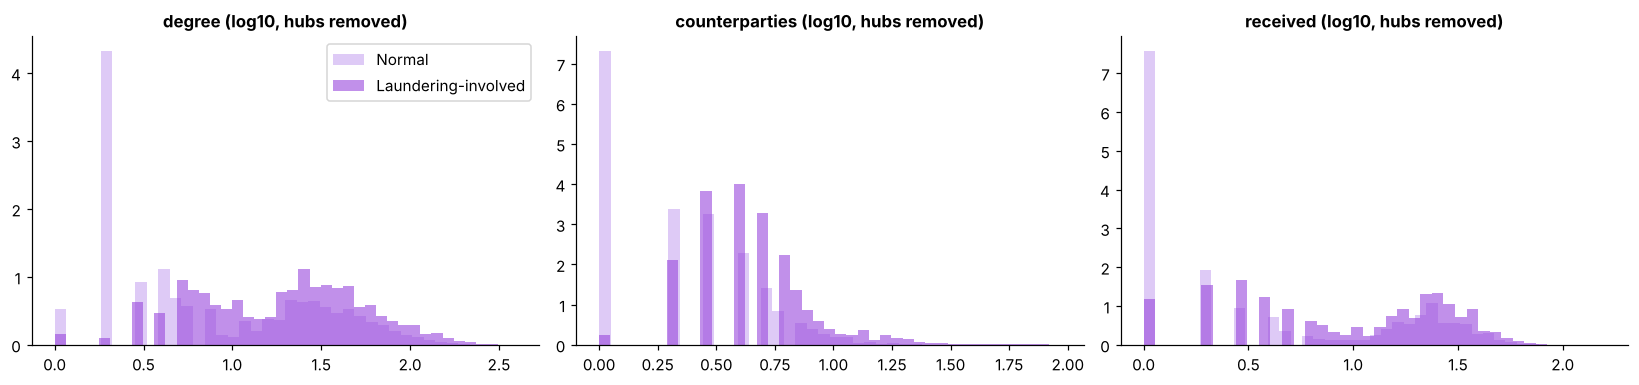

In [30]:
hubs = sql("""
    SELECT a.acct, a.degree, a.counterparties, a.laundering_rows,
           100 * a.degree / (2.0 * (SELECT COUNT(*) FROM j)) AS share_of_all_rows_pct,
           b.bank, b.owner
    FROM acc a
    LEFT JOIN (SELECT acct_from AS acct, ANY_VALUE("Bank Name_from") AS bank, ANY_VALUE("Entity Name_from") AS owner
               FROM j GROUP BY 1) b USING (acct)
    WHERE a.hub ORDER BY a.degree DESC
""")
display(fmt_int(hubs, ["degree", "counterparties", "laundering_rows"]).round(3))

old_def = one("SELECT COUNT(*) FROM acc WHERE degree >= (SELECT quantile_cont(degree, 0.9999) FROM acc) OR counterparties >= 500")
print(f"Old EDA definition (top 0.01% by degree = {one('SELECT quantile_cont(degree, 0.9999) FROM acc'):.0f}+ transfers, "
      f"OR 500+ counterparties): {old_def} accounts")
print(f"This notebook and 02_subsample_split.py (500+ counterparties only): {len(hubs)} accounts")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
d = sql("SELECT involved, degree, counterparties, received FROM acc WHERE NOT hub")
for i, col in enumerate(["degree", "counterparties", "received"]):
    for flag, colour, name in [(False, LILAC, "Normal"), (True, PURPLE, "Laundering-involved")]:
        v = d.loc[d["involved"] == flag, col]
        ax[i].hist(np.log10(v.clip(lower=1)), bins=40, density=True, alpha=0.6, color=colour, label=name)
    ax[i].set_title(f"{col} (log10, hubs removed)")
ax[0].legend(); plt.tight_layout(); plt.show()

**What the output shows.**
- **515,088** accounts appear in the data; **6,357** (**1.234%**) touch laundering.
- Laundering-involved accounts are much more active. Medians, normal vs laundering-involved:
  **degree 6 vs 22**, **counterparties 2 vs 5**, **sent 2 vs 4**, **received 2 vs 13**.
  *Received* is the biggest gap: laundering accounts collect money from many transfers.
- Removing hubs does **not** change any median, so the signal is real and not caused by a few
  giant accounts. It does change the **mean** degree of laundering-involved accounts a lot
  (**102.8 → 31.6**): averages are wrecked by hubs, medians are not.
- There are **15** hub accounts (500+ counterparties). All are at **Oasis Thrift**, all have account
  numbers starting `100428`, and the biggest (`70:100428660`) has **169,756** transfers and
  **14,775** counterparties — **1.671%** of all account-sides in the file. All 15 touch laundering.

**Reconciling "55 hubs" vs "15 hubs".** Both are right — they use different definitions. The
previous EDA counted an account as a hub if it was in the top 0.01% by transfers (**260+**) **or**
had 500+ counterparties: that gives **55**. The sampling script uses 500+ counterparties only:
**15**. We use 15 everywhere from now on.

*Small note:* the previous EDA reported counterparties 3 vs 6. It added "accounts I sent to" and
"accounts I received from", counting an account twice if money went both ways. Here each
counterparty is counted once: 2 vs 5.

**What it means for us.** Over the whole window, laundering-involved accounts are clearly busier,
and that is useful for **understanding** them and for the agent's account summaries. Two rules for
any activity number: use medians or log-scaled values (hubs destroy averages), and add a hub flag.
**But careful:** a model sees one transfer at a time, using only the past. Section 12b shows that
the point-in-time versions of these counts are much weaker — and even point the other way. Read 12b
before building account features.

<a id="b11b"></a>
## <span style="color:#9947dc">11b. Account shape: senders, receivers and both</span>

**Why.** Section 11 compared typical accounts. Two more questions: does the *role* of an account
matter (only sends, only receives, or both)? And how does the share of laundering accounts change
as accounts get busier — is it a smooth rise or a jump?

**How.** Put every account (hubs removed, self-transfers ignored) in a role group and a degree
bucket, and compute the share of laundering-involved accounts in each.

,role,accounts,laundering_involved,involved_pct
0,only receives,"116,978","1,150",0.983
1,only sends,"138,340",682,0.493
2,sends and receives,"167,401","4,510",2.694


,degree_bucket,accounts,laundering_involved,involved_pct
0,1,"48,245",474,0.982
1,2-5,"145,597","1,356",0.931
2,6-10,"18,585",572,3.078
3,11-25,"88,274","1,505",1.705
4,26-50,"75,404","1,434",1.902
5,51-100,"39,182",732,1.868
6,101+,"7,432",269,3.619


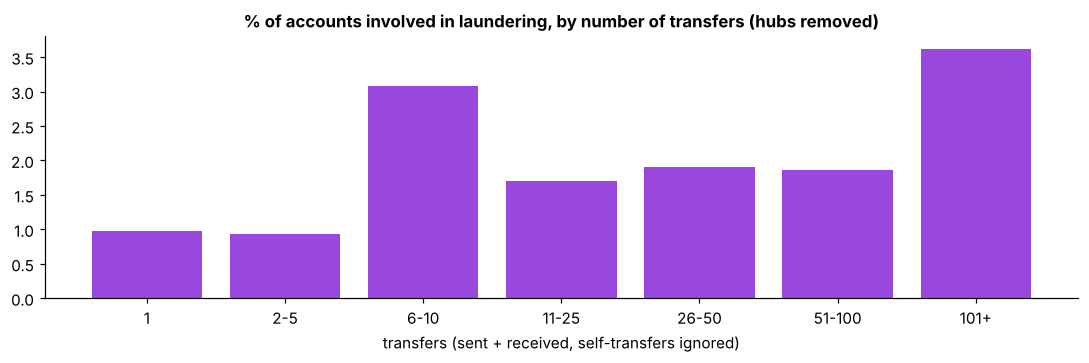

In [31]:
con.execute('''
    CREATE OR REPLACE TABLE acc2 AS
    SELECT acct, SUM(o) AS sent, SUM(i) AS received, MAX(y) AS involved
    FROM (SELECT acct_from AS acct, 1 AS o, 0 AS i, "Is Laundering" AS y FROM j WHERE self_transfer = 0
          UNION ALL SELECT acct_to, 0, 1, "Is Laundering" FROM j WHERE self_transfer = 0)
    GROUP BY 1
''')
role = sql('''
    SELECT CASE WHEN sent > 0 AND received > 0 THEN 'sends and receives'
                WHEN sent > 0 THEN 'only sends' ELSE 'only receives' END AS role,
           COUNT(*) AS accounts, SUM(involved) AS laundering_involved, 100 * AVG(involved) AS involved_pct
    FROM acc2 WHERE acct NOT IN (SELECT acct FROM acc WHERE hub) GROUP BY 1 ORDER BY 1
''')
display(fmt_int(role, ["accounts", "laundering_involved"]).round(3))

deg = sql('''
    SELECT CASE WHEN d = 1 THEN '1' WHEN d <= 5 THEN '2-5' WHEN d <= 10 THEN '6-10' WHEN d <= 25 THEN '11-25'
                WHEN d <= 50 THEN '26-50' WHEN d <= 100 THEN '51-100' ELSE '101+' END AS degree_bucket,
           MIN(d) AS lo, COUNT(*) AS accounts, SUM(involved) AS laundering_involved, 100 * AVG(involved) AS involved_pct
    FROM (SELECT acct, sent + received AS d, involved FROM acc2 WHERE acct NOT IN (SELECT acct FROM acc WHERE hub))
    GROUP BY 1 ORDER BY lo
''')
display(fmt_int(deg.drop(columns="lo"), ["accounts", "laundering_involved"]).round(3))

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(deg["degree_bucket"], deg["involved_pct"], color=PURPLE)
ax.set_title("% of accounts involved in laundering, by number of transfers (hubs removed)")
ax.set_xlabel("transfers (sent + received, self-transfers ignored)")
plt.tight_layout(); plt.show()

**What the output shows.**
- **Role matters:** accounts that both send and receive are laundering-involved **2.694%** of the
  time, vs **0.983%** for receive-only and **0.493%** for send-only accounts. Money has to come in and
  go out for an account to be a layering step.
- **Busyness is not a smooth rise:** **0.982%** of one-transfer accounts are involved, **3.078%** at
  6–10 transfers, back down to about **1.7–1.9%** at 11–100, and **3.619%** at 101+.

**What it means for us.** The "in and out" role is a cleaner account signal than raw activity. A
point-in-time version is easy: "has this sender ever received money before?" and "how many
distinct accounts has it received from?".

<a id="b11c"></a>
## <span style="color:#9947dc">11c. New vs repeat counterparties</span>

**Why.** A classic AML question: *is this the first time this sender has ever paid this receiver?*
Normal businesses pay the same suppliers and staff again and again. Laundering moves money to fresh
accounts. This is also a feature that can be computed honestly at the moment of the transfer — it
only needs the past.

**How.** For every transfer (self-transfers removed), count how many times the same sender → receiver
pair transacted **before** it. 0 = a brand-new pair. Then compare laundering rates for new vs repeat
pairs, and by how many times the pair was seen before. We also check **two-way pairs** (A paid B and
B paid A at some point in the window).

In [32]:
con.execute('''
    CREATE OR REPLACE TABLE pairs AS
    SELECT "Is Laundering" AS y,
           ROW_NUMBER() OVER (PARTITION BY acct_from, acct_to ORDER BY Timestamp, "Amount Paid", "Payment Format") - 1 AS pair_prev
    FROM j WHERE self_transfer = 0
''')
newp = sql('''
    SELECT CASE WHEN pair_prev = 0 THEN 'new pair (first time)' ELSE 'repeat pair' END AS pair,
           COUNT(*) AS rows, SUM(y) AS laundering, 100 * AVG(y) AS rate_pct,
           100.0 * SUM(y) / (SELECT SUM(y) FROM pairs) AS share_of_laundering_pct
    FROM pairs GROUP BY 1 ORDER BY 1
''')
display(fmt_int(newp, ["rows", "laundering"]).round(4))
print(f"New pairs are {newp.loc[0, 'rate_pct'] / newp.loc[1, 'rate_pct']:.1f}x riskier than repeat pairs")

byprev = sql('''
    SELECT CASE WHEN pair_prev >= 5 THEN '5+' ELSE CAST(pair_prev AS VARCHAR) END AS times_seen_before,
           COUNT(*) AS rows, SUM(y) AS laundering, 100 * AVG(y) AS rate_pct
    FROM pairs GROUP BY 1 ORDER BY 1
''')
display(fmt_int(byprev, ["rows", "laundering"]).round(4))

recip = sql('''
    WITH p AS (SELECT DISTINCT acct_from, acct_to FROM j WHERE self_transfer = 0)
    SELECT CASE WHEN r.acct_from IS NULL THEN 'one-way pair' ELSE 'two-way pair' END AS pair,
           COUNT(*) AS rows, SUM("Is Laundering") AS laundering, 100 * AVG("Is Laundering") AS rate_pct
    FROM j LEFT JOIN p r ON j.acct_from = r.acct_to AND j.acct_to = r.acct_from
    WHERE j.self_transfer = 0 GROUP BY 1 ORDER BY 1
''')
display(fmt_int(recip, ["rows", "laundering"]).round(4))

,pair,rows,laundering,rate_pct,share_of_laundering_pct
0,new pair (first time),"647,939","4,013",0.6193,77.681
1,repeat pair,"3,839,185","1,153",0.0300,22.319


New pairs are 20.6x riskier than repeat pairs


,times_seen_before,rows,laundering,rate_pct
0,0,"647,939","4,013",0.6193
1,1,"425,162",429,0.1009
2,2,"289,093",87,0.0301
3,3,"258,828",80,0.0309
4,4,"225,891",60,0.0266
5,5+,"2,640,211",497,0.0188


,pair,rows,laundering,rate_pct
0,one-way pair,"4,478,085","4,712",0.1052
1,two-way pair,"9,039",454,5.0227


**What the output shows.**
- **77.68%** of all laundering transfers go to a receiver the sender has **never paid before**,
  while only about 14% of all transfers are first-time pairs (**647,939** of ~4.49 million). The
  laundering rate on first-time pairs is **0.6193%** vs **0.0300%** on repeat pairs: **20.6x**
  riskier.
- The risk falls fast with history: **0.1009%** the second time a pair transacts, **~0.03%** from the
  third time, **0.0188%** after five or more.
- **Two-way pairs** (A paid B and B paid A at some point in the window) are only **9,039** rows but
  have a laundering rate of **5.0227%** vs **0.1052%** for one-way pairs — about **48x**.

**What it means for us.** This is one of the most useful findings for the model:
- **"First time this sender pays this receiver"** is strong, realistic (real AML systems use it),
  and only needs the past, so it is safe for a time split.
- **"Has the receiver ever paid this sender before?"** (point-in-time version of two-way) captures
  CYCLE-style money coming back. The window-wide number above uses the future, so the feature must be
  rebuilt point-in-time; expect it to be weaker but still useful.

<a id="b12"></a>
## <span style="color:#9947dc">12. Speed: time between an account's transfers</span>

**Why.** Launderers often move money fast. So we measure, for every transfer, how many minutes
passed since the **same sender** made its previous transfer.

**How.** Sort each sender's transfers by time and take the gap to the previous one. Compare the
gaps for laundering and normal rows. We do it twice: with all transfers, and without
self-transfers, because section 7 showed self-transfers are a special case.

In [33]:
# Transfers in the same minute are ordered by receiver and amount so the result is identical every run.
ORD = 'Timestamp, acct_to, "Amount Paid", "Payment Format"'
gaps = sql(f"""
    WITH g AS (
        SELECT "Is Laundering" AS y, self_transfer,
               (epoch(Timestamp) - epoch(LAG(Timestamp) OVER (PARTITION BY acct_from ORDER BY {ORD}))) / 60 AS gap_min
        FROM j
    ), g2 AS (
        SELECT "Is Laundering" AS y,
               (epoch(Timestamp) - epoch(LAG(Timestamp) OVER (PARTITION BY acct_from ORDER BY {ORD}))) / 60 AS gap_min
        FROM j WHERE self_transfer = 0
    )
    SELECT 'All transfers' AS version, y, COUNT(gap_min) AS rows_with_gap, MEDIAN(gap_min) AS median_gap_min,
           100 * AVG(CASE WHEN gap_min = 0 THEN 1.0 ELSE 0 END) AS same_minute_pct
    FROM g WHERE gap_min IS NOT NULL GROUP BY 1, 2
    UNION ALL
    SELECT 'Self-transfers removed', y, COUNT(gap_min), MEDIAN(gap_min),
           100 * AVG(CASE WHEN gap_min = 0 THEN 1.0 ELSE 0 END)
    FROM g2 WHERE gap_min IS NOT NULL GROUP BY 1, 2
    ORDER BY 1, 2
""")
display(fmt_int(gaps, ["rows_with_gap"]).round(2))

,version,y,rows_with_gap,median_gap_min,same_minute_pct
0,All transfers,0,"4,576,392",16.0,10.56
1,All transfers,1,"4,945",313.0,31.79
2,Self-transfers removed,0,"4,177,714",15.0,9.84
3,Self-transfers removed,1,"3,654",357.0,18.42


**What the output shows.**
- For normal transfers, the median gap since the sender's previous transfer is **16** minutes; for
  laundering transfers it is **313** minutes. Without self-transfers: **15** vs **357** minutes.
- But laundering transfers are more often sent in the **same minute** as the sender's previous
  transfer: **31.79%** vs **10.56%** (without self-transfers: **18.42%** vs **9.84%**).

**What it means for us.** This **reverses** the previous EDA, which said laundering gaps were 0
minutes vs 8 minutes. That analysis only looked at the 20,000 busiest accounts. On all accounts,
the median gap mostly measures **how busy an account is**: normal rows come mainly from very busy
accounts with short gaps, while laundering accounts are quieter overall but send in short bursts.
So "time since the last transfer" on its own is not a clean speed signal. The burst part is better
captured by point-in-time features such as "transfers sent in the last hour".

<a id="b12b"></a>
## <span style="color:#9947dc">12b. Point-in-time behaviour: the account view vs the transfer view</span>

**Why.** A model scores **one transfer at a time**, at the moment it happens. So the features it gets
must describe the accounts **as they were just before that transfer** ("point-in-time"), using only
the past. Section 11 described accounts over the *whole* window — useful to understand them, but
that is not what a model will see. Here we build the point-in-time versions and check whether the
section 11 differences survive.

**How.** For every real transfer in 1–10 Sept (self-transfers removed), using only earlier rows:
- how many transfers the **sender** had sent and received **before** this one;
- how many the **receiver** had sent and received before;
- how many transfers the sender made in the **last 60 minutes** (a burst measure);
- how many transfers the receiver got in the **last 24 hours**.

Then compare medians for normal vs laundering transfers. The table built here (`pit`) is reused in
section 16c and in Part D.

In [34]:
con.execute('''
    CREATE OR REPLACE TABLE pbase AS
    SELECT ROW_NUMBER() OVER (ORDER BY Timestamp, acct_from, acct_to, "Amount Paid", "Amount Received",
                                       "Payment Format", "Payment Currency", "Receiving Currency") AS rid,
           Timestamp AS t, acct_from, acct_to, "Amount Paid" AS paid, "Amount Received" AS recv,
           "Payment Format" AS fmt, "Payment Currency" AS pcur, "Receiving Currency" AS rcur,
           "Is Laundering" AS y, "Attempt ID" IS NOT NULL AS explained,
           cross_bank, cross_border, same_entity
    FROM j WHERE Timestamp < TIMESTAMP '2022-09-11' AND self_transfer = 0
''')
con.execute('''
    CREATE OR REPLACE TABLE evc AS
    SELECT acct, t,
           SUM(SUM(sent)) OVER w AS cum_sent, SUM(SUM(rec)) OVER w AS cum_recv
    FROM (SELECT acct_from AS acct, t, 1 AS sent, 0 AS rec FROM pbase
          UNION ALL SELECT acct_to, t, 0, 1 FROM pbase)
    GROUP BY acct, t
    WINDOW w AS (PARTITION BY acct ORDER BY t ROWS UNBOUNDED PRECEDING)
''')
con.execute('''
    CREATE OR REPLACE TABLE pit AS
    WITH snd AS (SELECT b.rid, COALESCE(e.cum_sent, 0) AS snd_sent_before, COALESCE(e.cum_recv, 0) AS snd_recv_before
                 FROM pbase b ASOF LEFT JOIN evc e ON b.acct_from = e.acct AND b.t > e.t),
         rcv AS (SELECT b.rid, COALESCE(e.cum_sent, 0) AS rcv_sent_before, COALESCE(e.cum_recv, 0) AS rcv_recv_before
                 FROM pbase b ASOF LEFT JOIN evc e ON b.acct_to = e.acct AND b.t > e.t),
         win AS (SELECT rid,
                        COUNT(*) OVER (PARTITION BY acct_from ORDER BY t RANGE BETWEEN INTERVAL 60 MINUTE PRECEDING AND CURRENT ROW) - 1 AS snd_sent_last_60m,
                        COUNT(*) OVER (PARTITION BY acct_to ORDER BY t RANGE BETWEEN INTERVAL 24 HOUR PRECEDING AND CURRENT ROW) - 1 AS rcv_recv_last_24h,
                        ROW_NUMBER() OVER (PARTITION BY acct_from, acct_to ORDER BY rid) - 1 AS pair_prev
                 FROM pbase),
         conv AS (SELECT DISTINCT b.rid FROM pbase b
                  JOIN (SELECT acct_from AS acct, Timestamp AS t, "Amount Received" AS r FROM j WHERE self_transfer = 1) s
                    ON b.acct_from = s.acct AND b.t = s.t AND abs(b.paid / NULLIF(s.r, 0) - 1) <= 0.10)
    SELECT b.*, b.paid / fx.units_per_usd AS usd,
           CAST(b.fmt = 'ACH' AS INT) AS is_ach,
           snd.snd_sent_before, snd.snd_recv_before, rcv.rcv_sent_before, rcv.rcv_recv_before,
           win.snd_sent_last_60m, win.rcv_recv_last_24h, win.pair_prev,
           CAST(win.pair_prev = 0 AS INT) AS new_pair,
           CAST(b.rid IN (SELECT rid FROM conv) AS INT) AS conversion_before
    FROM pbase b JOIN snd USING (rid) JOIN rcv USING (rid) JOIN win USING (rid)
    JOIN fx ON b.pcur = fx.currency
''')
print(f"pit rows: {one('SELECT COUNT(*) FROM pit'):,} (1-10 Sept, self-transfers removed)")

pit_cmp = sql('''
    SELECT CASE WHEN y = 1 THEN 'Laundering' ELSE 'Normal' END AS class, COUNT(*) AS rows,
           MEDIAN(snd_sent_before) AS sender_sent_before, MEDIAN(snd_recv_before) AS sender_received_before,
           MEDIAN(rcv_sent_before) AS receiver_sent_before, MEDIAN(rcv_recv_before) AS receiver_received_before,
           MEDIAN(snd_sent_last_60m) AS sender_sent_last_60m, MEDIAN(rcv_recv_last_24h) AS receiver_received_last_24h,
           100 * AVG(CASE WHEN snd_sent_before + snd_recv_before = 0 THEN 1.0 ELSE 0 END) AS sender_brand_new_pct,
           100 * AVG(CASE WHEN rcv_sent_before + rcv_recv_before = 0 THEN 1.0 ELSE 0 END) AS receiver_brand_new_pct
    FROM pit GROUP BY 1 ORDER BY 1
''')
display(fmt_int(pit_cmp, ["rows"]).round(2).T)

pit rows: 4,486,409 (1-10 Sept, self-transfers removed)


,0,1
class,Laundering,Normal
rows,"4,514","4,481,895"
sender_sent_before,3.0,18.0
sender_received_before,6.0,7.0
receiver_sent_before,1.0,1.0
receiver_received_before,6.0,11.0
sender_sent_last_60m,0.0,1.0
receiver_received_last_24h,2.0,2.0
sender_brand_new_pct,11.63,4.88
receiver_brand_new_pct,9.42,4.73


sender: transfers sent before


,0,1,2,3,4,5,6
bucket,0,1-2,3-10,11-50,51-200,201-1000,over 1000
rows,"310,716","375,059","904,842","1,924,531","522,855","13,618","434,788"
rate_pct,0.4776,0.1672,0.0923,0.0393,0.035,0.1616,0.1396


sender: transfers in last 60 min


,0,1,2,3,4,5
bucket,0,1,2-3,4-10,11-50,over 50
rows,"1,898,610","1,350,745","686,620","101,416","43,820","405,198"
rate_pct,0.183,0.0242,0.0099,0.0118,0.1438,0.1404


receiver: transfers received before


,0,1,2,3,4,5
bucket,0,1-2,3-10,11-50,51-200,over 200
rows,"291,498","463,720","1,457,350","2,252,114","20,392","1,335"
rate_pct,0.2593,0.171,0.0973,0.0678,0.0981,0.0


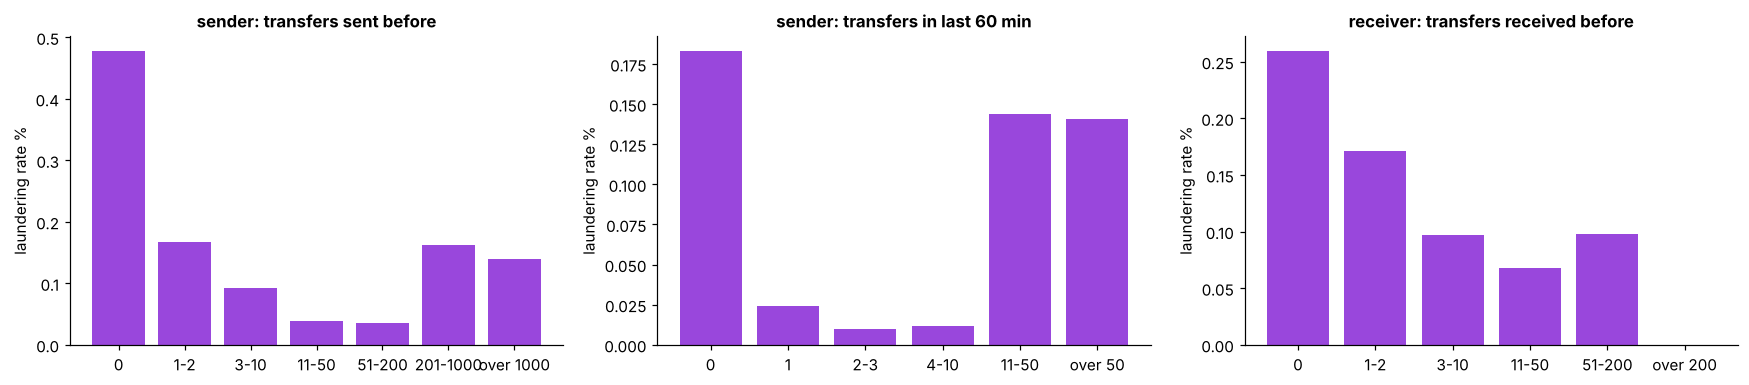

In [35]:
# Laundering rate by bucket of each point-in-time feature
def bucket_rate(col, edges):
    case = " ".join(f"WHEN {col} <= {hi} THEN '{lab}'" for lab, hi in edges)
    d = sql(f'''SELECT CASE {case} ELSE 'over {edges[-1][1]}' END AS bucket, MIN({col}) AS lo,
                       COUNT(*) AS rows, 100 * AVG(y) AS rate_pct FROM pit GROUP BY 1 ORDER BY lo''')
    return d

fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
specs = [("snd_sent_before", "sender: transfers sent before",
          [("0", 0), ("1-2", 2), ("3-10", 10), ("11-50", 50), ("51-200", 200), ("201-1000", 1000)]),
         ("snd_sent_last_60m", "sender: transfers in last 60 min",
          [("0", 0), ("1", 1), ("2-3", 3), ("4-10", 10), ("11-50", 50)]),
         ("rcv_recv_before", "receiver: transfers received before",
          [("0", 0), ("1-2", 2), ("3-10", 10), ("11-50", 50), ("51-200", 200)])]
for a, (col, title, edges) in zip(ax, specs):
    d = bucket_rate(col, edges)
    a.bar(d["bucket"], d["rate_pct"], color=PURPLE); a.set_title(title); a.set_ylabel("laundering rate %")
    print(title); display(fmt_int(d.drop(columns="lo"), ["rows"]).round(4).T)
plt.tight_layout(); plt.show()

**What the output shows.** This is the key lesson of this section — **the account view and the
transfer view disagree**.
- **Account view (section 11):** laundering-involved accounts are *busier* over the window (degree
  22 vs 6, received 13 vs 2).
- **Transfer view (here, point-in-time):** a laundering transfer comes from a sender that had sent
  **fewer** transfers before (median **3** vs **18**) and goes to a receiver that had received fewer
  before (**6** vs **11**). The sender's received-count is almost the same (**6** vs **7**).
- **Brand-new accounts** (no activity at all before this transfer) are more common in laundering:
  sender **11.63%** vs **4.88%**, receiver **9.42%** vs **4.73%**.
- **Rate by bucket:** a sender's very first transfer has a laundering rate of **0.4776%**, falling to
  **0.0393%** at 11–50 earlier transfers — then rising again to **0.14–0.16%** above 200 earlier
  transfers (the hub accounts). Senders with **no** transfer in the last hour are riskier
  (**0.183%**) than those with 1–10 (**0.01–0.02%**).

**Why they disagree (in plain words).** Normal rows mostly come from **very busy** accounts — one
busy account produces thousands of normal rows. So "a typical normal row" comes from a busy sender,
even though "a typical normal account" is quiet. Laundering accounts are moderately busy over the
window, but each laundering transfer tends to be **early** in their activity, or from a quiet
account.

**What it means for us.**
- Do not copy section 11's account-level numbers into the report as "feature strength". Features
  must be point-in-time, and their real strength is what this section (and 16c) measures.
- The useful point-in-time account features are: **sender's earlier sent-count** (low = riskier),
  **brand-new sender / receiver** flags, and the **hub** flag (to catch the U-shape at the top).

<a id="b13"></a>
## <span style="color:#9947dc">13. Pass-through — corrected</span>

**Why.** The investigator's key question: *did the money stop here, or did it just pass through?*
An account that receives money and sends about the same amount on within minutes behaves like a
pipe (a "mule"). The previous EDA called this our **strongest signal** (40.9% of laundering vs
12.8% of normal transfers). Here we test whether that is really true.

**How.** For every outgoing transfer, find the same account's most recent **incoming** transfer in
the previous 24 hours. If the amount sent is within 10% of the amount received, call it a
pass-through. The time between them is the **dwell time**. We compute it three ways:
1. **Old way** — exactly as the previous EDA, self-transfers included.
2. **Corrected** — self-transfers excluded on both sides (money must come from *someone else* and
   go to *someone else*).
3. **What was really behind the old number** — the incoming "transfer" is the account's own
   self-transfer (a currency conversion).

In [36]:
con.execute("""
    CREATE OR REPLACE TABLE tx AS
    SELECT row_number() OVER () AS rid, Timestamp AS t, acct_from, acct_to,
           "Amount Paid" AS paid, "Amount Received" AS recv, "Is Laundering" AS y,
           "Attempt ID" IS NOT NULL AS explained, self_transfer,
           "Payment Currency" <> "Receiving Currency" AS changes_currency
    FROM j
""")


def passthrough(out_filter, in_filter, label):
    # Step 1: for each outgoing transfer, find the MINUTE of the account's latest incoming transfer.
    # Step 2: look at ALL incoming transfers in that minute (several can arrive in the same minute),
    #         so the answer does not depend on which one the database happens to pick first.
    return sql(f"""
        WITH o AS (SELECT rid, acct_from AS acct, t, paid, y, explained FROM tx WHERE {out_filter}),
             i AS (SELECT rid AS in_rid, acct_to AS acct, t AS t_in, recv FROM tx WHERE {in_filter}),
             i_min AS (SELECT DISTINCT acct, t_in FROM i),
             m AS (SELECT o.*, i_min.t_in FROM o ASOF LEFT JOIN i_min ON o.acct = i_min.acct AND o.t >= i_min.t_in),
             per_out AS (
                 SELECT m.rid, ANY_VALUE(m.y) AS y, ANY_VALUE(m.explained) AS explained,
                        ANY_VALUE(m.t) AS t, ANY_VALUE(m.t_in) AS t_in,
                        BOOL_OR(abs(m.paid / NULLIF(i.recv, 0) - 1) <= 0.10) AS amount_match,
                        BOOL_OR(i.in_rid = m.rid) AS matched_itself
                 FROM m LEFT JOIN i ON m.acct = i.acct AND m.t_in = i.t_in
                 GROUP BY m.rid)
        SELECT '{label}' AS version,
               CASE WHEN y = 0 THEN 'Normal' WHEN explained THEN 'Laundering (explained)' ELSE 'Laundering (unexplained)' END AS kind,
               COUNT(*) AS outgoing,
               100 * AVG(CASE WHEN t - t_in <= INTERVAL 24 HOUR AND amount_match THEN 1.0 ELSE 0 END) AS passthrough_pct,
               MEDIAN(CASE WHEN t - t_in <= INTERVAL 24 HOUR THEN (epoch(t) - epoch(t_in)) / 3600 END) AS median_dwell_hours,
               100 * AVG(CASE WHEN matched_itself THEN 1.0 ELSE 0 END) AS matched_itself_pct
        FROM per_out GROUP BY 1, 2
    """)


pt = pd.concat([
    passthrough("TRUE", "TRUE", "1. Old way (self-transfers included)"),
    passthrough("self_transfer = 0", "self_transfer = 0", "2. Corrected (self-transfers excluded)"),
    passthrough("self_transfer = 0", "self_transfer = 1", "3. Incoming = own self-transfer"),
]).sort_values(["version", "kind"]).reset_index(drop=True)
display(fmt_int(pt, ["outgoing"]).round(2))

conv = sql("""
    WITH lau AS (SELECT acct_from AS acct, t, paid FROM tx WHERE explained AND self_transfer = 0),
         selfs AS (SELECT rid, acct_from AS acct, t, recv, y, changes_currency FROM tx WHERE self_transfer = 1),
         hit AS (SELECT DISTINCT selfs.rid, selfs.y, selfs.changes_currency FROM selfs JOIN lau
                 ON selfs.acct = lau.acct AND selfs.t = lau.t AND abs(lau.paid / NULLIF(selfs.recv, 0) - 1) <= 0.10)
    SELECT COUNT(*) AS conversion_rows_same_minute_before_a_scheme_transfer,
           SUM(y) AS of_which_labelled_laundering,
           SUM(CAST(changes_currency AS INT)) AS of_which_change_currency
    FROM hit
""")
print("The self-transfers that sit right before scheme transfers:")
display(conv)

old = pt[pt["version"].str.startswith("1")].set_index("kind")
print(f"Old way, all laundering together: "
      f"{(old.loc[['Laundering (explained)', 'Laundering (unexplained)'], 'passthrough_pct'] * old.loc[['Laundering (explained)', 'Laundering (unexplained)'], 'outgoing']).sum() / old.loc[['Laundering (explained)', 'Laundering (unexplained)'], 'outgoing'].sum():.2f}% "
      f"vs normal {old.loc['Normal', 'passthrough_pct']:.2f}%")

,version,kind,outgoing,passthrough_pct,median_dwell_hours,matched_itself_pct
0,1. Old way (self-transfers included),Laundering (explained),"3,209",65.63,0.00,0.34
1,1. Old way (self-transfers included),Laundering (unexplained),"1,968",0.81,5.83,0.00
2,1. Old way (self-transfers included),Normal,"5,073,159",12.90,5.08,11.65
3,2. Corrected (self-transfers excluded),Laundering (explained),"3,198",4.75,8.27,0.00
4,2. Corrected (self-transfers excluded),Laundering (unexplained),"1,968",0.81,5.51,0.00
5,2. Corrected (self-transfers excluded),Normal,"4,481,958",1.33,7.73,0.00
6,3. Incoming = own self-transfer,Laundering (explained),"3,198",61.79,0.00,0.00
7,3. Incoming = own self-transfer,Laundering (unexplained),"1,968",0.05,12.72,0.00
8,3. Incoming = own self-transfer,Normal,"4,481,958",1.68,9.28,0.00


The self-transfers that sit right before scheme transfers:


,conversion_rows_same_minute_before_a_scheme_transfer,of_which_labelled_laundering,of_which_change_currency
0,1965,0.0,1965.0


Old way, all laundering together: 40.99% vs normal 12.90%


**What the output shows.** This is the most important correction in this notebook.

1. **The old way** reproduces the previous EDA: **40.99%** of laundering vs **12.90%** of normal
   transfers look like pass-through. But look at `matched_itself_pct`: for normal rows, **11.65%**
   of outgoing transfers were matched to **themselves**. A self-transfer is both "incoming" and
   "outgoing" for the same account, at the same minute, with the same amount — so it always looks
   like perfect pass-through. **Almost all of the 12.90% normal pass-through is that glitch.**
2. **Corrected** (money must come from someone else and go to someone else): laundering
   (explained) **4.75%** vs normal **1.33%**, unexplained laundering **0.81%**. And the **dwell
   time** is the same for both: **8.27** vs **7.73** hours. The famous "0 hours" disappears.
3. **What was really behind the old number:** for **61.79%** of explained laundering transfers,
   the most recent "incoming" money was the account's **own self-transfer** of the same amount, in
   the **same minute** (dwell **0.00** hours). Normal rows: **1.68%**. Unexplained laundering:
   **0.05%**.
4. There are **1,965** such self-transfers right before a scheme transfer. **All 1,965 change
   currency**, and **none (0)** is labelled laundering.

**In plain words:** the generator writes many scheme steps as *"convert the money into another
currency (pay yourself), then immediately send it on"*. The old pass-through measure was really
detecting this **currency conversion step**, plus the self-transfer glitch on normal rows.

**What it means for us.**
- **Real pass-through (money from A, through B, to C) is a weak signal here** (4.75% vs 1.33%, and
  no dwell difference). The previous EDA's "strongest signal, most likely to survive on real data"
  claim must be withdrawn.
- **"Sent right after a same-amount currency conversion"** is a very strong feature (about 37x),
  but it only exists for explained schemes and is a mechanic of this generator. Use it, and say
  plainly in the report that it is generator-made.
- The 1,965 conversion rows are part of schemes but labelled normal. The **agent** should include
  the conversion step when it rebuilds a case; the **model** should keep them as normal (we do not
  change labels).

Account 21174:800737690 around 2022-09-01 00:06:00 (scheme 0):


,Timestamp,acct_from,acct_to,Amount Paid,Payment Currency,Amount Received,Receiving Currency,Payment Format,self_transfer,Is Laundering,Attempt ID
0,2022-09-01 00:06:00,21174:800737690,21174:800737690,3338.36,US Dollar,2848.96,Euro,ACH,1,0,<NA>
1,2022-09-01 00:06:00,21174:800737690,12:80011F990,2848.96,Euro,2848.96,Euro,ACH,0,1,0


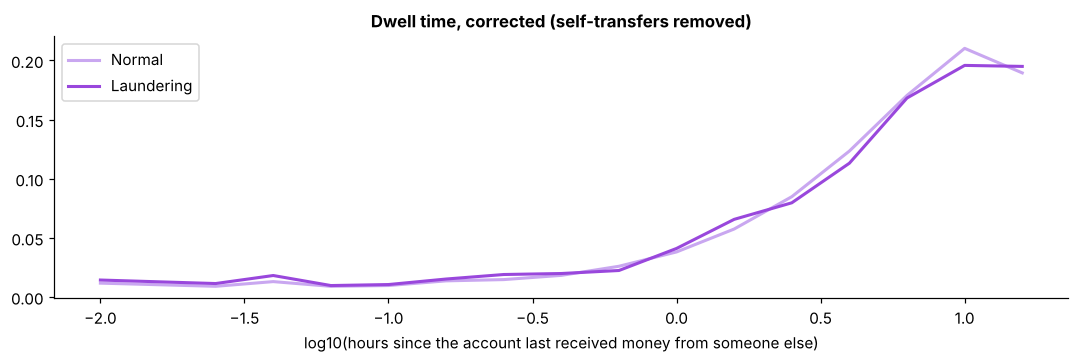

In [37]:
# One real example: a scheme transfer and the conversion self-transfer in the same minute before it.
ex = sql('''
    WITH lau AS (SELECT * FROM j WHERE "Attempt ID" IS NOT NULL AND self_transfer = 0),
         sf AS (SELECT * FROM j WHERE self_transfer = 1)
    SELECT lau."Attempt ID" AS att, lau.acct_from, lau.Timestamp
    FROM lau JOIN sf ON lau.acct_from = sf.acct_from AND lau.Timestamp = sf.Timestamp
         AND abs(lau."Amount Paid" / NULLIF(sf."Amount Received", 0) - 1) <= 0.10
    ORDER BY lau."Attempt ID", lau.Timestamp LIMIT 1
''')
a, ts = ex.loc[0, "acct_from"], ex.loc[0, "Timestamp"]
print(f"Account {a} around {ts} (scheme {int(ex.loc[0, 'att'])}):")
display(sql(f'''
    SELECT Timestamp, acct_from, acct_to, "Amount Paid", "Payment Currency", "Amount Received", "Receiving Currency",
           "Payment Format", self_transfer, "Is Laundering", "Attempt ID"
    FROM j WHERE (acct_from = '{a}' OR acct_to = '{a}')
      AND Timestamp BETWEEN TIMESTAMP '{ts}' - INTERVAL 1 HOUR AND TIMESTAMP '{ts}' + INTERVAL 1 HOUR
    ORDER BY Timestamp, self_transfer DESC
'''))

dw = sql('''
    WITH o AS (SELECT rid, acct_from AS acct, t, y FROM tx WHERE self_transfer = 0),
         i AS (SELECT DISTINCT acct_to AS acct, t AS t_in FROM tx WHERE self_transfer = 0),
         m AS (SELECT * FROM o ASOF LEFT JOIN i ON o.acct = i.acct AND o.t >= i.t_in)
    SELECT y, floor(log10((epoch(t) - epoch(t_in)) / 3600 + 0.01) * 5) / 5 AS bin, COUNT(*) AS n
    FROM m WHERE t_in IS NOT NULL AND t - t_in <= INTERVAL 24 HOUR GROUP BY 1, 2 ORDER BY 2
''')
fig, ax = plt.subplots(figsize=(10, 3.4))
for y, colour, name in [(0, LILAC, "Normal"), (1, PURPLE, "Laundering")]:
    d = dw[dw["y"] == y]
    ax.plot(d["bin"], d["n"] / d["n"].sum(), color=colour, lw=2, label=name)
ax.set_xlabel("log10(hours since the account last received money from someone else)")
ax.set_title("Dwell time, corrected (self-transfers removed)"); ax.legend()
plt.tight_layout(); plt.show()

**What the output shows.**
- **A real example** (scheme 0, 1 Sept at 00:06): account `21174:800737690` first pays **itself**
  3,338.36 US Dollars and receives **2,848.96 Euro** (the conversion, labelled **0**), and in the
  **same minute** sends **2,848.96 Euro** to `12:80011F990` (labelled **1**, scheme 0). That pair of
  rows is exactly the pattern behind the old "pass-through at 0 hours".
- **Corrected dwell chart:** once self-transfers are removed, the "hours since the account last
  received money from someone else" curves for normal and laundering transfers lie almost on top
  of each other.

**What it means for us.** Confirms section 13: real pass-through timing does not separate the
classes in this data; the conversion step does.

<a id="b14"></a>
## <span style="color:#9947dc">14. Structuring: round and repeated amounts</span>

**Why.** "Structuring" means splitting a big sum into many smaller transfers, often round numbers
or the same amount again and again. It is a famous laundering technique, so we test whether the
data simulates it. **A "no" here is a useful result**: it tells us not to waste time building
these features.

**How.** Share of amounts that are multiples of 10 / 100 / 1,000 or whole numbers, per class. Then
(sender, exact amount) pairs that repeat 3 or more times, and how many of them involve laundering.

In [38]:
rnd = sql("""
    SELECT 'Multiple of 10' AS test, 100*AVG(CASE WHEN y=0 THEN r10 END) AS normal_pct, 100*AVG(CASE WHEN y=1 THEN r10 END) AS laundering_pct FROM
      (SELECT "Is Laundering" y, CAST("Amount Paid" % 10 = 0 AS INT) r10 FROM j)
    UNION ALL SELECT 'Multiple of 100', 100*AVG(CASE WHEN y=0 THEN r END), 100*AVG(CASE WHEN y=1 THEN r END) FROM
      (SELECT "Is Laundering" y, CAST("Amount Paid" % 100 = 0 AS INT) r FROM j)
    UNION ALL SELECT 'Multiple of 1000', 100*AVG(CASE WHEN y=0 THEN r END), 100*AVG(CASE WHEN y=1 THEN r END) FROM
      (SELECT "Is Laundering" y, CAST("Amount Paid" % 1000 = 0 AS INT) r FROM j)
    UNION ALL SELECT 'Whole number', 100*AVG(CASE WHEN y=0 THEN r END), 100*AVG(CASE WHEN y=1 THEN r END) FROM
      (SELECT "Is Laundering" y, CAST("Amount Paid" % 1 = 0 AS INT) r FROM j)
""")
display(rnd.round(3))

rep = sql("""
    SELECT COUNT(*) AS pairs_repeated_3plus,
           SUM(CASE WHEN lau > 0 THEN 1 ELSE 0 END) AS pairs_with_laundering
    FROM (SELECT acct_from, "Amount Paid", COUNT(*) AS n, SUM("Is Laundering") AS lau FROM j GROUP BY 1, 2)
    WHERE n >= 3
""")
rep["with_laundering_pct"] = 100 * rep["pairs_with_laundering"] / rep["pairs_repeated_3plus"]
display(fmt_int(rep, ["pairs_repeated_3plus", "pairs_with_laundering"]).round(3))

,test,normal_pct,laundering_pct
0,Multiple of 10,0.122,0.116
1,Multiple of 100,0.012,0.019
2,Multiple of 1000,0.001,0.000
3,Whole number,1.207,1.159


,pairs_repeated_3plus,pairs_with_laundering,with_laundering_pct
0,"455,387",566,0.124


**What the output shows.**
- Round amounts are just as rare in laundering as in normal transfers: multiple of 10 —
  **0.116%** vs **0.122%**; whole numbers — **1.159%** vs **1.207%**. Multiples of 100 and 1,000
  are below 0.02% for both.
- **455,387** (sender, exact amount) pairs repeat 3 or more times, and only **566** of them
  (**0.124%**) involve any laundering.

**What it means for us.** The generator does **not** simulate structuring. This is a useful
negative result for the report: we tested a well-known typology and the data does not contain it.
**Do not build round-amount or repeated-amount features.**

<a id="b15"></a>
## <span style="color:#9947dc">15. How long accounts stay active</span>

**Why.** Mule accounts are often short-lived: they appear, move money, and go quiet. We test whether
laundering-involved accounts have a shorter active period.

**How.** For each account, time from its first to its last transfer (sent or received), within
1–10 September so the leftover tail does not stretch anything.

In [39]:
life = sql("""
    SELECT involved,
           COUNT(*) AS accounts,
           MEDIAN(span_days) AS median_span_days,
           quantile_cont(span_days, 0.25) AS p25_span_days,
           quantile_cont(span_days, 0.75) AS p75_span_days
    FROM (SELECT acct, (epoch(MAX(t)) - epoch(MIN(t))) / 86400 AS span_days FROM
            (SELECT acct_from AS acct, Timestamp AS t FROM j WHERE Timestamp < TIMESTAMP '2022-09-11'
             UNION ALL SELECT acct_to, Timestamp FROM j WHERE Timestamp < TIMESTAMP '2022-09-11')
          GROUP BY 1) x
    JOIN acc USING (acct)
    GROUP BY 1 ORDER BY 1
""")
display(fmt_int(life, ["accounts"]).round(2))

,involved,accounts,median_span_days,p25_span_days,p75_span_days
0,False,"508,731",8.05,1.26,8.99
1,True,"6,347",8.79,7.95,9.41


**What the output shows.** Over 1–10 September, the median active span is **8.05** days for normal
accounts and **8.79** days for laundering-involved ones. The lower quarter is very different
(**1.26** vs **7.95** days): many normal accounts appear only briefly, while laundering accounts
are active for almost the whole window.

**What it means for us.** No "short-lived mule account" pattern here — if anything the opposite.
Report as a negative result. Do not build a lifetime feature (it would also need the future to
compute: you only know when an account goes quiet after it has).

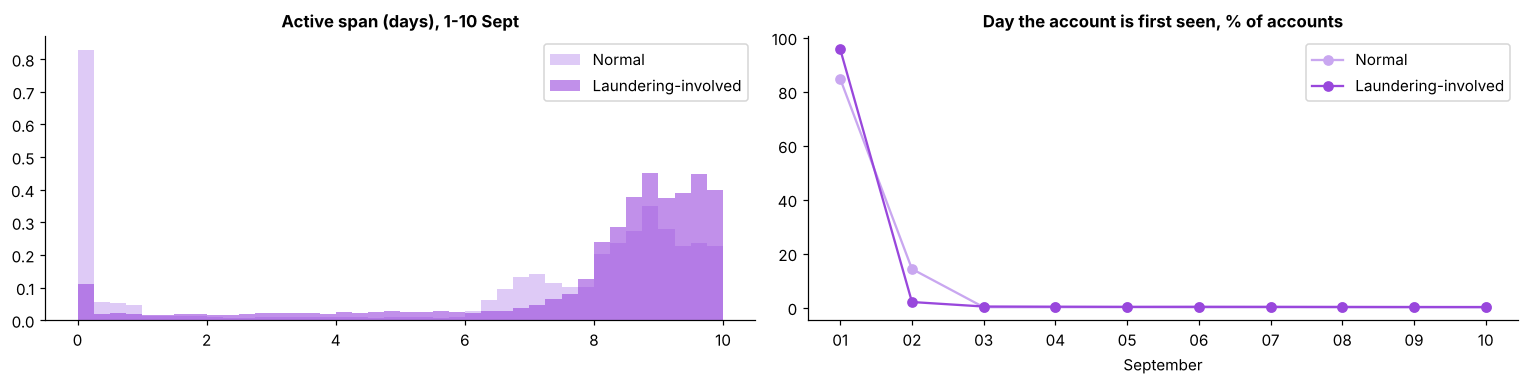

% of accounts first seen on 1 Sept: {False: 84.7, True: 95.7}


In [40]:
lf2 = sql('''
    SELECT a.involved, CAST(date_trunc('day', MIN(t)) AS DATE) AS first_day,
           (epoch(MAX(t)) - epoch(MIN(t))) / 86400 AS span_days
    FROM (SELECT acct_from AS acct, Timestamp AS t FROM j WHERE Timestamp < TIMESTAMP '2022-09-11'
          UNION ALL SELECT acct_to, Timestamp FROM j WHERE Timestamp < TIMESTAMP '2022-09-11') x
    JOIN acc a USING (acct) GROUP BY x.acct, a.involved
''')
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
for flag, colour, name in [(False, LILAC, "Normal"), (True, PURPLE, "Laundering-involved")]:
    v = lf2.loc[lf2["involved"] == flag, "span_days"]
    ax[0].hist(v, bins=40, density=True, alpha=0.6, color=colour, label=name)
    fd = lf2.loc[lf2["involved"] == flag, "first_day"].value_counts(normalize=True).sort_index()
    ax[1].plot(pd.to_datetime(fd.index).strftime("%d"), 100 * fd.values, marker="o", color=colour, label=name)
ax[0].set_title("Active span (days), 1-10 Sept"); ax[0].legend()
ax[1].set_title("Day the account is first seen, % of accounts"); ax[1].set_xlabel("September"); ax[1].legend()
plt.tight_layout(); plt.show()
first = lf2.groupby("involved")["first_day"].apply(lambda s: 100 * (pd.to_datetime(s) == pd.Timestamp("2022-09-01")).mean())
print("% of accounts first seen on 1 Sept:", first.round(1).to_dict())

**What the output shows.** The span chart shows normal accounts spread over all spans with a big
group at very short spans, while laundering-involved accounts are packed near the full 8–9 days.
And **95.7%** of laundering-involved accounts are already active on the first day (1 Sept), vs
**84.7%** of normal accounts.

**What it means for us.** Laundering accounts in this data are long-running, established accounts —
not fresh mules. That fits the "brand-new" result in 12b only partly: the laundering *transfer* is
often early in an account's activity, but the *account* itself stays active for the whole window.

<a id="b16"></a>
## <span style="color:#9947dc">16. Pictures of real schemes</span>

**Why.** "CYCLE: 54 schemes" means nothing until you see one. These pictures also show what the
agent's output should look like: a small map of who paid whom.

**How.** For each pattern type, pick the scheme closest to 8 transfers and draw it. Each circle is
an account (last 4 characters of its number), each arrow a transfer.

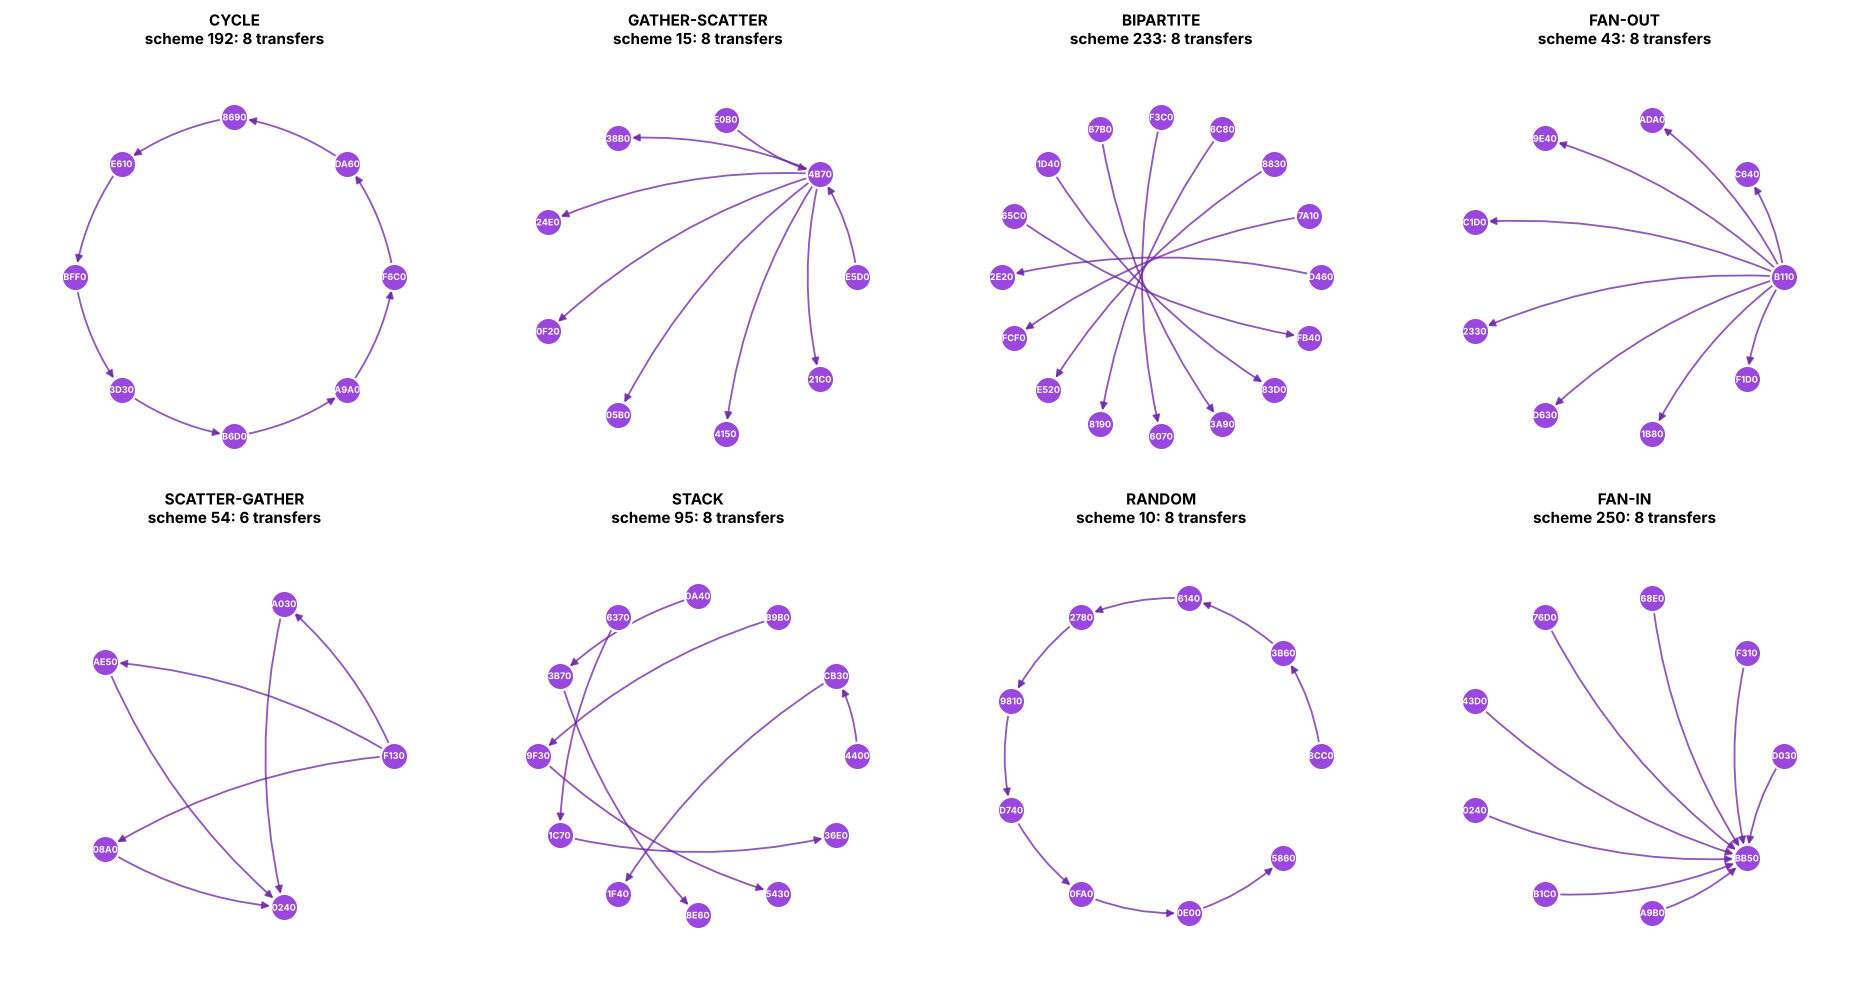

The transfer list behind scheme 15:


,Timestamp,Account,Account.1,Amount Paid,Payment Format
0,2022-09-01 06:46:00,23:8001FE5D0,12:800054B70,18748.97,ACH
1,2022-09-03 07:04:00,12:800054B70,410:8002438B0,12156.43,ACH
2,2022-09-03 08:47:00,20:80012E0B0,12:800054B70,8369.42,ACH
3,2022-09-03 21:58:00,12:800054B70,12:8002924E0,3042618.84,ACH
4,2022-09-04 11:04:00,12:800054B70,11:800240F20,219.13,ACH
5,2022-09-05 09:55:00,12:800054B70,11:8001205B0,4878.69,ACH
6,2022-09-05 10:43:00,12:800054B70,28:8000B4150,262128.59,ACH
7,2022-09-05 20:13:00,12:800054B70,11:8001021C0,11139.43,ACH


In [41]:
types = by_type.index.tolist()
fig, axes = plt.subplots(2, 4, figsize=(17, 9))
example_rows = {}
for ax, ptype in zip(axes.ravel(), types):
    cand = prof[prof["pattern"] == ptype].assign(d=lambda x: (x["transfers"] - 8).abs()).sort_values(["d", "Attempt ID"])
    att = int(cand.iloc[0]["Attempt ID"])
    rows = sql(f"""SELECT Timestamp, acct_from AS "Account", acct_to AS "Account.1", "Amount Paid", "Payment Format"
                   FROM j WHERE "Attempt ID" = {att} ORDER BY Timestamp""")
    example_rows[ptype] = (att, rows)
    eu.draw_attempt(rows, f"{ptype}\nscheme {att}: {len(rows)} transfers", ax)
plt.tight_layout(); plt.show()

att, rows = example_rows["GATHER-SCATTER"] if "GATHER-SCATTER" in example_rows else example_rows[types[0]]
print(f"The transfer list behind scheme {att}:")
display(rows)

**What the output shows.** One example of each of the 8 pattern types. Below the drawings is the
transfer list for GATHER-SCATTER scheme 15: between 1 and 5 Sept, account `12:800054B70`
**receives** from two accounts and **sends** to six different accounts — it is the hub of the
scheme: money is gathered in and scattered out. All 8 transfers are ACH, and one of them is 3,042,618.84.

**What it means for us.** This is the kind of picture and table the agent should produce for an
investigator: which accounts, in what order, how much. It also shows why account features matter:
the middle account's behaviour (many in, many out, short time) is visible only at account level,
not from any single row.

<a id="b16b"></a>
## <span style="color:#9947dc">16b. Can we split by time?</span>

**Why.** A fair test uses data the model has never seen, from a **later** period. But schemes last
days and share accounts, so any cut date slices some schemes in two and leaves some accounts on
both sides. This section measures that cost for several candidate cut dates (within 1–10 Sept).

**How.** For each cut date: rows and laundering rows before and after, schemes that start before
and end after (straddling), and how many laundering accounts appear on both sides.

In [42]:
cut_rows = []
for cut in ["2022-09-05", "2022-09-06", "2022-09-07", "2022-09-08", "2022-09-09"]:
    r = sql(f'''
        WITH f AS (SELECT * FROM j WHERE Timestamp < TIMESTAMP '2022-09-11'),
             sch AS (SELECT "Attempt ID", MIN(Timestamp) AS s, MAX(Timestamp) AS e FROM f WHERE "Attempt ID" IS NOT NULL GROUP BY 1),
             la AS (SELECT acct_from AS a, Timestamp AS t FROM f WHERE "Is Laundering" = 1
                    UNION ALL SELECT acct_to, Timestamp FROM f WHERE "Is Laundering" = 1)
        SELECT TIMESTAMP '{cut}' AS cut,
               (SELECT COUNT(*) FROM f WHERE Timestamp < TIMESTAMP '{cut}') AS rows_before,
               (SELECT SUM("Is Laundering") FROM f WHERE Timestamp < TIMESTAMP '{cut}') AS laundering_before,
               (SELECT SUM("Is Laundering") FROM f WHERE Timestamp >= TIMESTAMP '{cut}') AS laundering_after,
               (SELECT COUNT(*) FROM sch WHERE s < TIMESTAMP '{cut}' AND e >= TIMESTAMP '{cut}') AS schemes_straddling,
               (SELECT COUNT(*) FROM sch) AS schemes_total,
               (SELECT COUNT(*) FROM (SELECT a FROM la GROUP BY a
                   HAVING MIN(t) < TIMESTAMP '{cut}' AND MAX(t) >= TIMESTAMP '{cut}')) AS laundering_accounts_both_sides,
               (SELECT COUNT(DISTINCT a) FROM la) AS laundering_accounts_total
    ''')
    cut_rows.append(r)
cuts = pd.concat(cut_rows, ignore_index=True)
cuts["straddling_pct"] = 100 * cuts["schemes_straddling"] / cuts["schemes_total"]
cuts["accounts_both_sides_pct"] = 100 * cuts["laundering_accounts_both_sides"] / cuts["laundering_accounts_total"]
cuts["cut"] = pd.to_datetime(cuts["cut"]).dt.strftime("%d Sept")
display(fmt_int(cuts, ["rows_before", "laundering_before", "laundering_after"]).round(1))

,cut,rows_before,laundering_before,laundering_after,schemes_straddling,schemes_total,laundering_accounts_both_sides,laundering_accounts_total,straddling_pct,accounts_both_sides_pct
0,05 Sept,"2,284,180","1,528","2,994",86,363,268,5862,23.7,4.6
1,06 Sept,"2,766,830","1,999","2,523",92,363,294,5862,25.3,5.0
2,07 Sept,"3,248,919","2,530","1,992",96,363,302,5862,26.4,5.2
3,08 Sept,"3,731,669","3,027","1,495",102,363,336,5862,28.1,5.7
4,09 Sept,"4,214,440","3,566",956,95,363,249,5862,26.2,4.2


**What the output shows.** For cut dates from 5 to 9 Sept:
- Between **86** and **102** of the 363 schemes (**23.7%–28.1%**) start before the cut and end after
  it. The 8 Sept cut (our test start) straddles the most: **102** schemes.
- Only **4.2%–5.7%** of laundering accounts launder on **both** sides of the cut (e.g. **336** of
  **5,862** at 8 Sept). Most laundering accounts are active in laundering on one side only.
- Laundering after the cut drops from **2,994** (cut 5 Sept) to **956** (cut 9 Sept).

**What it means for us.** Any date cut slices about a quarter of the schemes, which is why the time
split moves a crossing scheme **whole** into the later split. Account overlap in laundering is
small, so the time split is not dominated by "the same launderers in train and test". The 8 Sept
test start keeps a healthy **1,495** laundering rows after it while leaving 3,027 before.

<a id="b16c"></a>
## <span style="color:#9947dc">16c. Which single features separate the classes best?</span>

**Why.** Many sections above each looked at one signal. Here we put them side by side on the **same
scale**, so preprocessing and modelling know where to start, and we check which candidate features
carry the same information (strongly correlated features are partly redundant).

**How.** On the point-in-time table (`pit`: every real transfer in 1–10 Sept), score each feature
**on its own** with **average precision** (AP, the area under the precision–recall curve). AP for a
useless feature equals the laundering rate (about 0.001 here). An AP of 0.01 means the feature alone
ranks laundering about 10x better than random. For features where **lower** values mean more risk,
we flip the sign so every feature is scored in its best direction. Then a correlation map of the
features and the label.

*Note:* this ranks features one at a time; a model combines them, so the combination will do much
better than any single line here.

In [43]:
from sklearn.metrics import average_precision_score

FEATS = ["is_ach", "conversion_before", "new_pair", "cross_bank", "cross_border", "same_entity", "usd",
         "snd_sent_before", "snd_recv_before", "rcv_sent_before", "rcv_recv_before",
         "snd_sent_last_60m", "rcv_recv_last_24h", "pair_prev"]
pf = con.execute(f"SELECT y, {', '.join(FEATS)} FROM pit").df()
for c in FEATS:
    pf[c] = pf[c].astype("float32")
base_rate = pf["y"].mean()
rank = []
for c in FEATS:
    up, down = average_precision_score(pf["y"], pf[c]), average_precision_score(pf["y"], -pf[c])
    rank.append((c, max(up, down), "higher = riskier" if up >= down else "lower = riskier"))
rank = pd.DataFrame(rank, columns=["feature", "average_precision", "direction"]).sort_values("average_precision", ascending=False)
rank["x_better_than_random"] = rank["average_precision"] / base_rate
print(f"Laundering rate in pit (= AP of a useless feature): {base_rate:.5f}")
display(rank.round(5).reset_index(drop=True))

Laundering rate in pit (= AP of a useless feature): 0.00101


,feature,average_precision,direction,x_better_than_random
0,conversion_before,0.00868,higher = riskier,8.62713
1,is_ach,0.00627,higher = riskier,6.23044
2,pair_prev,0.00463,lower = riskier,4.60416
3,new_pair,0.00430,higher = riskier,4.27787
4,snd_sent_before,0.00288,lower = riskier,2.86238
5,usd,0.00187,higher = riskier,1.86007
6,rcv_recv_before,0.00171,lower = riskier,1.69510
7,snd_sent_last_60m,0.00165,lower = riskier,1.63942
8,cross_border,0.00151,higher = riskier,1.50441
9,rcv_recv_last_24h,0.00127,lower = riskier,1.26629


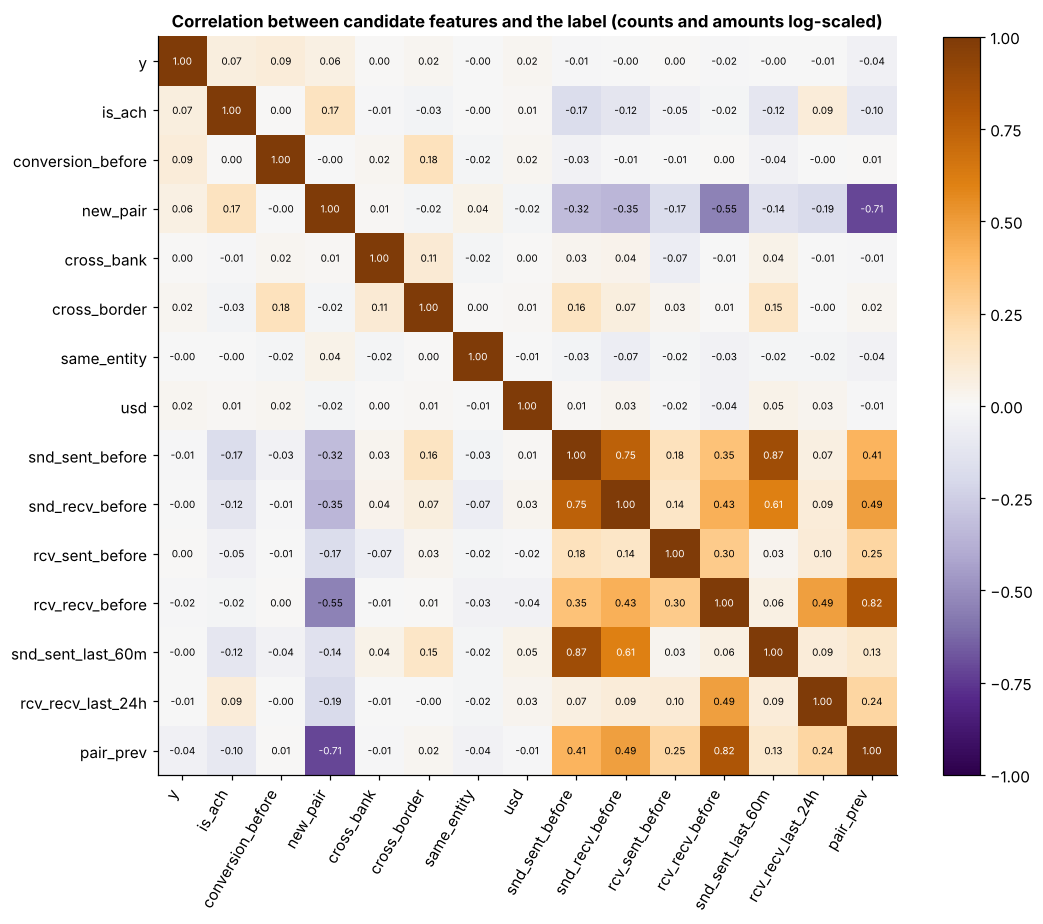

Feature pairs with |correlation| >= 0.5:


,feature_a,feature_b,correlation
0,new_pair,rcv_recv_before,-0.545
1,new_pair,pair_prev,-0.711
2,snd_sent_before,snd_recv_before,0.754
3,snd_sent_before,snd_sent_last_60m,0.872
4,snd_recv_before,snd_sent_last_60m,0.609
5,rcv_recv_before,pair_prev,0.820


In [44]:
cm = pf.assign(**{c: np.log1p(pf[c]) for c in ["usd", "snd_sent_before", "snd_recv_before", "rcv_sent_before",
                                                "rcv_recv_before", "snd_sent_last_60m", "rcv_recv_last_24h", "pair_prev"]}).corr()
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(cm.values, cmap="PuOr_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cm)), cm.columns, rotation=60, ha="right"); ax.set_yticks(range(len(cm)), cm.columns)
for i in range(len(cm)):
    for k in range(len(cm)):
        ax.text(k, i, f"{cm.values[i, k]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(cm.values[i, k]) > 0.6 else "black")
ax.set_title("Correlation between candidate features and the label (counts and amounts log-scaled)")
plt.colorbar(im, fraction=0.04); plt.tight_layout(); plt.show()
strong = [(a, b, cm.loc[a, b]) for i, a in enumerate(cm.columns) for b in cm.columns[i + 1:] if abs(cm.loc[a, b]) >= 0.5]
print("Feature pairs with |correlation| >= 0.5:")
display(pd.DataFrame(strong, columns=["feature_a", "feature_b", "correlation"]).round(3))
del pf

**What the output shows.** Laundering is **0.00101** of rows here, so that is the AP of a useless
feature. Best single features (AP, and how many times better than random):
1. **conversion_before** — **0.00868 (8.6x)**: sent right after a same-amount currency conversion.
2. **is_ach** — **0.00627 (6.2x)**.
3. **pair_prev** — **0.00463 (4.6x)**, lower = riskier; **new_pair** — **0.00430 (4.3x)**.
4. **snd_sent_before** — **0.00288 (2.9x)**, lower = riskier.
5. **usd amount** — **0.00187 (1.9x)**; receiver's earlier received-count **1.7x**; sender's
   last-hour count **1.6x**; **cross_border 1.5x**.
6. **cross_bank** scores **1.0x** — no better than random on its own.

**Why does cross-bank score so low when it is "7.5x riskier"?** Because **86%** of all transfers are
cross-bank. Flagging every cross-bank transfer catches almost all laundering, but the flagged group
is so big that precision barely rises. A feature helps *find* laundering only if it points at a
**small** group with a high rate. Cross-bank is better at *clearing* same-bank transfers than at
finding bad ones. The same logic explains why new_pair (14% of rows) does well.

**Correlations.** No feature copies the label (all correlations with `y` are small — normal for a
0.1% target). A few features overlap: sender's earlier sent-count with its last-hour count
(**0.872**) and with its received-count (**0.754**); receiver's received-count with pair history
(**0.820**); new_pair with pair_prev (**−0.711**). Keep one of each strongly overlapping pair, or use
a model that copes with overlap (trees).

**What it means for us.** Start modelling with: conversion_before, new_pair / pair_prev, sender
history (sent-before, brand-new), amount in USD, cross-border, countries — and payment format as a
with/without experiment. Each alone is weak (under 10x random), which is normal; the model's job is
to combine them.

<a id="b17"></a>
## <span style="color:#9947dc">17. Summary of signals</span>

**Why.** One table that preprocessing can work from, instead of re-reading sixteen sections.

**How.** Each row is collected from the outputs above. "Baseline" is the normal class or the
comparison group, "Tested" is the laundering class or the group we suspect. Ratio above 1 = the
tested side is higher (for rates: how many times riskier); below 1 = lower.

In [45]:
def r(df, tested, baseline):
    return df.loc[df["value"] == baseline, "rate_pct"].iloc[0], df.loc[df["value"] == tested, "rate_pct"].iloc[0]

rows = []
rows.append(("Laundering rate %: different bank (tested) vs same bank (baseline)", *r(cb, "Different bank", "Same bank"), "Trust — but flags 86% of rows, so it mainly clears same-bank rows"))
rows.append(("Laundering rate %: cross-border (tested) vs same country (baseline)", *r(cbd, "Cross-border", "Same country"), "Trust"))
rows.append(("Median amount, mixed currencies: laundering (tested) vs normal (baseline)", amt.loc[0, "median"], amt.loc[1, "median"], "Superseded by the USD row below"))
nn = net[net["accounts"] == "Hubs removed"].set_index("involved")
for col in ["degree", "counterparties", "received"]:
    rows.append((f"Account {col} over the whole window, median, hubs removed: laundering-involved vs normal", nn.loc[False, col], nn.loc[True, col], "Account view only — much weaker per transfer (12b)"))
pc = pit_cmp.set_index("class")
rows.append(("Sender's transfers sent BEFORE this one (point-in-time), median: laundering vs normal",
             pc.loc["Normal", "sender_sent_before"], pc.loc["Laundering", "sender_sent_before"], "Useful (lower = riskier), 2.9x AP"))
npr = newp.set_index("pair")
rows.append(("Laundering rate %: first-time sender->receiver pair (tested) vs repeat pair (baseline)",
             npr.loc["repeat pair", "rate_pct"], npr.loc["new pair (first time)", "rate_pct"], "Trust — strong, realistic, point-in-time"))
rp = recip.set_index("pair")
rows.append(("Laundering rate %: two-way pair (tested) vs one-way pair (baseline)",
             rp.loc["one-way pair", "rate_pct"], rp.loc["two-way pair", "rate_pct"], "Strong — compute point-in-time (reverse pair seen before)"))
us = usd.set_index("laundering")
rows.append(("Median amount in USD: laundering (tested) vs normal (baseline)", us.loc[0, "median_usd"], us.loc[1, "median_usd"],
             "Trust — risk peaks at 9k-35k USD, not monotonic"))
c3 = pt[pt["version"].str.startswith("3")].set_index("kind")
rows.append(("% sent right after a same-amount currency-conversion self-transfer: explained laundering vs normal",
             c3.loc["Normal", "passthrough_pct"], c3.loc["Laundering (explained)", "passthrough_pct"], "Strong but generator-made — use, and say so"))
c2 = pt[pt["version"].str.startswith("2")].set_index("kind")
rows.append(("% real pass-through (corrected): explained laundering vs normal",
             c2.loc["Normal", "passthrough_pct"], c2.loc["Laundering (explained)", "passthrough_pct"], "Weak — covers few rows"))
other = fmt[fmt["value"] != "ACH"]
rows.append(("Laundering rate %: ACH (tested) vs all other formats (baseline)", 100 * other["laundering"].sum() / other["rows"].sum(),
             fmt.loc[fmt["value"] == "ACH", "rate_pct"].iloc[0], "Do not trust — generator artefact"))
rows.append(("Laundering rate %: same owner (tested) vs different owner (baseline)", *r(se, "Same owner", "Different owner"), "Mostly self-transfers — see next row"))
rows.append(("Same as above, self-transfers removed", *r(se2, "Same owner", "Different owner"), "Mild evidence of legitimacy"))
gv = gaps[gaps["version"] == "Self-transfers removed"].set_index("y")
rows.append(("Minutes since sender's previous transfer, median: laundering vs normal", gv.loc[0, "median_gap_min"], gv.loc[1, "median_gap_min"], "Not a speed signal — reflects how busy the account is"))
rows.append(("% amounts that are a multiple of 10: laundering vs normal", rnd.loc[0, "normal_pct"], rnd.loc[0, "laundering_pct"], "Ruled out"))
lf = life.set_index("involved")
rows.append(("Active span days, median: laundering-involved vs normal", lf.loc[False, "median_span_days"], lf.loc[True, "median_span_days"], "Ruled out"))

summary = pd.DataFrame(rows, columns=["Signal", "Baseline", "Tested", "Verdict"])
summary["Ratio (tested / baseline)"] = summary["Tested"] / summary["Baseline"]
with pd.option_context("display.max_colwidth", 120):
    display(summary[["Signal", "Baseline", "Tested", "Ratio (tested / baseline)", "Verdict"]].round(4))

,Signal,Baseline,Tested,Ratio (tested / baseline),Verdict
0,Laundering rate %: different bank (tested) vs same bank (baseline),0.0154,0.1157,7.5169,"Trust — but flags 86% of rows, so it mainly clears same-bank rows"
1,Laundering rate %: cross-border (tested) vs same country (baseline),0.0562,0.2192,3.9013,Trust
2,"Median amount, mixed currencies: laundering (tested) vs normal (baseline)",1410.9900,8667.2100,6.1426,Superseded by the USD row below
3,"Account degree over the whole window, median, hubs removed: laundering-involved vs normal",6.0000,22.0000,3.6667,Account view only — much weaker per transfer (12b)
4,"Account counterparties over the whole window, median, hubs removed: laundering-involved vs normal",2.0000,5.0000,2.5000,Account view only — much weaker per transfer (12b)
5,"Account received over the whole window, median, hubs removed: laundering-involved vs normal",2.0000,13.0000,6.5000,Account view only — much weaker per transfer (12b)
6,"Sender's transfers sent BEFORE this one (point-in-time), median: laundering vs normal",18.0000,3.0000,0.1667,"Useful (lower = riskier), 2.9x AP"
7,Laundering rate %: first-time sender->receiver pair (tested) vs repeat pair (baseline),0.0300,0.6193,20.6227,"Trust — strong, realistic, point-in-time"
8,Laundering rate %: two-way pair (tested) vs one-way pair (baseline),0.1052,5.0227,47.7334,Strong — compute point-in-time (reverse pair seen before)
9,Median amount in USD: laundering (tested) vs normal (baseline),891.0601,5878.8063,6.5975,"Trust — risk peaks at 9k-35k USD, not monotonic"


**What the output shows / what it means for us.**

| Verdict | Signals |
|---|---|
| **Strongest, realistic** | **first-time sender → receiver pair** (20.6x; 4.3–4.6x random as a single feature), **two-way pairs** (48x over the window; rebuild point-in-time), **amount in USD** (6.6x median; risk peaks at about 9k–35k USD), **cross-border** (3.9x, holds inside every payment format) |
| **Strong but generator-made** | "sent right after a same-amount currency conversion" (37x; best single feature at 8.6x random), payment format / ACH (48x — train with and without) |
| **Useful, point-in-time** | sender's earlier sent-count (lower = riskier), brand-new sender / receiver, hub flag, sender and receiver country |
| **Account view only** | whole-window degree / counterparties / received-count (great for describing accounts and for the agent, much weaker per transfer — 12b) |
| **Clears rather than finds** | different bank (7.5x, but 86% of rows), same owner (3.4x safer without self-transfers) |
| **Weak** | real pass-through (corrected), dwell time, owner type, accounts per owner |
| **Do not use** | hour of day, day of week, bank name as a category, account IDs |
| **Ruled out** | round amounts, repeated amounts, account lifetime, "minutes since last transfer" alone |

**Corrections to the previous EDA** (copied into `PROJECT_STATE.md`):
1. Leftover tail = **1,108** rows, not 1,575 (section 1).
2. Hubs = **15** with the sampling script's definition; the old 55 used a wider definition (11).
3. Pass-through was mostly self-transfers matching themselves plus the currency-conversion step;
   corrected pass-through is weak and dwell time does not separate the classes (13, 13b).
4. Same-owner "22x safer" was mostly self-transfers; the real figure is about **3.4x** (10).
5. Velocity: on all accounts the median gap is **longer** for laundering; the old "0 vs 8 minutes"
   came from the 20,000 busiest accounts only (12).
6. Hour 0 is the first-day start-up burst plus midnight Reinvestment bookings, not missing times (1).
7. Account-level activity differences do **not** carry over to the transfer level (12b).
8. Two accounts (not one) are in 32 schemes each (4b).

---
# <span style="color:#9947dc">Part C — Building the sample</span>

<a id="c1"></a>
## <span style="color:#9947dc">C1. Why and how we sample</span>

**Why sample at all.** 5 million rows is fine for counting in DuckDB, but slow for repeated model
training, and far too big for an agent that has to look things up live in a conversation. So we
built a smaller file (~750,000 rows) that everyone uses for preprocessing, modelling and the agent.

**Why not just take random rows.** Two reasons:
1. Random rows would keep only ~750 of the ~4,500 laundering rows — too few to learn from.
2. Random rows **cut schemes and account histories into pieces**. If account X made 40 transfers
   and we keep 6 of them at random, the agent sees a fake, broken picture of X, and any account
   feature ("how many counterparties?") is wrong.

**How — what `02_subsample_split.py` does, in plain words.**
1. **Drops the leftover tail** (11–18 Sept, section B1). It is not a real period.
2. **Picks accounts, not rows.** It keeps **every** account that touches laundering, plus a random
   share **Q** of the other accounts (about 7%). These picked accounts are called **seeds**.
   Hub accounts (500+ counterparties) are never seeds — one hub alone is 168,000 rows.
3. **Keeps every row where the sender or the receiver is a seed.** So each seed's history is
   **complete**. All laundering rows and all schemes survive automatically.
4. **Gives every row a weight.** We know exactly how likely each row was to be picked. A normal row
   that was picked with a 7% chance "stands for" about 14 real rows, so its weight is ~14.
   A laundering row was picked for sure, so its weight is 1. Using the weights in counts and scores
   gives the numbers you would get on the full 5 million rows.
5. **Draws randomly in a reproducible way** (based on MD5), so the same rows come out on every
   computer. `report.txt` prints a fingerprint to prove it.

The same script can also split into train/val/test (`time` or `group` mode). The file used here is
the one-file `sample` mode.

In [46]:
print("Report printed by 02_subsample_split.py in the build cell:")
show_log("02_subsample_split.py", start="================ SAMPLE REPORT")
print("Re-computed from the sample file:")

n_full_cut = one("SELECT COUNT(*) FROM j WHERE Timestamp < TIMESTAMP '2022-09-11'")
pos_full_cut = one("SELECT SUM(\"Is Laundering\") FROM j WHERE Timestamp < TIMESTAMP '2022-09-11'")
n_s, pos_s = con.execute('SELECT COUNT(*), SUM("Is Laundering") FROM s').fetchone()
Q = 1 / one("SELECT MAX(weight) FROM s")
w_rate = one('SELECT 100 * SUM(weight * "Is Laundering") / SUM(weight) FROM s')

build = pd.DataFrame([
    ("Full file, 1-10 Sept: rows", n_full_cut),
    ("Full file, 1-10 Sept: laundering rows", pos_full_cut),
    ("Sample: rows", n_s),
    ("Sample: % of full rows", 100 * n_s / n_full_cut),
    ("Sample: laundering rows", pos_s),
    ("Q = share of normal accounts picked", Q),
    ("Sample: RAW laundering rate %", 100 * pos_s / n_s),
    ("Full file: TRUE laundering rate %", 100 * pos_full_cut / n_full_cut),
    ("Enrichment (raw ÷ true)", (pos_s / n_s) / (pos_full_cut / n_full_cut)),
    ("Sample: WEIGHTED laundering rate %", w_rate),
    ("Schemes in sample", one('SELECT COUNT(DISTINCT "Attempt ID") FROM s')),
    ("  of which cut short by the 11 Sept drop (scheme_truncated)", one('SELECT COUNT(DISTINCT "Attempt ID") FROM s WHERE scheme_truncated')),
    ("Accounts in sample", one("SELECT COUNT(*) FROM sacc")),
    ("  with full history (seeds)", one("SELECT SUM(CAST(full_history AS INT)) FROM sacc")),
    ("  with partial history (only seen as a counterparty)", one("SELECT SUM(1 - CAST(full_history AS INT)) FROM sacc")),
], columns=["What", "Value"])
build["Value"] = build["Value"].map(lambda v: f"{v:,.0f}" if float(v).is_integer() and v > 100 else f"{v:,.4f}")
display(build)

Report printed by 02_subsample_split.py in the build cell:
================ SAMPLE REPORT ================
Q = 0.06862, seed = 'capstone-2026', hub threshold = 500 counterparties
rows: 750,045  (14.8% of 5,077,228)
positives: 4,522 of 4,522  (retention 1.0000, must be 1.0000)
sample laundering rate: 0.603%  vs full 0.0891%  -> 6.8x enriched
WEIGHTED rate: 0.0893%   (should be close to 0.0891%)
weighted row total: 5,064,397   (should be close to 5,077,228)
clean hub-to-hub rows that can never be sampled: 0 (0.00% of data) - state this in the report

mode: sample
no split - one file. Split later with the time or group mode.

split                      rows    pos  rate % w-rate % schemes unexpl.
-----------------------------------------------------------------------
all    1-10 Sep         750,045  4,522   0.603   0.0893     363   1,968

schemes in sample: 363  (of 370; 7 lie wholly in the dropped residue)
  of which TRUNCATED by the 11 Sept cut: 102  (flag `scheme_truncated`; exclude fr

,What,Value
0,"Full file, 1-10 Sept: rows","5,077,228"
1,"Full file, 1-10 Sept: laundering rows","4,522"
2,Sample: rows,"750,045"
3,Sample: % of full rows,14.7727
4,Sample: laundering rows,"4,522"
5,Q = share of normal accounts picked,0.0686
6,Sample: RAW laundering rate %,0.6029
7,Full file: TRUE laundering rate %,0.0891
8,Enrichment (raw ÷ true),6.7692
9,Sample: WEIGHTED laundering rate %,0.0893


**What the output shows.**
- From **5,077,228** rows (1–10 Sept) the sample keeps **750,045** (**14.77%**).
- It keeps **all 4,522** laundering rows. **Q = 0.0686**: about 6.9% of normal accounts were
  picked as seeds.
- Because all laundering but only some normal rows are kept, the **raw** laundering rate in the
  sample is **0.6029%** — **6.77x** the true **0.0891%**. With the weights it is **0.0893%**,
  almost exactly the truth.
- **363** schemes are in the sample (the other 7 lie entirely after 10 Sept); **102** of them were
  cut short by dropping 11–18 Sept.
- **118,560** accounts appear in the sample, but only **40,561** have their **full** history.
  The other **77,999** appear only as the other side of a seed's transfers.

**What it means for us.** The sample is a good, honest reduction — **if** everyone uses the
weights and remembers that two-thirds of its accounts are only partly visible. Part D is about
exactly that.

<a id="c2"></a>
## <span style="color:#9947dc">C2. Checking the sample</span>

**Why.** The sample is only useful if its promises hold: every laundering row kept, every scheme
complete, every seed's history complete, and weights that reproduce the full file.

**How.** `02b_verify_sample.py` re-derives every promise from the joined file (27 checks for this
mode; it passed 27 / 27 when re-run for this notebook, and the fingerprint matched
`4fb17c9f351dbaea0bf766c55f055f60`). The cell below repeats the most important ones so anyone can
check their own copy.

In [47]:
print("End of the report printed by 02b_verify_sample.py in the build cell:")
show_log("02b_verify_sample.py", start="-- representativeness")
print("Key checks repeated here:")

con.execute("""
    CREATE OR REPLACE TABLE fullcut AS
    SELECT * FROM j WHERE Timestamp < TIMESTAMP '2022-09-11'
""")
KEY = '"Timestamp", "From Bank", "Account", "To Bank", "Account.1", "Amount Paid", "Amount Received", "Payment Format"'
seed_hist = one("""
    WITH seeds AS (SELECT acct_from AS a FROM s WHERE seed_from = 1 UNION SELECT acct_to FROM s WHERE seed_to = 1),
         f AS (SELECT a, COUNT(*) AS n FROM (SELECT acct_from AS a FROM fullcut UNION ALL SELECT acct_to FROM fullcut WHERE acct_from <> acct_to) GROUP BY a),
         x AS (SELECT a, COUNT(*) AS n FROM (SELECT acct_from AS a FROM s UNION ALL SELECT acct_to FROM s WHERE acct_from <> acct_to) GROUP BY a)
    SELECT COUNT(*) FROM seeds JOIN f USING (a) JOIN x USING (a) WHERE f.n <> x.n
""")
checks = [
    ("Sample rows not found in the full file", one(f"SELECT COUNT(*) FROM (SELECT {KEY} FROM s EXCEPT ALL SELECT {KEY} FROM fullcut)"), 0),
    ("Laundering rows lost", pos_full_cut - pos_s, 0),
    ("Schemes whose row count differs from the full file",
        one("""SELECT COUNT(*) FROM (SELECT "Attempt ID", COUNT(*) n FROM fullcut WHERE "Attempt ID" IS NOT NULL GROUP BY 1) f
               FULL JOIN (SELECT "Attempt ID", COUNT(*) n FROM s WHERE "Attempt ID" IS NOT NULL GROUP BY 1) x
               USING ("Attempt ID") WHERE f.n IS DISTINCT FROM x.n"""), 0),
    ("Seed accounts with an incomplete history", seed_hist, 0),
    ("Laundering rows with weight other than 1", one('SELECT COUNT(*) FROM s WHERE "Is Laundering" = 1 AND weight <> 1'), 0),
    ("Rows with weight below 1", one("SELECT COUNT(*) FROM s WHERE weight < 1"), 0),
    ("Rows dated 11 Sept or later", one("SELECT COUNT(*) FROM s WHERE Timestamp >= TIMESTAMP '2022-09-11'"), 0),
]
tab = pd.DataFrame(checks, columns=["Check", "Got", "Expected"])
tab["OK"] = np.where(tab["Got"] == tab["Expected"], "PASS", "FAIL")
display(tab)
sw = one("SELECT SUM(weight) FROM s")
print(f"Sum of weights: {sw:,.0f} vs full rows {n_full_cut:,} -> {100 * (sw / n_full_cut - 1):+.2f}%")

End of the report printed by 02b_verify_sample.py in the build cell:
-- representativeness: weighted sample vs full (residue dropped) --
measure                                           full  sample(w) sample(raw)
laundering rate %, overall                      0.0891     0.0893      0.6029   (+0.3% rel)
laundering rate %, cross-border                 0.1867     0.1879      1.2063   (+0.6% rel)
laundering rate %, same jurisdiction            0.0510     0.0510      0.3516   (+0.1% rel)
laundering rate %, cross-bank (name)            0.1012     0.1017      0.6511   (+0.5% rel)
laundering rate %, same bank (name)             0.0125     0.0124      0.1263   (+1.1% rel)
laundering rate %, same entity                  0.0045     0.0045      0.0496   (+0.2% rel)
laundering rate %, different entity             0.1017     0.1020      0.6514   (+0.3% rel)
laundering rate %, ACH                          0.6383     0.6452      3.8401   (+1.1% rel)
share % rows ACH                               11

,Check,Got,Expected,OK
0,Sample rows not found in the full file,0,0,PASS
1,Laundering rows lost,0,0,PASS
2,Schemes whose row count differs from the full ...,0,0,PASS
3,Seed accounts with an incomplete history,0,0,PASS
4,Laundering rows with weight other than 1,0,0,PASS
5,Rows with weight below 1,0,0,PASS
6,Rows dated 11 Sept or later,0,0,PASS


Sum of weights: 5,064,397 vs full rows 5,077,228 -> -0.25%


**What the output shows.** 7 / 7 checks pass: every sample row exists in the full file, no
laundering row was lost, every scheme has exactly as many rows as in the full file, every seed
account's history is complete, laundering rows have weight exactly 1, no weight is below 1, and
nothing is dated after 10 Sept. The weights add up to **5,064,397** real rows against **5,077,228**
— within **0.25%**, which is normal random variation for a weighted estimate.

**What it means for us.** The sample keeps all its promises. If a teammate's copy fails any of
these, they have a different file — check the fingerprint in `report.txt`.

---
# <span style="color:#9947dc">Part D — EDA on the sample</span>

This part is what you need **before** you touch `sample.csv` / `sample.parquet` for preprocessing,
modelling or the agent. It is about traps, not about discovering new signals.

**Loading the CSV safely.** If you use the CSV instead of the parquet, IDs must stay text and the
time must be parsed, otherwise some account numbers become numbers and joins break:

```python
ID_COLS = ["Account", "Account.1", "acct_from", "acct_to", "Entity ID_from", "Entity ID_to"]
df = pd.read_csv("sample.csv", dtype={c: "string" for c in ID_COLS}, parse_dates=["Timestamp"])
```

<a id="d0"></a>
## <span style="color:#9947dc">D0. First look at the sample files</span>

**Why.** Before using the sample, check what is actually in the files, and what happens when
someone loads `sample.csv` with a plain `pd.read_csv` (which teammates will do).

**How.** Column profile of `sample.parquet`; then, if `sample.csv` is next to it, load it the naive
way and compare types with the parquet.

In [48]:
sp = sql(f"SUMMARIZE SELECT * FROM '{SAMPLE}'")[["column_name", "column_type", "min", "max", "approx_unique", "null_percentage"]]
with pd.option_context("display.max_colwidth", 30, "display.max_rows", 40):
    display(sp)

CSV = SAMPLE_DIR / "sample.csv"
if CSV.exists():
    naive = pd.read_csv(CSV, low_memory=False)
    good = pd.read_parquet(SAMPLE)
    types = pd.DataFrame({"naive read_csv": naive.dtypes.astype(str), "parquet": good.dtypes.astype(str)})
    print("Columns whose type differs between a naive CSV read and the parquet:")
    display(types[types["naive read_csv"] != types["parquet"]])
    digits = good["Account"].str.fullmatch(r"[0-9]+").sum() + good["Account.1"].str.fullmatch(r"[0-9]+").sum()
    print(f"Account / Account.1 values that are only digits (could be read as numbers if a chunk of the file has no letters): {digits:,}")
    del naive, good
else:
    print("sample.csv not found next to sample.parquet - skipped")

,column_name,column_type,min,max,approx_unique,null_percentage
0,Timestamp,TIMESTAMP,2022-09-01 00:00:00,2022-09-10 23:59:00,14655,0.00
1,From Bank,BIGINT,1,356295,12684,0.00
2,Account,VARCHAR,100428660,814965B00,81449,0.00
3,To Bank,BIGINT,1,356202,4512,0.00
4,Account.1,VARCHAR,100428660,814965B00,70602,0.00
5,Amount Received,DOUBLE,1e-06,107955825944.22,169733,0.00
6,Receiving Currency,VARCHAR,Australian Dollar,Yuan,15,0.00
7,Amount Paid,DOUBLE,1e-06,107955825944.22,171837,0.00
8,Payment Currency,VARCHAR,Australian Dollar,Yuan,15,0.00
9,Payment Format,VARCHAR,ACH,Wire,6,0.00


Columns whose type differs between a naive CSV read and the parquet:


,naive read_csv,parquet
Timestamp,str,datetime64[us]
Is Laundering,int64,int8
self_transfer,int64,int8
same_entity,int64,int8
cross_bank,int64,int8
cross_border,int64,int8
seed_from,int64,int8
seed_to,int64,int8
incl_prob,float64,object


Account / Account.1 values that are only digits (could be read as numbers if a chunk of the file has no letters): 135,858


**What the output shows.**
- The sample has **34** columns, every date is inside 1–10 Sept (latest **2022-09-10 23:59**), and
  there are no empty values except `Attempt ID` / `Pattern Type` on non-scheme rows.
- `incl_prob` is stored as a **DECIMAL** (exact number), so pandas reads it from parquet as `object`
  — convert it with `.astype(float)` if you need it (you normally only need `weight`).
- **Naive `pd.read_csv` on `sample.csv`:** the account IDs survive (they stay text because most
  contain letters), but **`Timestamp` stays text** (`str`), not a date — any time-based feature or
  split would silently break or sort wrongly. The flags load as int64 instead of int8 (harmless).
- **135,858** `Account` / `Account.1` values are digits only. In a full read pandas keeps them as
  text, but if anyone reads the file in pieces (chunks, `nrows`), or opens it in Excel, a piece with
  only digit IDs can turn them into numbers and joins break.

**What it means for us.** Prefer `sample.parquet`. If the CSV is used, always pass
`parse_dates=["Timestamp"]` and the `dtype` dictionary from the top of Part D.

<a id="d1"></a>
## <span style="color:#9947dc">D1. What the extra columns mean</span>

The sample has the 27 columns of the joined file plus 7 more:

| Column | Plain meaning | Use it for | Model input? |
|---|---|---|---|
| `acct_from`, `acct_to` | sender / receiver as `bank:account` — the safe account key | joining, grouping, the agent | no (it is an ID) |
| `seed_from`, `seed_to` | 1 = this account's **full** history is in the sample | the agent: "can I trust that this account has no other transfers?" | **never** |
| `incl_prob` | the chance this row had of being picked | computing the weight | **never** |
| `weight` | how many real rows this row stands for (= 1 / `incl_prob`) | `sample_weight=` in every metric and count | **never** |
| `scheme_truncated` | this scheme continued after 10 Sept and lost its later transfers | excluding those schemes when scoring the agent | **never** |

`accounts.parquet` has one row per account in the sample: `acct`, `appearances` (rows it is in),
`n_cpty` (different counterparties), `touches_laundering`, `is_hub`, `full_history`. These are
counted over the **whole** 1–10 Sept window and are **sampling bookkeeping, not features** (D5).

In [49]:
print("Rows by seed_from / seed_to:")
display(fmt_int(sql("""SELECT seed_from, seed_to, COUNT(*) AS rows, SUM("Is Laundering") AS laundering
                       FROM s GROUP BY 1, 2 ORDER BY 1, 2"""), ["rows", "laundering"]))
print("accounts.parquet:")
display(sql("SELECT * FROM sacc LIMIT 3"))
display(fmt_int(sql("""SELECT full_history, touches_laundering, is_hub, COUNT(*) AS accounts FROM sacc
                       GROUP BY 1, 2, 3 ORDER BY 1, 2, 3"""), ["accounts"]))

Rows by seed_from / seed_to:


,seed_from,seed_to,rows,laundering
0,0,1,"349,261",633
1,1,0,"315,926",0
2,1,1,"84,858","3,889"


accounts.parquet:


,acct,appearances,n_cpty,touches_laundering,is_hub,full_history
0,10057:801FB1090,1,1,0,False,True
1,10057:803AA8E90,68,6,0,False,True
2,10057:803AB4F70,18,6,0,False,False


,full_history,touches_laundering,is_hub,accounts
0,False,0,False,"77,984"
1,False,1,True,15
2,True,0,False,"34,714"
3,True,1,False,"5,847"


**What the output shows.**
- Every row has **at least one** seed side — there are no rows with `seed_from = 0` and
  `seed_to = 0`.
- Rows where **both** sides are seeds: **84,858**, holding **3,889** laundering rows. Rows where
  only the **sender** is a seed: **315,926**, with **0** laundering. Rows where only the
  **receiver** is a seed: **349,261**, with **633** laundering (these are laundering transfers sent
  by a hub, since hubs are never seeds).
- In `accounts.parquet`: **5,847** laundering accounts and **34,714** randomly picked normal
  accounts have full history. **15** accounts touch laundering but do **not** have full history —
  those are exactly the **15 hubs** (`is_hub = True`).

**What it means for us.** The way the sample was built leaves fingerprints in these columns. That is
fine for bookkeeping, and fatal if a model sees them (D5).

<a id="d2"></a>
## <span style="color:#9947dc">D2. Raw numbers lie, weighted numbers don't</span>

**Why.** The sample keeps all laundering but only ~7% of normal accounts, so laundering is heavily
over-represented. Any rate computed by just counting rows will be far too high. With weights, it
should match the full file.

**How.** For a set of measures, compare three numbers: the **full file** (truth), the sample
**with weights**, and the sample **without weights** (raw).

,Measure,Full file (truth),Sample weighted,Sample raw,Weighted error %,Raw error %
0,"Laundering rate %, overall",0.0891,0.0893,0.6029,0.2534,576.9231
1,"Laundering rate %, cross-border",0.1867,0.1879,1.2063,0.6283,546.0048
2,"Laundering rate %, same country",0.0510,0.0510,0.3516,0.1079,589.7974
3,"Laundering rate %, different bank",0.1012,0.1017,0.6511,0.4652,543.3528
4,"Laundering rate %, same bank",0.0125,0.0124,0.1263,-1.0622,908.9262
5,"Laundering rate %, ACH",0.6383,0.6452,3.8401,1.0771,501.5860
6,Share % of rows: ACH,11.8113,11.7150,13.2904,-0.8150,12.5231
7,Share % of rows: Cheque,36.7195,36.6231,38.1040,-0.2625,3.7705
8,Share % of rows: Reinvestment,9.4748,9.4864,5.2477,0.1226,-44.6142
9,Share % of rows: self-transfer,11.6366,11.7485,6.7595,0.9612,-41.9123


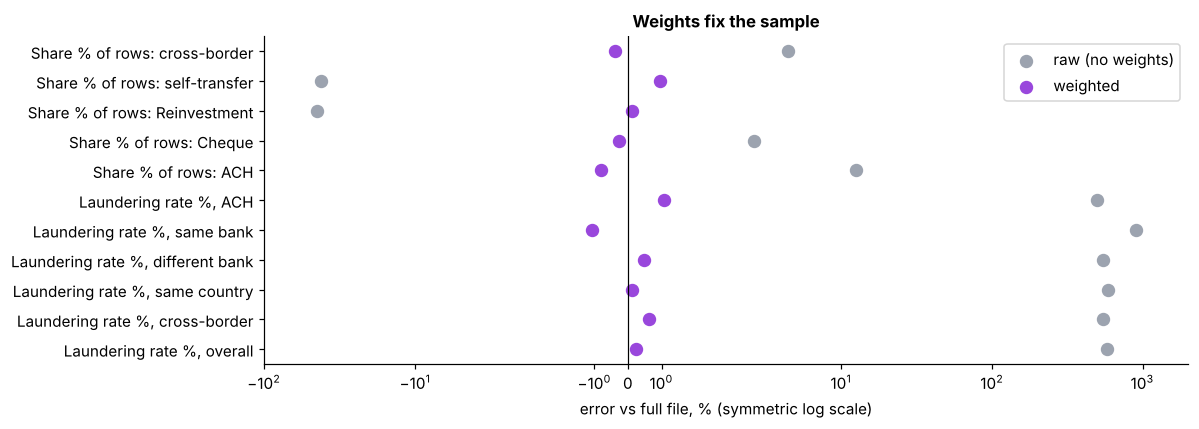

In [50]:
measures = [
    ("rate", "Laundering rate %, overall", "TRUE"),
    ("rate", "Laundering rate %, cross-border", "cross_border = 1"),
    ("rate", "Laundering rate %, same country", "cross_border = 0"),
    ("rate", "Laundering rate %, different bank", "cross_bank = 1"),
    ("rate", "Laundering rate %, same bank", "cross_bank = 0"),
    ("rate", "Laundering rate %, ACH", "\"Payment Format\" = 'ACH'"),
    ("share", "Share % of rows: ACH", "\"Payment Format\" = 'ACH'"),
    ("share", "Share % of rows: Cheque", "\"Payment Format\" = 'Cheque'"),
    ("share", "Share % of rows: Reinvestment", "\"Payment Format\" = 'Reinvestment'"),
    ("share", "Share % of rows: self-transfer", "self_transfer = 1"),
    ("share", "Share % of rows: cross-border", "cross_border = 1"),
]


def measure(kind, where, table, w):
    if kind == "rate":
        return one(f'SELECT 100 * SUM({w} * "Is Laundering") / SUM({w}) FROM {table} WHERE {where}')
    return one(f"SELECT 100 * SUM(CASE WHEN {where} THEN {w} ELSE 0 END) / SUM({w}) FROM {table}")


rep = pd.DataFrame([(name, measure(k, w_, "fullcut", "1"), measure(k, w_, "s", "weight"), measure(k, w_, "s", "1"))
                    for k, name, w_ in measures], columns=["Measure", "Full file (truth)", "Sample weighted", "Sample raw"])
rep["Weighted error %"] = 100 * (rep["Sample weighted"] / rep["Full file (truth)"] - 1)
rep["Raw error %"] = 100 * (rep["Sample raw"] / rep["Full file (truth)"] - 1)
display(rep.round(4))

fig, ax = plt.subplots(figsize=(11, 4))
y = np.arange(len(rep))
ax.axvline(0, color="black", lw=0.8)
ax.scatter(rep["Raw error %"], y, color=GREY, s=60, label="raw (no weights)")
ax.scatter(rep["Weighted error %"], y, color=PURPLE, s=60, label="weighted")
ax.set_yticks(y, rep["Measure"]); ax.set_xscale("symlog", linthresh=5); ax.set_xlim(-100, 2000)
ax.set_xlabel("error vs full file, % (symmetric log scale)"); ax.legend(); ax.set_title("Weights fix the sample")
plt.tight_layout(); plt.show()

**What the output shows.** With weights, every measure lands within about **±1.1%** of the full
file (overall rate **0.0893%** vs **0.0891%**; cross-border **0.1879%** vs **0.1867%**; ACH share
**11.7150%** vs **11.8113%**). Without weights, every laundering rate is **5–10 times too high**
(+501% to +909%), and row shares are off by up to **−45%** (Reinvestment rows and other self-transfers are
under-represented: a self-transfer has only one account, so it had only one chance to be picked
instead of two).

**What it means for us.** **Every** count, rate, chart and metric on the sample must use
`weight`. In pandas: `np.average(x, weights=df["weight"])`; in scikit-learn:
`precision_score(..., sample_weight=df["weight"])`, `average_precision_score(...,
sample_weight=...)`. Training the model can be done with or without weights, but **evaluation**
must use them, or precision will look several times better than it really is.

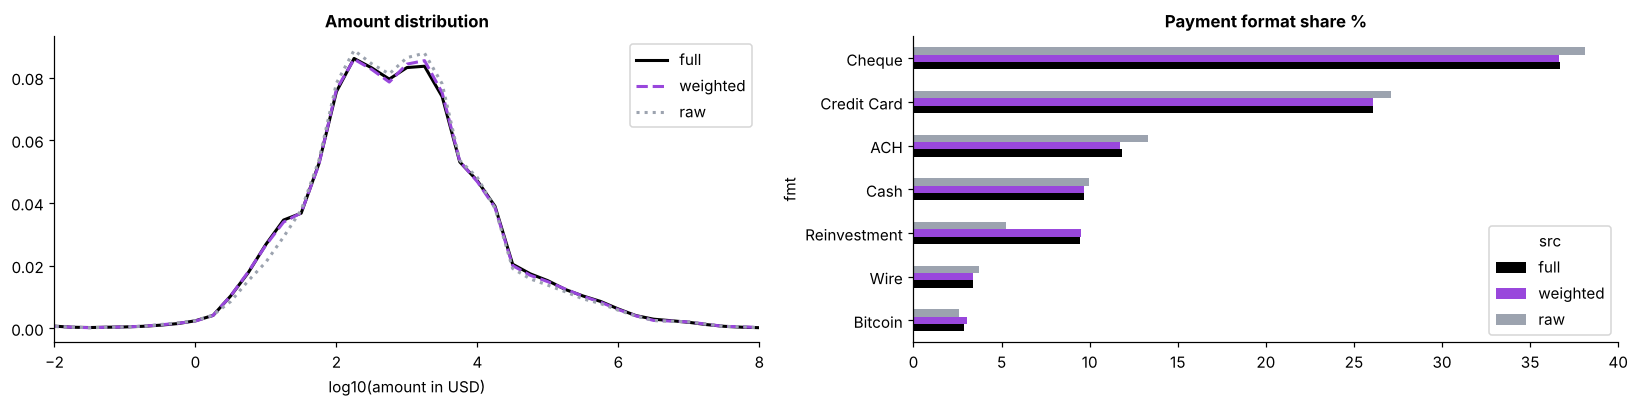

fmt,Bitcoin,Wire,Reinvestment,Cash,ACH,Credit Card,Cheque
src,,,,,,,
full,2.88,3.38,9.47,9.67,11.81,26.06,36.72
weighted,3.02,3.37,9.49,9.70,11.72,26.09,36.62
raw,2.56,3.73,5.25,9.94,13.29,27.13,38.10


In [51]:
amt_bins = sql('''
    WITH f AS (SELECT floor(log10(GREATEST(usd, 1e-6)) * 4) / 4 AS bin, 1.0 AS w FROM jusd WHERE Timestamp < TIMESTAMP '2022-09-11'),
         sw AS (SELECT floor(log10(GREATEST(s."Amount Paid" / fx.units_per_usd, 1e-6)) * 4) / 4 AS bin, weight AS w
                FROM s JOIN fx ON s."Payment Currency" = fx.currency)
    SELECT 'full' AS src, bin, SUM(w) AS n FROM f GROUP BY 1, 2
    UNION ALL SELECT 'weighted', bin, SUM(w) FROM sw GROUP BY 1, 2
    UNION ALL SELECT 'raw', bin, COUNT(*) FROM sw GROUP BY 1, 2
''')
shares = sql('''
    SELECT 'full' AS src, "Payment Format" AS fmt, 100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS pct
    FROM j WHERE Timestamp < TIMESTAMP '2022-09-11' GROUP BY 2
    UNION ALL SELECT 'weighted', "Payment Format", 100 * SUM(weight) / SUM(SUM(weight)) OVER () FROM s GROUP BY 2
    UNION ALL SELECT 'raw', "Payment Format", 100.0 * COUNT(*) / SUM(COUNT(*)) OVER () FROM s GROUP BY 2
''')
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))
for src, colour, ls in [("full", "black", "-"), ("weighted", PURPLE, "--"), ("raw", GREY, ":")]:
    d = amt_bins[amt_bins["src"] == src].sort_values("bin")
    ax[0].plot(d["bin"], d["n"] / d["n"].sum(), color=colour, ls=ls, lw=2, label=src)
ax[0].set_xlim(-2, 8); ax[0].set_xlabel("log10(amount in USD)"); ax[0].legend(); ax[0].set_title("Amount distribution")
pv = shares.pivot(index="fmt", columns="src", values="pct")[["full", "weighted", "raw"]].sort_values("full")
pv.plot.barh(ax=ax[1], color=["black", PURPLE, GREY]); ax[1].set_title("Payment format share %")
plt.tight_layout(); plt.show()
display(pv.round(2).T)

<a id="d3"></a>
## <span style="color:#9947dc">D3. The weights</span>

**Why.** Weights fix the averages, but they cost precision: a few hundred thousand normal rows each
standing for ~14 real rows behave like a smaller dataset. We need to know how much smaller, because
it tells us how noisy our precision numbers will be.

**How.** List the distinct weight values (there are only a few, by design), and compute the
**effective sample size** = (sum of weights)² ÷ (sum of squared weights). It is the number of
equally-weighted rows that would give the same precision.

In [52]:
wt = sql("""
    SELECT ROUND(weight, 4) AS weight, COUNT(*) AS rows, SUM("Is Laundering") AS laundering,
           SUM(weight) AS real_rows_represented
    FROM s GROUP BY 1 ORDER BY 1
""")
display(fmt_int(wt, ["rows", "laundering", "real_rows_represented"]))
ess = one("SELECT SUM(weight)^2 / SUM(weight^2) FROM s")
ess_clean = one('SELECT SUM(weight)^2 / SUM(weight^2) FROM s WHERE "Is Laundering" = 0')
print(f"Effective sample size: {ess:,.0f} of {n_s:,} rows ({100 * ess / n_s:.1f}%)")
print(f"Effective sample size, normal rows only: {ess_clean:,.0f}")

,weight,rows,laundering,real_rows_represented
0,1.0000,"165,687","4,522","165,687"
1,7.5454,"514,704",0,"3,883,641"
2,14.5730,"69,654",0,"1,015,068"


Effective sample size: 579,463 of 750,045 rows (77.3%)
Effective sample size, normal rows only: 578,488


**What the output shows.** There are only three weight values:
- **1** — **165,687** rows, including all **4,522** laundering rows: rows that touch a laundering
  account were always kept.
- **7.5454** — **514,704** rows: either side could have been picked, so the chance was
  1 − (1 − Q)² ≈ 13%.
- **14.5730** — **69,654** rows: only one side could have been picked (the other is a hub, or it is
  a self-transfer), so the chance was Q ≈ 6.9%.

The effective sample size is **579,463** (**77.3%** of the 750,045 rows).

**What it means for us.** The weights cost us about a quarter of the sample's precision, which is
acceptable. The bigger source of noise is that each laundering row counts once while each normal
row counts up to 14.6 times, so a handful of false alarms moves weighted precision a lot. Report
**confidence intervals** for precision, computed by resampling **accounts** (not rows).

<a id="d4"></a>
## <span style="color:#9947dc">D4. Full history vs partial history</span>

**Why.** This is the **biggest trap** for preprocessing. Only seed accounts have their full history
in the sample. Every other account appears only in the rows it shares with a seed. If you compute
account features (degree, counterparties, money received, pass-through ...) **from the sample**,
the values are wrong for those accounts — and the error is not random: it depends on how the
sample was built.

**How.** For each account, count its counterparties **inside the sample** and compare with its true
count over 1–10 Sept (`n_cpty` in `accounts.parquet`, counted on the full file).

In [53]:
pc = sql("""
    WITH e AS (SELECT acct_from AS a, acct_to AS b FROM s UNION ALL SELECT acct_to, acct_from FROM s),
         k AS (SELECT a AS acct, COUNT(DISTINCT b) AS cpty_in_sample, COUNT(*) AS rows_in_sample FROM e GROUP BY 1)
    SELECT CASE WHEN full_history THEN 'Full history (seed)' ELSE 'Partial history' END AS accounts,
           COUNT(*) AS n,
           MEDIAN(cpty_in_sample) AS median_cpty_in_sample, MEDIAN(n_cpty) AS median_cpty_true,
           100 * AVG(cpty_in_sample / n_cpty) AS avg_share_seen_pct,
           100 * AVG(CASE WHEN cpty_in_sample = n_cpty THEN 1.0 ELSE 0 END) AS exactly_right_pct
    FROM k JOIN sacc USING (acct) GROUP BY 1 ORDER BY 1
""")
display(fmt_int(pc, ["n"]).round(2))

rows_partial = one("""SELECT 100 * AVG(CASE WHEN seed_from = 0 OR seed_to = 0 THEN 1.0 ELSE 0 END) FROM s""")
print(f"Rows where at least one side has only partial history: {rows_partial:.1f}%")

,accounts,n,median_cpty_in_sample,median_cpty_true,avg_share_seen_pct,exactly_right_pct
0,Full history (seed),"40,561",3.0,3.0,100.00,100.00
1,Partial history,"77,999",1.0,4.0,32.99,9.21


Rows where at least one side has only partial history: 88.7%


**What the output shows.**
- **Seed accounts (40,561)**: the sample shows exactly their true number of counterparties —
  **100%** exactly right.
- **Partial-history accounts (77,999)**: in the sample they have a median of **1** counterparty,
  but really **4**. On average the sample shows only **32.99%** of their counterparties, and only
  **9.21%** of them come out exactly right.
- **88.7%** of sample rows have at least one side whose history is partial.

**What it means for us — the main rule for preprocessing:**
> **Compute account features on the full joined file, then attach them to the sample rows.**

Concretely: for each row in the sample at time *t*, compute the sender's and receiver's features
(degree, counterparties, received-count, recent bursts, conversion-before-send, ...) **from
`hi_small_joined.parquet`, using only transfers before *t***. DuckDB window functions do this over
the full 5M rows in seconds. Computing them from `sample.csv` would give wrong values for 88.7% of
rows, and wrong in a way linked to how we sampled (laundering accounts are always complete, normal
ones mostly not), which a model would happily learn.

<a id="d4b"></a>
## <span style="color:#9947dc">4b. The same features computed from the sample vs from the full file</span>

**Why.** D4 showed that partial accounts look smaller in the sample. Here we show what that does to
the actual **features** a model would get: we compute three point-in-time features twice for the
same sample rows — once from the sample alone, once from the full file (`pit`, section 12b) — and
compare.

**How.** For the sample's real transfers (self-transfers removed): sender's transfers sent before,
receiver's transfers received before, and the new-pair flag. Count how often the two versions agree,
and compare the laundering-vs-normal medians (normal rows weighted).

In [54]:
con.execute('''
    CREATE OR REPLACE TABLE sp_feat AS
    WITH b AS (
        SELECT ROW_NUMBER() OVER (ORDER BY Timestamp, acct_from, acct_to, "Amount Paid", "Amount Received",
                                           "Payment Format", "Payment Currency", "Receiving Currency") AS srid,
               Timestamp AS t, acct_from, acct_to, "Amount Paid" AS paid, "Amount Received" AS recv,
               "Payment Format" AS fmt, "Payment Currency" AS pcur, "Receiving Currency" AS rcur,
               "Is Laundering" AS y, weight
        FROM s WHERE self_transfer = 0),
    e AS (SELECT acct, t, SUM(SUM(sent)) OVER w AS cs, SUM(SUM(rec)) OVER w AS cr
          FROM (SELECT acct_from AS acct, t, 1 AS sent, 0 AS rec FROM b UNION ALL SELECT acct_to, t, 0, 1 FROM b)
          GROUP BY acct, t WINDOW w AS (PARTITION BY acct ORDER BY t ROWS UNBOUNDED PRECEDING)),
    snd AS (SELECT b.srid, COALESCE(e.cs, 0) AS s_snd_sent_before FROM b ASOF LEFT JOIN e ON b.acct_from = e.acct AND b.t > e.t),
    rcv AS (SELECT b.srid, COALESCE(e.cr, 0) AS s_rcv_recv_before FROM b ASOF LEFT JOIN e ON b.acct_to = e.acct AND b.t > e.t),
    pr AS (SELECT srid, CAST(ROW_NUMBER() OVER (PARTITION BY acct_from, acct_to ORDER BY srid) = 1 AS INT) AS s_new_pair FROM b)
    SELECT b.*, snd.s_snd_sent_before, rcv.s_rcv_recv_before, pr.s_new_pair,
           p.snd_sent_before AS f_snd_sent_before, p.rcv_recv_before AS f_rcv_recv_before, p.new_pair AS f_new_pair
    FROM b JOIN snd USING (srid) JOIN rcv USING (srid) JOIN pr USING (srid)
    JOIN pit p ON p.t = b.t AND p.acct_from = b.acct_from AND p.acct_to = b.acct_to AND p.paid = b.paid
              AND p.recv = b.recv AND p.fmt = b.fmt AND p.pcur = b.pcur AND p.rcur = b.rcur
''')
print(f"Sample real transfers matched to the full-file features: {one('SELECT COUNT(*) FROM sp_feat'):,} "
      f"of {one('SELECT COUNT(*) FROM s WHERE self_transfer = 0'):,}")
agree = sql('''
    SELECT 100 * AVG(CASE WHEN s_snd_sent_before = f_snd_sent_before THEN 1.0 ELSE 0 END) AS sender_sent_before_same_pct,
           100 * AVG(CASE WHEN s_rcv_recv_before = f_rcv_recv_before THEN 1.0 ELSE 0 END) AS receiver_received_before_same_pct,
           100 * AVG(CASE WHEN s_new_pair = f_new_pair THEN 1.0 ELSE 0 END) AS new_pair_same_pct,
           100 * AVG(CASE WHEN s_new_pair = 1 AND f_new_pair = 0 THEN 1.0 ELSE 0 END) AS falsely_new_pair_pct
    FROM sp_feat
''')
display(agree.round(2))
cmpf = sql('''
    SELECT CASE WHEN y = 1 THEN 'Laundering' ELSE 'Normal' END AS class,
           quantile_cont(s_snd_sent_before, 0.5) AS sample_sender_sent_before, quantile_cont(f_snd_sent_before, 0.5) AS full_sender_sent_before,
           quantile_cont(s_rcv_recv_before, 0.5) AS sample_receiver_received_before, quantile_cont(f_rcv_recv_before, 0.5) AS full_receiver_received_before,
           100 * SUM(weight * s_new_pair) / SUM(weight) AS sample_new_pair_pct_w, 100 * SUM(weight * f_new_pair) / SUM(weight) AS full_new_pair_pct_w
    FROM sp_feat GROUP BY 1 ORDER BY 1
''')
display(cmpf.round(2).T)

Sample real transfers matched to the full-file features: 699,346 of 699,346


,sender_sent_before_same_pct,receiver_received_before_same_pct,new_pair_same_pct,falsely_new_pair_pct
0,62.92,66.5,100.0,0.0


,0,1
class,Laundering,Normal
sample_sender_sent_before,3.0,12.0
full_sender_sent_before,3.0,17.0
sample_receiver_received_before,6.0,9.0
full_receiver_received_before,6.0,11.0
sample_new_pair_pct_w,76.36,14.32
full_new_pair_pct_w,76.36,14.32


**What the output shows.** All **699,346** real transfers in the sample were matched to their
full-file features.
- **Sender's earlier sent-count** is the same in both versions for only **62.92%** of rows;
  **receiver's earlier received-count** for only **66.5%**.
- **The error depends on the class:** for laundering rows, the sample and full versions have the
  same medians (sender **3** / receiver **6**), because laundering accounts are always complete. For
  normal rows the sample version is **too low** (sender **12** vs **17**, receiver **9** vs **11**).
  So a feature computed on the sample makes normal rows look more like laundering rows than they
  really are — a distortion created by the sampling, linked to the label.
- **The new-pair flag is identical in 100% of rows.** That is not luck: for any row in the sample,
  either the sender or the receiver is a seed, and a seed's full history includes every earlier
  transfer between that same pair. So **pair-based features are safe** to compute on the sample;
  account totals are not.

**What it means for us.** Rule from D4 confirmed on real features: **account totals from the full
file**; pair features can come from either. When in doubt, compute everything from the full file.

<a id="d5"></a>
## <span style="color:#9947dc">D5. Leakage audit</span>

**Why.** "Leakage" means giving the model a column that secretly contains the answer. The model
then looks brilliant in testing and is useless in reality. The sample has several such columns
**because of how it was built**. Here we prove, with numbers, which ones.

**How.** For each suspicious column, show the laundering rate for each of its values. If one value
has **zero** laundering and another has a lot, the column is giving away the answer.

In [55]:
def rate_tbl(expr, name, table="s"):
    d = sql(f'SELECT {expr} AS value, COUNT(*) AS rows, SUM("Is Laundering") AS laundering FROM {table} GROUP BY 1 ORDER BY 1')
    d.insert(0, "column", name)
    d["laundering_rate_pct"] = 100 * d["laundering"] / d["rows"]
    return d


leak = pd.concat([
    rate_tbl("CASE WHEN weight = 1 THEN 'weight = 1' ELSE 'weight > 1' END", "weight / incl_prob"),
    rate_tbl("seed_from + seed_to", "seed_from + seed_to"),
    rate_tbl("CAST(scheme_truncated AS INT)", "scheme_truncated"),
    rate_tbl("CASE WHEN \"Attempt ID\" IS NULL THEN 'empty' ELSE 'filled' END", "Attempt ID / Pattern Type"),
    rate_tbl("CAST(a.touches_laundering AS INT)", "touches_laundering (sender, accounts.parquet)",
             "s JOIN sacc a ON s.acct_from = a.acct"),
], ignore_index=True)
display(fmt_int(leak, ["rows", "laundering"]).round(3))

,column,value,rows,laundering,laundering_rate_pct
0,weight / incl_prob,weight = 1,"165,687","4,522",2.729
1,weight / incl_prob,weight > 1,"584,358",0,0.000
2,seed_from + seed_to,1,"665,187",633,0.095
3,seed_from + seed_to,2,"84,858","3,889",4.583
4,scheme_truncated,0,"749,408","3,885",0.518
5,scheme_truncated,1,637,637,100.000
6,Attempt ID / Pattern Type,empty,"747,491","1,968",0.263
7,Attempt ID / Pattern Type,filled,"2,554","2,554",100.000
8,"touches_laundering (sender, accounts.parquet)",0,"612,898",0,0.000
9,"touches_laundering (sender, accounts.parquet)",1,"137,147","4,522",3.297


**What the output shows.**
- `weight` / `incl_prob`: rows with weight 1 have a **2.729%** laundering rate; rows with weight
  above 1 have **0** laundering out of **584,358**. The weight alone tells the model "this row is
  definitely normal" for 78% of the data.
- `seed_from + seed_to`: both sides seeds → **4.583%**; one side → **0.095%** (48x apart).
- `scheme_truncated`: when it is 1, the row is laundering **100%** of the time (637 rows).
- `Attempt ID` / `Pattern Type`: filled → laundering **100%** of the time (2,554 rows).
- `touches_laundering` of the sender (from `accounts.parquet`): 0 → **0** laundering out of
  612,898 rows; 1 → **3.297%**. It **is** the label, spread to the account.
- Not shown as numbers but same problem: `appearances` and `n_cpty` in `accounts.parquet` are
  counted over the whole 1–10 Sept window, so for a row on 2 Sept they include transfers from the
  future.

**What it means for us.** None of these columns may ever be a model input. Drop them from X before
every fit:

```python
NEVER_FEATURES = ["Attempt ID", "Pattern Type", "scheme_truncated", "scheme_moved",
                  "seed_from", "seed_to", "incl_prob", "weight",
                  "acct_from", "acct_to", "Account", "Account.1", "Entity ID_from", "Entity ID_to",
                  "Entity Name_from", "Entity Name_to", "Is Laundering"]
# and never join touches_laundering / appearances / n_cpty / full_history from accounts.parquet
```
If a model scores suspiciously well (PR-AUC near 1), the first thing to check is this list.

<a id="d6"></a>
## <span style="color:#9947dc">D6. Time split preview</span>

**Why.** The agreed primary split is by time: **train 1–6 Sept, validation 7 Sept, test 8–10
Sept**. Before modelling we should know how different these periods are, because a model tuned on
one prevalence can behave very differently on another.

**How.** Per day in the sample: rows, laundering rows, weighted laundering rate, schemes that end
that day. Then the same per split window by row date. We do this twice: (a) each row goes to the
window of its own date; (b) the way the real `time` mode does it — a scheme that crosses a boundary
goes **whole** to the split of its **last** transfer, so the model never trains on part of a scheme
whose end is in the future.

,day,rows,laundering,weighted_rate_pct,schemes_ending,of_which_truncated
0,2022-09-01,"136,063",322,0.0289,3,0
1,2022-09-02,"115,089",408,0.0544,10,0
2,2022-09-03,"32,512",391,0.1892,13,0
3,2022-09-04,"32,510",407,0.1968,29,0
4,2022-09-05,"75,068",471,0.0979,32,0
5,2022-09-06,"75,226",531,0.1101,37,0
6,2022-09-07,"75,170",497,0.1029,31,1
7,2022-09-08,"75,081",539,0.1119,34,1
8,2022-09-09,"100,487",514,0.0789,50,12
9,2022-09-10,"32,839",442,0.2131,124,88


(a) Each row in the window of its own date:


,split,rows,laundering,weighted_rate_pct
0,1. train (1-6 Sept),"466,468","2,530",0.0781
1,2. val (7 Sept),"75,170",497,0.1029
2,3. test (8-10 Sept),"208,407","1,495",0.1115


Test weighted rate ÷ train weighted rate: 1.43x
(b) As the real `time` mode does it — a scheme goes whole to the split of its LAST transfer:


,split,rows,laundering,weighted_rate_pct,schemes
0,1. train (1-6 Sept),"465,933","1,995",0.0616,124
1,2. val (7 Sept),"74,996",323,0.0669,31
2,3. test (8-10 Sept),"209,116","2,204",0.1643,208


Test weighted rate ÷ train weighted rate: 2.67x


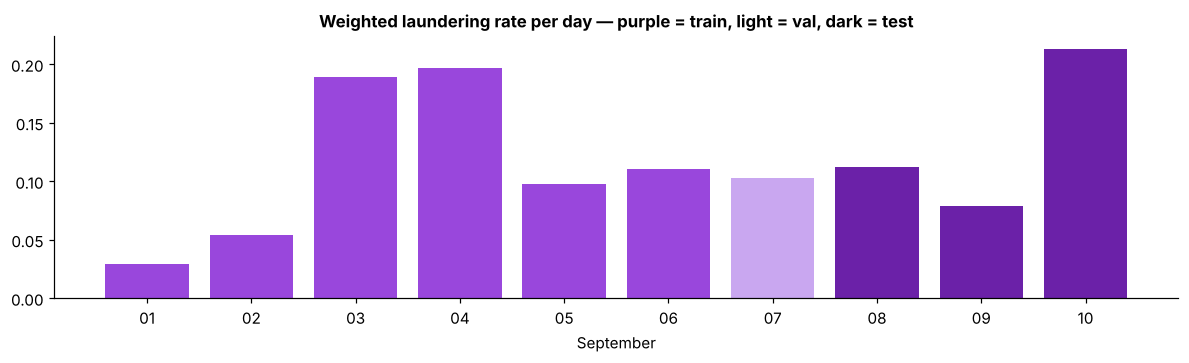

In [56]:
day = sql("""
    SELECT CAST(date_trunc('day', Timestamp) AS DATE) AS day, COUNT(*) AS rows, SUM("Is Laundering") AS laundering,
           100 * SUM(weight * "Is Laundering") / SUM(weight) AS weighted_rate_pct
    FROM s GROUP BY 1 ORDER BY 1
""")
ends = sql("""SELECT day, COUNT(*) AS schemes_ending, SUM(CAST(tr AS INT)) AS of_which_truncated FROM
              (SELECT CAST(date_trunc('day', MAX(Timestamp)) AS DATE) AS day, BOOL_OR(scheme_truncated) AS tr
               FROM s WHERE "Attempt ID" IS NOT NULL GROUP BY "Attempt ID") GROUP BY 1""")
day = day.merge(ends, on="day", how="left").fillna({"schemes_ending": 0, "of_which_truncated": 0})
display(fmt_int(day, ["rows", "laundering", "schemes_ending", "of_which_truncated"]).round(4))

win = sql("""
    SELECT CASE WHEN Timestamp < TIMESTAMP '2022-09-07' THEN '1. train (1-6 Sept)'
                WHEN Timestamp < TIMESTAMP '2022-09-08' THEN '2. val (7 Sept)'
                ELSE '3. test (8-10 Sept)' END AS split,
           COUNT(*) AS rows, SUM("Is Laundering") AS laundering,
           100 * SUM(weight * "Is Laundering") / SUM(weight) AS weighted_rate_pct
    FROM s GROUP BY 1 ORDER BY 1
""")
print("(a) Each row in the window of its own date:")
display(fmt_int(win, ["rows", "laundering"]).round(4))
print(f"Test weighted rate ÷ train weighted rate: {win.loc[2, 'weighted_rate_pct'] / win.loc[0, 'weighted_rate_pct']:.2f}x")

win2 = sql("""
    WITH e AS (SELECT "Attempt ID", MAX(Timestamp) AS last_ts FROM s WHERE "Attempt ID" IS NOT NULL GROUP BY 1)
    SELECT CASE WHEN COALESCE(e.last_ts, s.Timestamp) < TIMESTAMP '2022-09-07' THEN '1. train (1-6 Sept)'
                WHEN COALESCE(e.last_ts, s.Timestamp) < TIMESTAMP '2022-09-08' THEN '2. val (7 Sept)'
                ELSE '3. test (8-10 Sept)' END AS split,
           COUNT(*) AS rows, SUM("Is Laundering") AS laundering,
           100 * SUM(weight * "Is Laundering") / SUM(weight) AS weighted_rate_pct,
           COUNT(DISTINCT s."Attempt ID") AS schemes
    FROM s LEFT JOIN e ON s."Attempt ID" = e."Attempt ID"
    GROUP BY 1 ORDER BY 1
""")
print("(b) As the real `time` mode does it — a scheme goes whole to the split of its LAST transfer:")
display(fmt_int(win2, ["rows", "laundering"]).round(4))
print(f"Test weighted rate ÷ train weighted rate: {win2.loc[2, 'weighted_rate_pct'] / win2.loc[0, 'weighted_rate_pct']:.2f}x")

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(pd.to_datetime(day["day"]).dt.strftime("%d"), day["weighted_rate_pct"],
       color=[PURPLE if d < pd.Timestamp("2022-09-07") else (LILAC if d < pd.Timestamp("2022-09-08") else DARK)
              for d in pd.to_datetime(day["day"])])
ax.set_title("Weighted laundering rate per day — purple = train, light = val, dark = test"); ax.set_xlabel("September")
plt.tight_layout(); plt.show()

**What the output shows.**
- Per day, the weighted rate ranges from **0.0289%** (1 Sept) to **0.2131%** (10 Sept). **124**
  schemes end on 10 Sept, and **88** of those are truncated: they only "end" there because their
  later transfers were dropped.
- **(a) By row date**, train has **0.0781%**, val **0.1029%**, test **0.1115%** — test is
  **1.43x** train.
- **(b) The real time split** (schemes moved whole to the split of their last transfer): train
  **465,933** rows / **1,995** laundering / **0.0616%** / **124** schemes; val **74,996** /
  **323** / **0.0669%** / **31**; test **209,116** / **2,204** / **0.1643%** / **208**. Test is
  **2.67x** train. These match the `time` mode output exactly.

**What it means for us.**
- Test has almost three times the laundering density of train, because long schemes that end late
  are pulled whole into test. This is the honest price of keeping the future out of train.
- **Do not pick a probability threshold on validation and reuse it on test.** Set alert thresholds
  by **alert volume** (e.g. "flag the top 1% of transfers") and report PR-AUC **next to each
  split's base rate**.
- Validation is small (**323** laundering rows, **31** schemes): use it for early stopping and
  threshold choice only; do hyperparameter search with time-based cross-validation inside train.

,0
accounts_laundering_in_test,"2,725"
of_which_also_in_train,"2,665"
of_which_also_laundering_in_train,101
all_accounts_in_test,"79,634"
all_also_in_train,"73,325"
laundering_test_accounts_seen_in_train_pct,97.8
laundering_test_accounts_laundering_in_train_pct,3.7
all_test_accounts_seen_in_train_pct,92.1


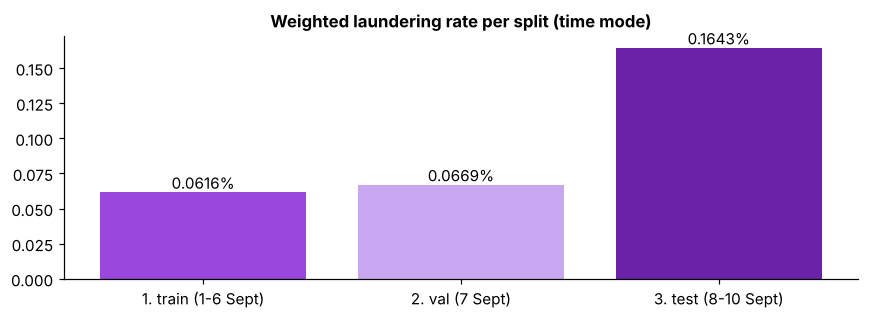

In [57]:
ov = sql('''
    WITH e AS (SELECT "Attempt ID", MAX(Timestamp) AS last_ts FROM s WHERE "Attempt ID" IS NOT NULL GROUP BY 1),
         r AS (SELECT s.*, CASE WHEN COALESCE(e.last_ts, s.Timestamp) < TIMESTAMP '2022-09-07' THEN 'train'
                                WHEN COALESCE(e.last_ts, s.Timestamp) < TIMESTAMP '2022-09-08' THEN 'val' ELSE 'test' END AS sp
               FROM s LEFT JOIN e ON s."Attempt ID" = e."Attempt ID"),
         a AS (SELECT acct_from AS acct, sp, "Is Laundering" AS y FROM r UNION ALL SELECT acct_to, sp, "Is Laundering" FROM r),
         per AS (SELECT acct, BOOL_OR(sp = 'train') AS in_train, BOOL_OR(sp = 'test') AS in_test,
                        BOOL_OR(sp = 'test' AND y = 1) AS launders_in_test, BOOL_OR(sp = 'train' AND y = 1) AS launders_in_train
                 FROM a GROUP BY 1)
    SELECT COUNT(*) FILTER (WHERE launders_in_test) AS accounts_laundering_in_test,
           COUNT(*) FILTER (WHERE launders_in_test AND in_train) AS of_which_also_in_train,
           COUNT(*) FILTER (WHERE launders_in_test AND launders_in_train) AS of_which_also_laundering_in_train,
           COUNT(*) FILTER (WHERE in_test) AS all_accounts_in_test,
           COUNT(*) FILTER (WHERE in_test AND in_train) AS all_also_in_train
    FROM per
''')
ov["laundering_test_accounts_seen_in_train_pct"] = 100 * ov["of_which_also_in_train"] / ov["accounts_laundering_in_test"]
ov["laundering_test_accounts_laundering_in_train_pct"] = 100 * ov["of_which_also_laundering_in_train"] / ov["accounts_laundering_in_test"]
ov["all_test_accounts_seen_in_train_pct"] = 100 * ov["all_also_in_train"] / ov["all_accounts_in_test"]
display(fmt_int(ov, ov.columns[:5]).round(1).T)

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(win2["split"], win2["weighted_rate_pct"], color=[PURPLE, LILAC, DARK])
for i, v in enumerate(win2["weighted_rate_pct"]):
    ax.text(i, v, f"{v:.4f}%", ha="center", va="bottom")
ax.set_title("Weighted laundering rate per split (time mode)")
plt.tight_layout(); plt.show()

**What the output shows.**
- **2,725** accounts launder in the test period. **2,665** of them (**97.8%**) also appear somewhere
  in train — but only **101** (**3.7%**) **launder** in train. The rest appear in train as ordinary,
  normal activity.
- Of all **79,634** accounts in test, **92.1%** also appear in train.
- The bar chart repeats D6 (b): test's weighted rate is the highest of the three splits.

**What it means for us.** The model will mostly see test-period launderers *behaving normally* in
train, and almost never laundering. That is realistic (accounts go bad over time) and fair. It also
means **account IDs must never be features** — they appear on both sides — and that the "history
before t" features have real data to work with for nearly every test account.

<a id="d7"></a>
## <span style="color:#9947dc">D7. Schemes available for the agent</span>

**Why.** The agent is scored on rebuilding schemes. A scheme that was cut short by the 11 Sept drop
cannot be scored fairly (the "right answer" has transfers we removed). And the 1,968 laundering
rows without any scheme cannot be scored as schemes at all.

**How.** Per pattern type: schemes in the sample, truncated, complete. Then the unexplained
laundering rows.

In [58]:
ag = sql("""
    SELECT "Pattern Type" AS pattern, COUNT(DISTINCT "Attempt ID") AS schemes,
           COUNT(DISTINCT CASE WHEN scheme_truncated THEN "Attempt ID" END) AS truncated
    FROM s WHERE "Attempt ID" IS NOT NULL GROUP BY 1 ORDER BY 2 DESC
""")
ag["complete"] = ag["schemes"] - ag["truncated"]
ag.loc[len(ag)] = ["TOTAL", ag["schemes"].sum(), ag["truncated"].sum(), ag["complete"].sum()]
display(ag)

unexp = sql("""SELECT "Payment Format", COUNT(*) AS unexplained_laundering_rows
               FROM s WHERE "Is Laundering" = 1 AND "Attempt ID" IS NULL GROUP BY 1 ORDER BY 2 DESC""")
print(f"Unexplained laundering rows in the sample: {unexp['unexplained_laundering_rows'].sum():,}")
display(unexp.T)

,pattern,schemes,truncated,complete
0,CYCLE,54,11,43
1,GATHER-SCATTER,51,27,24
2,FAN-OUT,48,12,36
3,BIPARTITE,45,5,40
4,SCATTER-GATHER,44,16,28
5,RANDOM,41,9,32
6,FAN-IN,40,13,27
7,STACK,40,9,31
8,TOTAL,363,102,261


Unexplained laundering rows in the sample: 1,968


,0,1,2,3,4
Payment Format,ACH,Cheque,Credit Card,Cash,Bitcoin
unexplained_laundering_rows,1275,324,206,108,55


**What the output shows.** Of the **363** schemes in the sample, **102** are truncated, leaving
**261 complete** schemes for scoring the agent. GATHER-SCATTER is hit hardest (**27** of 51
truncated — they are the longest-running type), BIPARTITE least (**5** of 45). The sample also has
**1,968** unexplained laundering rows (ACH 1,275, Cheque 324, Credit Card 206, Cash 108, Bitcoin 55).

**What it means for us.** Score the agent's case reconstruction on the **261 complete schemes**
only (filter `scheme_truncated == False`). With the time split, the test set's complete schemes are
the headline agent evaluation. The 1,968 unexplained rows can be used to test the classifier, not
the case reconstruction.

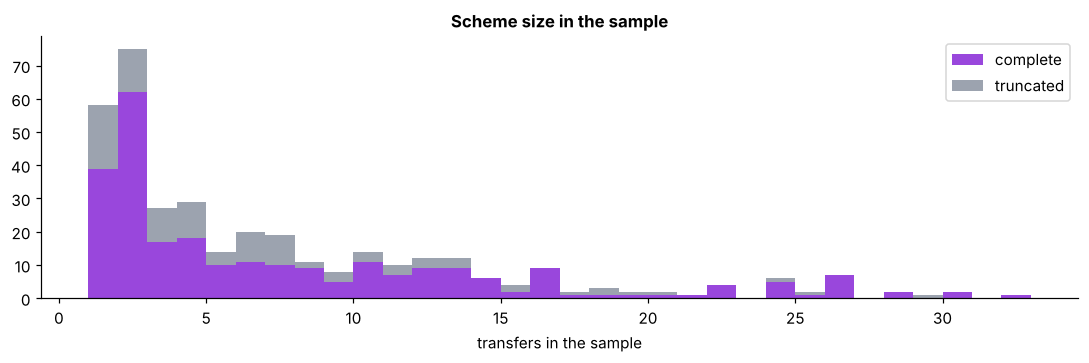

truncated,complete,truncated
ends_in_test_window,,
ends 1-7 Sept,154,1
ends 8-10 Sept (test),107,101


In [59]:
ss = sql('''SELECT "Attempt ID", COUNT(*) AS transfers, BOOL_OR(scheme_truncated) AS truncated,
                   MAX(Timestamp) >= TIMESTAMP '2022-09-08' AS ends_in_test_window
            FROM s WHERE "Attempt ID" IS NOT NULL GROUP BY 1''')
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.hist([ss.loc[~ss["truncated"], "transfers"], ss.loc[ss["truncated"], "transfers"]], bins=range(1, 34),
        stacked=True, color=[PURPLE, GREY], label=["complete", "truncated"])
ax.set_xlabel("transfers in the sample"); ax.set_title("Scheme size in the sample"); ax.legend()
plt.tight_layout(); plt.show()
tab = pd.crosstab(ss["ends_in_test_window"].map({True: "ends 8-10 Sept (test)", False: "ends 1-7 Sept"}),
                  ss["truncated"].map({True: "truncated", False: "complete"}))
display(tab)

<a id="d8"></a>
## <span style="color:#9947dc">D8. Do the signals hold every day?</span>

**Why.** A signal that is strong over the whole window but flips on some days would be risky to
rely on, especially with a time split.

**How.** For each day in the sample, compute (weighted) how many times riskier cross-border is than
same-country, and different-bank than same-bank.

,day,cross_border_x,cross_bank_x
0,2022-09-01,5.28,55.82
1,2022-09-02,2.57,3.68
2,2022-09-03,2.65,1.55
3,2022-09-04,2.87,4.94
4,2022-09-05,3.05,2.86
5,2022-09-06,3.36,1.97
6,2022-09-07,4.15,2.21
7,2022-09-08,3.68,2.62
8,2022-09-09,3.61,2.81
9,2022-09-10,3.15,1.93


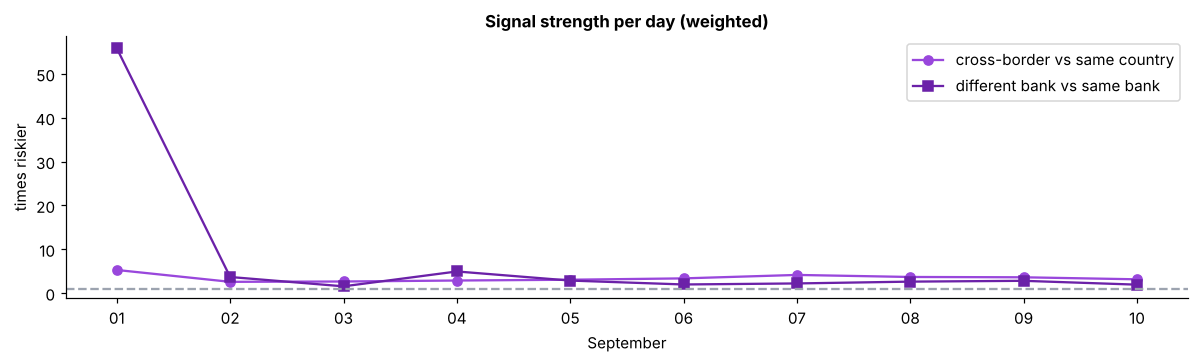

In [60]:
stab = sql("""
    SELECT CAST(date_trunc('day', Timestamp) AS DATE) AS day,
           (SUM(CASE WHEN cross_border = 1 THEN weight * "Is Laundering" END) / SUM(CASE WHEN cross_border = 1 THEN weight END)) /
           (SUM(CASE WHEN cross_border = 0 THEN weight * "Is Laundering" END) / SUM(CASE WHEN cross_border = 0 THEN weight END)) AS cross_border_x,
           (SUM(CASE WHEN cross_bank = 1 THEN weight * "Is Laundering" END) / SUM(CASE WHEN cross_bank = 1 THEN weight END)) /
           (SUM(CASE WHEN cross_bank = 0 THEN weight * "Is Laundering" END) / SUM(CASE WHEN cross_bank = 0 THEN weight END)) AS cross_bank_x
    FROM s GROUP BY 1 ORDER BY 1
""")
display(stab.round(2))

fig, ax = plt.subplots(figsize=(11, 3.4))
lab = pd.to_datetime(stab["day"]).dt.strftime("%d")
ax.plot(lab, stab["cross_border_x"], marker="o", color=PURPLE, label="cross-border vs same country")
ax.plot(lab, stab["cross_bank_x"], marker="s", color=DARK, label="different bank vs same bank")
ax.axhline(1, color=GREY, ls="--"); ax.set_ylabel("times riskier"); ax.set_xlabel("September"); ax.legend()
ax.set_title("Signal strength per day (weighted)")
plt.tight_layout(); plt.show()

**What the output shows.** Cross-border is riskier than same-country on **every** day: between
**2.57x** and **5.28x**. Different-bank is riskier than same-bank on every day too, but the number
jumps around (from **1.55x** to **55.82x**) because same-bank laundering is so rare (107 rows in
the whole file) that one or two rows more or less on a given day swing the ratio.

**What it means for us.** Both signals are stable in direction across the whole window, so they
are safe to use with a time split. Don't read anything into the size of the daily cross-bank ratio.

<a id="d9"></a>
## <span style="color:#9947dc">D9. What the agent can and cannot see</span>

**Why.** The agent starts from an alert and follows the money: who sent to this account, where did
it go next. In the sample, it can trust an account's history only if that account is a seed. We
need to know how often the agent will hit an account whose history is incomplete.

**How.** For accounts in a scheme: what share are seeds. For their direct counterparties (one step
away): what share are seeds. Then: of the transfers going **into** a scheme account from outside
the scheme, how many come from a partial-history account.

In [61]:
vis = sql("""
    WITH sch AS (SELECT DISTINCT acct_from AS acct FROM s WHERE "Attempt ID" IS NOT NULL
                 UNION SELECT acct_to FROM s WHERE "Attempt ID" IS NOT NULL),
         nb AS (SELECT DISTINCT acct_to AS acct FROM s WHERE acct_from IN (SELECT acct FROM sch)
                UNION SELECT acct_from FROM s WHERE acct_to IN (SELECT acct FROM sch))
    SELECT 'Accounts in a scheme' AS who, COUNT(*) AS accounts, 100 * AVG(CAST(full_history AS INT)) AS full_history_pct
    FROM sch JOIN sacc USING (acct)
    UNION ALL
    SELECT 'One step from a scheme account (not in a scheme)', COUNT(*), 100 * AVG(CAST(full_history AS INT))
    FROM nb JOIN sacc USING (acct) WHERE acct NOT IN (SELECT acct FROM sch)
""")
display(fmt_int(vis, ["accounts"]).round(2))

# How fast is "give me every transfer of account X" on the FULL 5M-row file?
import time
example = one("SELECT acct FROM sacc WHERE NOT full_history ORDER BY appearances DESC, acct LIMIT 1")
t0 = time.perf_counter()
hist = sql(f"""SELECT Timestamp, acct_from, acct_to, "Amount Paid", "Payment Format" FROM j
               WHERE acct_from = '{example}' OR acct_to = '{example}' ORDER BY Timestamp""")
secs = time.perf_counter() - t0
in_sample = one(f"SELECT COUNT(*) FROM s WHERE acct_from = '{example}' OR acct_to = '{example}'")
print(f"Account {example}: {in_sample:,} transfers visible in the sample, {len(hist):,} in the full file. "
      f"Full-file lookup took {secs:.2f} s.")

,who,accounts,full_history_pct
0,Accounts in a scheme,"2,667",100.00
1,One step from a scheme account (not in a scheme),"8,283",7.98


Account 70:100428660: 16,540 transfers visible in the sample, 169,756 in the full file. Full-file lookup took 0.78 s.


**What the output shows.** All **2,667** accounts that take part in a scheme have full history in
the sample (**100%**). But of the **8,283** accounts one step away from a scheme account, only
**7.98%** have full history.

**What it means for us.** Inside a scheme the agent sees everything. As soon as it follows the
money **one step outside** the scheme, 92% of the accounts it reaches are only partly visible in
the sample — "this account made no other transfers" would usually be false. Two simple options:
1. **Recommended:** the agent's lookup tools query the **full joined parquet** with DuckDB, and
   the sample is used only to pick alerts and evaluate. The example above shows why: hub account
   `70:100428660` has **16,540** transfers in the sample but **169,756** in the full file, and the
   full-file lookup took **0.51 s** here.
2. If the agent must stay on the sample, every tool result must say whether the account is a seed
   (`seed_from` / `seed_to`), and the agent must say "history incomplete" instead of drawing
   conclusions about non-seeds.

<a id="d9b"></a>
## <span style="color:#9947dc">9b. A sample case, as the agent would see it</span>

**Why.** To make D9 concrete: take one complete scheme from the test period and look at what the
agent has in the sample for each of its accounts, compared with the full file.

**How.** Pick the complete FAN-OUT scheme in the test window closest to 8 transfers. Show its
transfers, then for each account: seed or not, transfers in the sample, transfers in the full file
(1–10 Sept).

In [62]:
pick = sql('''
    SELECT "Attempt ID", COUNT(*) AS n FROM s
    WHERE "Attempt ID" IS NOT NULL AND NOT scheme_truncated AND "Pattern Type" = 'FAN-OUT'
    GROUP BY 1 HAVING MAX(Timestamp) >= TIMESTAMP '2022-09-08'
    ORDER BY abs(COUNT(*) - 8), 1 LIMIT 1
''')
att = int(pick.loc[0, "Attempt ID"])
case = sql(f'''SELECT Timestamp, acct_from, acct_to, "Amount Paid", "Payment Currency", "Payment Format", seed_from, seed_to
               FROM s WHERE "Attempt ID" = {att} ORDER BY Timestamp''')
print(f"Scheme {att} (FAN-OUT, complete, test period):")
display(case)
accts = sorted(set(case["acct_from"]) | set(case["acct_to"]))
in_list = ", ".join("'" + a + "'" for a in accts)
card = sql(f'''
    WITH sa AS (SELECT a, COUNT(*) AS in_sample FROM (SELECT acct_from AS a FROM s UNION ALL SELECT acct_to FROM s WHERE acct_from <> acct_to)
                WHERE a IN ({in_list}) GROUP BY 1),
         fa AS (SELECT a, COUNT(*) AS in_full FROM (SELECT acct_from AS a FROM fullcut UNION ALL SELECT acct_to FROM fullcut WHERE acct_from <> acct_to)
                WHERE a IN ({in_list}) GROUP BY 1)
    SELECT sacc.acct, sacc.full_history AS seed, sa.in_sample AS transfers_in_sample, fa.in_full AS transfers_in_full_file
    FROM sacc JOIN sa ON sacc.acct = sa.a JOIN fa ON sacc.acct = fa.a ORDER BY transfers_in_full_file DESC, sacc.acct
''')
display(card)
nb_cnt = sql(f'''
    WITH n AS (SELECT DISTINCT acct_to AS a FROM fullcut WHERE acct_from IN ({in_list})
               UNION SELECT DISTINCT acct_from FROM fullcut WHERE acct_to IN ({in_list}))
    SELECT COUNT(*) AS neighbours_in_full_file,
           COUNT(*) FILTER (WHERE a IN (SELECT acct FROM sacc WHERE full_history)) AS neighbours_with_full_history_in_sample
    FROM n WHERE a NOT IN ({in_list})
''')
display(nb_cnt)

Scheme 136 (FAN-OUT, complete, test period):


,Timestamp,acct_from,acct_to,Amount Paid,Payment Currency,Payment Format,seed_from,seed_to
0,2022-09-04 17:33:00,22:800241D60,21381:8007CA940,126219.49,Yuan,ACH,1,1
1,2022-09-05 13:14:00,22:800241D60,11:8002D9F80,8893.62,Euro,ACH,1,1
2,2022-09-06 05:26:00,22:800241D60,1674:80072E610,14436.12,US Dollar,ACH,1,1
3,2022-09-06 08:07:00,22:800241D60,12:80084A830,653.56,US Dollar,ACH,1,1
4,2022-09-07 07:09:00,22:800241D60,1601:800669CE0,11986.14,US Dollar,ACH,1,1
5,2022-09-07 11:19:00,22:800241D60,795:8005C22F0,14125.59,US Dollar,ACH,1,1
6,2022-09-08 00:40:00,22:800241D60,1:800154020,7070.90,US Dollar,ACH,1,1
7,2022-09-08 07:53:00,22:800241D60,121:8000DC770,1040.62,Saudi Riyal,ACH,1,1
8,2022-09-08 15:11:00,22:800241D60,4:800370A40,2854.57,Yuan,ACH,1,1


,acct,seed,transfers_in_sample,transfers_in_full_file
0,22:800241D60,True,164,164
1,121:8000DC770,True,92,92
2,4:800370A40,True,63,63
3,21381:8007CA940,True,51,51
4,1:800154020,True,35,35
5,12:80084A830,True,8,8
6,1674:80072E610,True,6,6
7,11:8002D9F80,True,4,4
8,795:8005C22F0,True,4,4
9,1601:800669CE0,True,3,3


,neighbours_in_full_file,neighbours_with_full_history_in_sample
0,43,5


**What the output shows.** Scheme **136**, a FAN-OUT in the test period: one account
(`22:800241D60`) sends **9** transfers to 9 different accounts between 4 and 8 Sept, in four
currencies, all ACH. All **10** accounts of the scheme are seeds, and each has exactly as many
transfers in the sample as in the full file (164 for the central account). But the scheme's accounts
also deal with **43** other accounts outside the scheme, and only **5** of those have full history
in the sample.

**What it means for us.** Inside the scheme the agent can rebuild the case perfectly from the
sample. One step outside it — "where did the money go next?" — it mostly cannot, which is exactly
why the agent's lookup tools should read the full joined parquet.

<a id="d10"></a>
## <span style="color:#9947dc">D10. Handoff: rules for preprocessing, modelling and the agent</span>

**1. Which file for what.**

| Task | Use |
|---|---|
| Which rows to train / test on, the label, the weight, the split | `sample.csv` / `sample.parquet` (time split: run `02_subsample_split.py time`) |
| Account features (degree, counterparties, received-count, bursts, conversion-before-send, ...) | **`hi_small_joined.parquet`**, point-in-time (only transfers before each row), then joined onto the sample by `acct_from` / `acct_to` + time |
| Agent lookups ("show me all transfers of account X") | **`hi_small_joined.parquet`** via DuckDB (or the sample, respecting `seed_*`) |
| Agent evaluation | the **261** complete schemes (`scheme_truncated == False`) |

**2. Never a model input.** The `NEVER_FEATURES` list in D5, plus anything from `accounts.parquet`.

**3. Features worth building** (from Part B, all point-in-time — only rows before the transfer):
- **pair features:** first-time pair flag, times the pair transacted before, "has the receiver ever
  paid the sender before" (11c) — safe to compute even on the sample (D4b);
- **amount:** `amount_usd` via the fixed rate table (6b), log-scaled, plus a currency-change flag;
- **sender / receiver history:** sent-before and received-before counts, brand-new flags, last-hour
  count, hub flag (12b) — from the **full file**;
- **geography:** sender country, receiver country, cross-border, cross-bank;
- "sent right after a same-amount currency conversion" (13) — say it is generator-made;
- payment format — train with and without, report both.

**4. Not worth building:** hour, weekday, round amounts, repeated amounts, account lifetime,
"minutes since last transfer" on its own, bank name or account IDs as categories.

**5. Metrics.** Precision, recall, PR-AUC — never accuracy — all with `sample_weight=weight`.
Thresholds by alert volume (top-k), not a fixed probability. Confidence intervals by resampling
accounts.

**6. Decisions the team still has to make and write down:**
- the **1,968 unexplained** laundering rows: classifier-only positives, or excluded (B3, B3b, D7).
  Suggested: keep as classifier-only positives — they are isolated single transfers, a third from
  hubs — and report recall on explained and unexplained separately;
- **self-transfers** (11.64% of rows): keep as rows the model scores, or score only real transfers
  (B7). Either way, exclude them when counting an account's counterparties and money flows.

**7. Loading `sample.csv`:** use the `dtype` / `parse_dates` snippet at the top of Part D, or just
use `sample.parquet`, which keeps the types by itself.


*SUGGESTIONS

# Preprocessing checklist (from EDA v2, 2026-10-25)

Inputs: `hi_small_joined.parquet` (full file — features, agent store) and the time-split sample (rows, label, weight).

1. **Split** — run `02_subsample_split.py time` + `02b_verify_sample.py time` (train 1–6 / val 7 / test 8–10 Sept). Keep `group` for one robustness table.
2. **Scored rows** — drop self-transfers from the rows the model scores (keep them in the full file for `conversion_before`). Keep the 1,968 unexplained positives; report recall on explained vs unexplained separately. Write both decisions in the report.
3. **Amount** — `amount_usd = Amount Paid / units_per_usd` (fixed 15-row FX table, EDA 6b); `log1p(amount_usd)`; `currency_changes` flag; drop `Amount Received`.
4. **Point-in-time features from the FULL file** (DuckDB; strictly earlier minutes only):
   - pair: `pair_prev`, `new_pair`, `reverse_pair_before`
   - sender: sent before, received before, brand-new, sent last 60 min / 24 h
   - receiver: received before, sent before, brand-new, received last 24 h
   - `conversion_before` (same-minute same-amount self-transfer; generator-made — say so)
   - hub flag (≥500 counterparties, counted on TRAIN dates only)
   - country from/to, cross-border, cross-bank, same owner, owner types
   - payment format (train with and without; report both)
   - Never compute account counts from `sample.csv`.
5. **Join features onto sample rows** (unique key: Timestamp, acct_from, acct_to, Amount Paid, Amount Received, Payment Format, Payment Currency, Receiving Currency).
6. **Drop leak / ID columns from X** — `Attempt ID`, `Pattern Type`, `scheme_truncated`, `scheme_moved`, `seed_*`, `incl_prob`, `weight`, account/entity IDs and names, bank names, anything from `accounts.parquet`. Keep `weight`, `acct_from`/`acct_to`, `Attempt ID` in a separate meta file.
7. **Encode / scale (fit on train only)** — one-hot format (7), owner type (6), currency (15); country (34) one-hot or train-only target encoding. Trees: no scaling. Logistic regression: log counts, amount buckets, StandardScaler, drop one of each correlated pair (sender sent-before vs last-60m; receiver received-before vs pair_prev). No RFE / Lasso.
8. **Imbalance** — no SMOTE / oversampling; `scale_pos_weight` / `class_weight`; every metric with `sample_weight=weight`.
9. **Drift check** — compare every feature's distribution train vs val vs test (weighted); flag big shifts.
10. **Data dictionary** — one table: feature, how computed, why (EDA section), point-in-time yes/no.
11. **Save** — `train/val/test_features.parquet` (X + y) and `train/val/test_meta.parquet` (weight, IDs, Attempt ID, scheme_truncated).
12. **Verify (`03b_verify_features.py`)** — brute-force recompute 1,000 random rows' features from past rows only and match; no leak column in X; row counts match split; weighted rates match full file; no NaN in X.
13. **Agent store** — DuckDB file with views over the full joined parquet + an account lookup table (seed flag, hub flag, bank, owner, country) for the agent's tools.

Files to produce: `03_features.py`, `03b_verify_features.py`, `data_dictionary.md`, `agent_store.duckdb`.